# **Serie temporal de visitantes de Atitlán**

El objetivo es estimar los visitantes mensuales de enero y febrero de 2026 por municipio, separando nacionales y extranjeros. Primero revisamos la historia de migración para reconocer el comportamiento nacional; después evaluaremos cómo relacionarlo con las visitas de Atitlán.

La variable objetivo es `visitantes`, del archivo `movilidad_mensual_atitlan.csv`. La migración es una referencia de ingresos al país y no mide directamente las visitas al lago ni el turismo interno.


## **1. Revisión de la serie de migración**

### **1.1. Carga de los datos procesados**

Se carga `migracion_mensual.csv`, generado a partir de `Base_Migracion_2009-2026jun.xlsx`. Contiene la cantidad mensual de ingresos de turistas y excursionistas, excluyendo los registros de residentes de Guatemala según el criterio del preprocesamiento.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

raiz_proyecto = next(
    (directorio for directorio in (Path.cwd(), *Path.cwd().parents)
     if (directorio / "src" / "config.py").is_file()
     and (directorio / "data" / "processed").is_dir()),
    None,
)
if raiz_proyecto is None:
    raise FileNotFoundError("No se encontro la raiz del proyecto.")

if str(raiz_proyecto / "src") not in sys.path:
    sys.path.insert(0, str(raiz_proyecto / "src"))
from config import NULO_CSV, ruta

ruta_migracion = ruta("migracion", "migracion_mensual")
if not ruta_migracion.is_file():
    raise FileNotFoundError(
        f"No se encontro {ruta_migracion.name}. Ejecute el pipeline de migracion."
    )

migracion = pd.read_csv(
    ruta_migracion,
    na_values=[NULO_CSV],
    parse_dates=["fecha"],
    dtype={"viajeros": "Float64", "registros": "Int64", "conjunto": "string"},
).sort_values("fecha").reset_index(drop=True)


### **1.2. Primeras cinco filas**

`fecha` identifica el mes y `viajeros` la cantidad de ingresos. `registros` indica cuántas filas de detalle forman el agregado. `conjunto` conserva las particiones del pipeline anterior; no define todavía el entrenamiento de este análisis.


In [2]:
display(migracion.head())


,fecha,viajeros,registros,conjunto
0,2009-01-01,93983.588581,791,historico
1,2009-02-01,87406.515953,801,historico
2,2009-03-01,111155.348594,784,historico
3,2009-04-01,115076.159015,803,historico
4,2009-05-01,80712.279455,728,historico


### **1.3. Cobertura disponible**

Se resume el período y se muestran los meses sin cantidad registrada. Un faltante no representa cero ingresos. En esta primera revisión conservamos toda la historia.


In [3]:
cobertura = pd.DataFrame([{
    "primer_mes": migracion["fecha"].min(),
    "ultimo_mes": migracion["fecha"].max(),
    "meses_en_tabla": len(migracion),
    "meses_con_dato": int(migracion["viajeros"].notna().sum()),
    "meses_sin_dato": int(migracion["viajeros"].isna().sum()),
    "fechas_repetidas": int(migracion["fecha"].duplicated().sum()),
}])
display(cobertura)
display(migracion.loc[migracion["viajeros"].isna(), ["fecha", "viajeros", "registros"]])


,primer_mes,ultimo_mes,meses_en_tabla,meses_con_dato,meses_sin_dato,fechas_repetidas
0,2009-01-01,2026-06-01,210,205,5,0


,fecha,viajeros,registros
135,2020-04-01,<NA>,0
136,2020-05-01,<NA>,0
137,2020-06-01,<NA>,0
138,2020-07-01,<NA>,0
139,2020-08-01,<NA>,0


## **2. Delimitación del período de análisis**

Primero se revisan las notas del libro y la cobertura anual para distinguir cambios de la actividad turística de cambios en la forma de medirla. En esta sección no se excluyen registros ni se fija una partición de entrenamiento.

### **2.1. Cambios documentados por la fuente**

Se muestran las notas de origen, metodología y quiebres. La referencia es la hoja `Notas` del libro de migración, conservada por el pipeline en `01_notas.csv`.


In [4]:
notas_migracion = pd.read_csv(
    ruta("migracion", "01_notas"),
    na_values=[NULO_CSV],
    dtype={"tema": "string", "descripcion": "string"},
)
temas_revision = [
    "Origen y estatus",
    "Quiebre metodológico 2022→2023",
    "Quiebres a considerar",
]
display(notas_migracion.loc[
    notas_migracion["tema"].isin(temas_revision),
    ["tema", "descripcion"],
].reset_index(drop=True))


,tema,descripcion
0,Origen y estatus,Ingreso de viajeros internacionales a Guatemal...
1,Quiebre metodológico 2022→2023,El tramo 2023+ proviene del sistema depurado (...
2,Quiebres a considerar,1) Vía Marítima pierde detalle desde 2017 (cam...


### **2.2. Cobertura y cantidades por año**

La tabla separa los años anteriores a la pandemia, el período 2020-2022 y la metodología utilizada desde 2023. El tramo 2020-2022 se identifica a partir de la nota de pandemia y recuperación; no representa un error de limpieza.

Los ingresos corresponden solo a los meses con dato. La suma de 2020 es parcial por los cinco faltantes y la de 2026 solo cubre enero-junio, por lo que no se comparan como totales anuales completos. Las diferencias entre 2022 y 2023 tampoco se atribuyen solamente al turismo, dado el cambio metodológico.


In [5]:
resumen_anual = (
    migracion.assign(anio=migracion["fecha"].dt.year)
    .groupby("anio", as_index=False)
    .agg(
        meses_en_tabla=("fecha", "size"),
        meses_con_dato=("viajeros", "count"),
        ingresos_meses_disponibles=("viajeros", lambda valores: valores.sum(min_count=1)),
    )
)
resumen_anual["meses_sin_dato"] = (
    resumen_anual["meses_en_tabla"] - resumen_anual["meses_con_dato"]
)
resumen_anual["cobertura"] = resumen_anual["meses_con_dato"].map(
    lambda meses: "12 meses con dato" if meses == 12 else f"{meses} meses con dato; suma parcial"
)
resumen_anual["tramo"] = resumen_anual["anio"].map(
    lambda anio: "Antes de pandemia" if anio <= 2019
    else "Pandemia y recuperacion" if anio <= 2022
    else "Metodologia desde 2023"
)
display(resumen_anual)


,anio,meses_en_tabla,meses_con_dato,ingresos_meses_disponibles,meses_sin_dato,cobertura,tramo
0,2009,12,12,1229500.101746,0,12 meses con dato,Antes de pandemia
1,2010,12,12,1311144.621002,0,12 meses con dato,Antes de pandemia
2,2011,12,12,1362002.152677,0,12 meses con dato,Antes de pandemia
3,2012,12,12,1418434.99015,0,12 meses con dato,Antes de pandemia
4,2013,12,12,1443965.893724,0,12 meses con dato,Antes de pandemia
5,2014,12,12,1668289.616496,0,12 meses con dato,Antes de pandemia
6,2015,12,12,1787943.751792,0,12 meses con dato,Antes de pandemia
7,2016,12,12,1802471.081732,0,12 meses con dato,Antes de pandemia
8,2017,12,12,1984156.142042,0,12 meses con dato,Antes de pandemia
9,2018,12,12,2255517.483945,0,12 meses con dato,Antes de pandemia


### **2.3. Propuesta de períodos para discutir**

- **2009-2019:** conservar como historia de referencia. En la siguiente fase se evaluará si su comportamiento por mes es parecido al reciente; no se asumirá que sus cantidades son directamente comparables con las de 2023 en adelante. La fuente también documenta un cambio de detalle marítimo desde 2017.
- **2020-2022:** apartar del ajuste inicial para evitar que la caída y recuperación de la pandemia definan el comportamiento habitual que buscamos estimar. Los registros se conservan en la fuente y en esta exploración.
- **2023-2025:** considerar como tramo principal para desarrollar y validar la referencia nacional, porque comparte la metodología más reciente y contiene 36 meses completos. La división entre entrenamiento y validación se definirá después, antes de ajustar modelos.
- **Enero-junio de 2026:** conservar como observaciones nacionales disponibles. Incluye enero y febrero, que no faltan en migración; lo que necesitamos estimar son las visitas municipales de esos meses.

Esta es una propuesta de trabajo, no un filtro aplicado. La historia anterior a la pandemia podría aportar información estacional, pero primero debemos comprobar su compatibilidad con el período reciente. Si se utilizan tramos separados, se mantendrá el calendario original sin concatenarlos como meses consecutivos.


## **3. Revisión del comportamiento estacional**

### **3.1. Participación de cada mes dentro de su año**

Se compara qué porcentaje de los ingresos de cada año corresponde a cada mes. Por ejemplo, 8 % en enero significa que ese mes concentra ocho de cada cien ingresos del año. Así podemos comparar la forma del patrón sin confundirla con el crecimiento del total anual.

Se utilizan únicamente los años completos de 2009-2019 y 2023-2025. Se apartan 2020-2022 según lo discutido y no se incluye 2026 porque solo tiene seis meses. La normalización no elimina los cambios metodológicos ni demuestra por sí sola que ambos períodos sean equivalentes.

Este cálculo es descriptivo: utiliza el total de cada año completo. No se empleará ese total como predictor de un mes que se haya reservado para validar un modelo.


In [6]:
# Vista de exploración: la tabla procesada original se conserva completa.
estacionalidad = migracion.assign(
    anio=migracion["fecha"].dt.year,
    mes=migracion["fecha"].dt.month,
)
estacionalidad = estacionalidad.loc[
    estacionalidad["anio"].between(2009, 2019)
    | estacionalidad["anio"].between(2023, 2025)
].copy()

conteos_por_anio = estacionalidad.groupby("anio").agg(
    meses=("fecha", "size"),
    meses_distintos=("mes", "nunique"),
    cantidades_validas=("viajeros", "count"),
)
assert conteos_por_anio.eq(12).all().all(), "Se requieren años completos sin meses repetidos ni faltantes."
assert estacionalidad["viajeros"].ge(0).all(), "Hay cantidades negativas."
totales_por_anio = estacionalidad.groupby("anio")["viajeros"].transform("sum")
assert totales_por_anio.gt(0).all(), "El total anual debe ser positivo."
estacionalidad["participacion_pct"] = estacionalidad["viajeros"] / totales_por_anio * 100
estacionalidad["tramo"] = estacionalidad["anio"].map(
    lambda anio: "2009–2019" if anio <= 2019 else "2023–2025"
)

# Cada año tiene el mismo peso en el promedio de su tramo.
perfil_mensual = (
    estacionalidad.groupby(["mes", "tramo"])["participacion_pct"]
    .mean().unstack("tramo").reindex(range(1, 13))
)
perfil_mensual["diferencia_pp"] = perfil_mensual["2023–2025"] - perfil_mensual["2009–2019"]
display(perfil_mensual.round(2).rename(columns={
    "2009–2019": "Promedio 2009–2019 (%)",
    "2023–2025": "Promedio 2023–2025 (%)",
    "diferencia_pp": "Cambio reciente − histórico (puntos porcentuales)",
}).rename_axis("Número de mes"))


tramo,Promedio 2009–2019 (%),Promedio 2023–2025 (%),Cambio reciente − histórico (puntos porcentuales)
Número de mes,,,
1,7.98,8.81,0.83
2,7.13,7.51,0.38
3,9.46,8.93,-0.53
4,8.76,8.67,-0.09
5,7.19,7.33,0.15
6,7.96,7.48,-0.48
7,9.19,8.48,-0.72
8,9.16,8.81,-0.35
9,6.64,6.86,0.22


### **3.2. Comparación del patrón mensual**

Las líneas muestran el promedio de las participaciones mensuales de cada período: once años históricos y tres recientes. Cada punto resume años distintos; no es una serie de doce meses consecutivos de un año concreto ni una predicción. La tabla siguiente permite revisar la variación anual de enero y febrero.


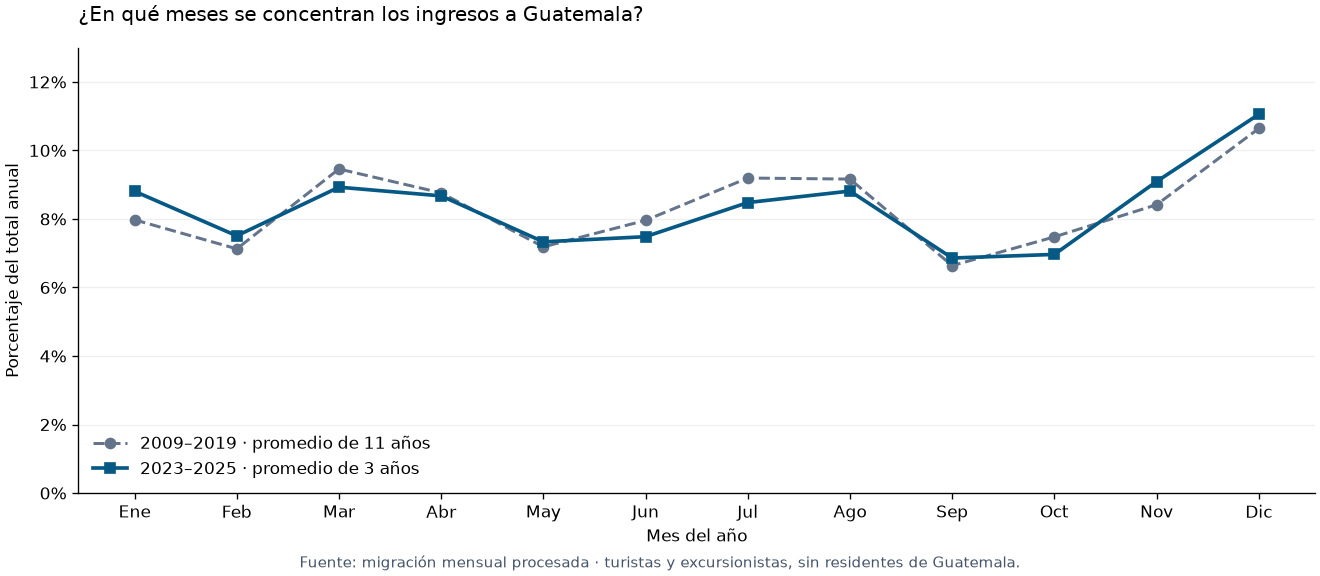

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

meses_grafico = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
figura, eje = plt.subplots(figsize=(11, 4.8), layout="constrained")
eje.plot(perfil_mensual.index, perfil_mensual["2009–2019"],
         label="2009–2019 · promedio de 11 años", color="#64748B",
         marker="o", linestyle="--", linewidth=1.8)
eje.plot(perfil_mensual.index, perfil_mensual["2023–2025"],
         label="2023–2025 · promedio de 3 años", color="#075985",
         marker="s", linewidth=2.2)
eje.set_title("¿En qué meses se concentran los ingresos a Guatemala?", loc="left", pad=16)
eje.set_xlabel("Mes del año")
eje.set_ylabel("Porcentaje del total anual")
eje.set_xticks(range(1, 13), meses_grafico)
eje.set_ylim(0, 13)
eje.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
eje.grid(axis="y", alpha=0.2)
eje.spines[["top", "right"]].set_visible(False)
eje.legend(loc="lower left", frameon=False)
figura.supxlabel("Fuente: migración mensual procesada · turistas y excursionistas, sin residentes de Guatemala.",
                 fontsize=9, color="#475569")
display(figura)
plt.close(figura)


### **3.3. Enero y febrero por año**

Se muestra la participación de los dos meses que interesan al proyecto, con el mismo denominador anual. Los porcentajes se redondean solamente para mostrarlos; se conserva la precisión de los cálculos.


In [8]:
enero_febrero = (
    estacionalidad.loc[estacionalidad["mes"].isin([1, 2])]
    .pivot(index="anio", columns="mes", values="participacion_pct")
    .rename(columns={1: "Enero (% del año)", 2: "Febrero (% del año)"})
    .rename_axis(index="Año", columns=None)
)
display(enero_febrero.round(2))


,Enero (% del año),Febrero (% del año)
Año,,
2009,7.64,7.11
2010,7.48,6.93
2011,7.68,7.04
2012,7.89,7.35
2013,7.28,6.68
2014,8.21,7.11
2015,8.25,7.24
2016,8.49,7.49
2017,8.03,7.46


### **3.4. Lectura de los resultados**

Diciembre tiene la mayor participación promedio y septiembre la menor en ambos períodos. Esto muestra coincidencias en la forma general, pero no significa que los meses conserven exactamente el mismo peso.

En el período reciente, enero pasa de 7,98 % a 8,81 % del total anual, una diferencia de 0,83 puntos porcentuales. Febrero pasa de 7,13 % a 7,51 %, una diferencia de 0,38 puntos. Además, febrero varía entre 6,81 % y 8,12 % en los tres años recientes, por lo que su promedio no describe por igual todos los años.

Bajo estos resultados, considero que la historia anterior a la pandemia puede mantenerse como referencia, pero no copiaría sus porcentajes directamente para estimar Atitlán ni uniría todos los años en un ajuste continuo. El tramo 2023-2025 sigue siendo el candidato principal para estudiar el comportamiento reciente. Todavía no se selecciona un modelo ni se afirma que la historia antigua mejore sus estimaciones; eso requerirá validación.


## **4. Modelo y validación de la referencia nacional**

### **4.1. Períodos para desarrollar y evaluar los modelos**

La similitud entre los perfiles mensuales permite seguir explorando la estacionalidad, pero no demuestra que ambos períodos sean intercambiables ni que un modelo vaya a funcionar bien. Primero se fija cómo se evaluarán los candidatos, antes de calcular sus errores.

Para la primera comparación se utiliza el tramo reciente de migración, sin pandemia y con la metodología de 2023 en adelante. El período 2009-2019 se conserva como referencia histórica; todavía no se incorpora al entrenamiento ni se concatena con los años recientes.

| Uso | Período | Cantidad | Propósito |
|---|---|---|---|
| Entrenamiento inicial | Enero de 2023 a diciembre de 2024 | 24 meses | Ajustar los candidatos sin utilizar las cantidades de 2025. |
| Validación | Enero a diciembre de 2025 | 12 meses | Comparar los candidatos sobre un año completo, incluidos diciembre y los meses de menor demanda. |
| Evaluación posterior | Enero a junio de 2026 | 6 meses | Comprobar el candidato elegido después de reajustarlo con 2023-2025, sin volver a elegirlo por su resultado en 2026. |

Los 24 meses iniciales contienen solo dos ciclos anuales. Esto limita la complejidad que podemos justificar y se tendrá presente al elegir los modelos. El error de 2025 corresponde a validación y selección, no a una prueba final independiente de esa selección. Los seis meses de 2026 no representan un año completo.


In [9]:
periodos_nacionales = {
    "entrenamiento_inicial": ("2023-01-01", "2024-12-01"),
    "validacion": ("2025-01-01", "2025-12-01"),
    "evaluacion_posterior": ("2026-01-01", "2026-06-01"),
}
series_nacionales = {}
filas_periodos = []

for nombre, (inicio_periodo, fin_periodo) in periodos_nacionales.items():
    serie = (
        migracion.loc[migracion["fecha"].between(inicio_periodo, fin_periodo),
                      ["fecha", "viajeros"]]
        .set_index("fecha")["viajeros"].copy()
    )
    fechas_esperadas = pd.date_range(inicio_periodo, fin_periodo, freq="MS")
    assert serie.index.equals(fechas_esperadas), f"Calendario incompleto o repetido: {nombre}"
    assert serie.notna().all() and serie.gt(0).all(), f"Cantidades faltantes o no positivas: {nombre}"
    series_nacionales[nombre] = serie
    filas_periodos.append({
        "uso": nombre,
        "primer_mes": serie.index.min().strftime("%Y-%m"),
        "ultimo_mes": serie.index.max().strftime("%Y-%m"),
        "meses": len(serie),
        "faltantes": int(serie.isna().sum()),
    })

assert series_nacionales["entrenamiento_inicial"].index.max() < series_nacionales["validacion"].index.min()
assert series_nacionales["validacion"].index.max() < series_nacionales["evaluacion_posterior"].index.min()
display(pd.DataFrame(filas_periodos))


,uso,primer_mes,ultimo_mes,meses,faltantes
0,entrenamiento_inicial,2023-01,2024-12,24,0
1,validacion,2025-01,2025-12,12,0
2,evaluacion_posterior,2026-01,2026-06,6,0


### **4.2. Criterios para la próxima comparación**

- **Mismas condiciones:** los candidatos se ajustarán hasta diciembre de 2024 y estimarán los doce meses de 2025 sin recibir sus cantidades reales durante ese pronóstico. Esta prueba mide un horizonte nacional de doce meses; no equivale a reconstruir el hueco municipal de dos meses.
- **Referencia sencilla:** antes de incorporar complejidad se calculará qué ocurre al usar, para cada mes, la cantidad del mismo mes del año anterior. Así podremos comprobar si el modelo aporta una mejora frente a una referencia estacional comprensible.
- **Medición del error:** se reportarán MAE y RMSE en unidades de ingresos y MASE como error escalado, junto con una tabla de valores observados y estimados por mes. Ninguna transformación o ajuste se calculará utilizando las cantidades reservadas para validar o evaluar.
- **Reajuste y comprobación:** una vez elegido el candidato con 2025, se reajustará con enero de 2023 a diciembre de 2025 y se evaluará en enero-junio de 2026. Si su resultado no es satisfactorio, se documentará; no se reutilizará esa misma evaluación como prueba independiente después de modificar el modelo.

La migración de enero y febrero de 2026 ya está observada. Evaluar un pronóstico nacional en esos meses sirve para estudiar la referencia, pero no obliga a reemplazar sus valores reales cuando estimemos las visitas de Atitlán. La relación y el error municipal se revisarán por separado en la fase 5.

Hasta la sección 4.2 solo se preparan los períodos y el protocolo. Las siguientes secciones calculan la referencia sencilla; no se ajustan todavía modelos más complejos.


### **4.3. Referencia estacional y definición de MASE**

La referencia sencilla, conocida como **ingenua estacional**, utiliza la cantidad del mismo mes del año anterior. Para estimar enero-diciembre de 2025 desde diciembre de 2024, repetimos las doce cantidades observadas de 2024 sin utilizar los valores reales de 2025.

**MASE** significa error absoluto medio escalado. Para calcularlo, primero comparamos cada mes de 2024 con el mismo mes de 2023 y obtenemos el promedio de sus diferencias absolutas. Ese promedio representa el error de la regla sencilla dentro del entrenamiento y será nuestra escala de referencia.

Después dividimos el MAE que obtiene cada modelo sobre 2025 entre esa escala. De esta forma expresamos su error en relación con la referencia del entrenamiento. La escala se calcula únicamente con 2023-2024 y se mantiene igual para todos los candidatos evaluados sobre 2025.

- **MASE menor que 1:** el error medio de validación es menor que el error de referencia calculado dentro del entrenamiento.
- **MASE igual a 1:** coincide con esa escala de referencia.
- **MASE mayor que 1:** supera esa escala.

Esto no significa automáticamente que un candidato supere a la referencia sobre 2025. Para esa comparación directa se contrastarán ambos resultados en los mismos meses. La propia referencia también tendrá un MASE de validación, que no necesariamente será uno. MASE no es un porcentaje.

Se sigue la definición estacional de [Forecasting: Principles and Practice, sección 5.8](https://otexts.com/fpp3/toolbox.html#scaled-errors).


In [10]:
import numpy as np


def escala_mase_estacional(entrenamiento, periodo=12):
    """Calcula la escala con diferencias estacionales solo del entrenamiento."""
    valores = np.asarray(entrenamiento, dtype=float)
    if not isinstance(periodo, int) or periodo < 1:
        raise ValueError("El período estacional debe ser un entero positivo.")
    if valores.ndim != 1 or len(valores) <= periodo:
        raise ValueError("Se requiere más de un ciclo para calcular la escala de MASE.")
    if not np.isfinite(valores).all():
        raise ValueError("El entrenamiento contiene faltantes o valores no finitos.")
    escala = float(np.mean(np.abs(valores[periodo:] - valores[:-periodo])))
    if escala <= 0:
        raise ValueError("MASE no está definido: la escala estacional es cero.")
    return escala


def evaluar_pronostico(observado, estimado, escala):
    """Evalúa series alineadas usando una escala de entrenamiento ya fijada."""
    if not observado.index.equals(estimado.index):
        raise ValueError("Los valores observados y estimados deben compartir las mismas fechas.")
    reales = np.asarray(observado, dtype=float)
    predichos = np.asarray(estimado, dtype=float)
    if len(reales) == 0 or not np.isfinite(reales).all() or not np.isfinite(predichos).all():
        raise ValueError("La evaluación requiere cantidades finitas y sin faltantes.")
    if not np.isfinite(escala) or escala <= 0:
        raise ValueError("La escala de MASE debe ser finita y positiva.")
    errores = reales - predichos
    mae = float(np.mean(np.abs(errores)))
    return {"MAE": mae, "RMSE": float(np.sqrt(np.mean(errores ** 2))), "MASE": mae / escala}


entrenamiento_nacional = series_nacionales["entrenamiento_inicial"]
validacion_nacional = series_nacionales["validacion"]
escala_mase_nacional = escala_mase_estacional(entrenamiento_nacional, periodo=12)

diferencias_escala = pd.DataFrame({
    "ingresos_2023": entrenamiento_nacional.iloc[:12].to_numpy(dtype=float),
    "ingresos_2024": entrenamiento_nacional.iloc[12:].to_numpy(dtype=float),
}, index=range(1, 13))
diferencias_escala.index.name = "mes"
diferencias_escala["diferencia_absoluta"] = (
    diferencias_escala["ingresos_2024"] - diferencias_escala["ingresos_2023"]
).abs()
display(diferencias_escala.round(2))
display(pd.DataFrame([{
    "escala_MASE_ingresos": escala_mase_nacional,
    "comparaciones_estacionales": len(diferencias_escala),
    "periodo_entrenamiento": "2023–2024",
}]).round(2))


,ingresos_2023,ingresos_2024,diferencia_absoluta
mes,,,
1,258166.19,292731.87,34565.68
2,198751.86,265990.67,67238.82
3,251839.50,322310.39,70470.89
4,283179.26,240988.82,42190.44
5,213191.04,238807.95,25616.92
6,224580.17,234781.23,10201.05
7,257626.95,266974.96,9348.00
8,264514.09,282101.83,17587.74
9,218486.48,215658.81,2827.67


,escala_MASE_ingresos,comparaciones_estacionales,periodo_entrenamiento
0,37220.45,12,2023–2024


### **4.4. Evaluación de la referencia sobre 2025**

Se calcula el error mensual como observado menos estimado. Un resultado positivo indica que la referencia quedó por debajo del valor real; uno negativo indica que lo sobreestimó. MAE resume el tamaño medio del error y RMSE da más peso a los errores grandes. Ambos se expresan en ingresos; MASE utiliza la escala calculada arriba.


In [11]:
assert len(validacion_nacional) == 12, "Esta referencia cubre doce meses desde el cierre de 2024."
prediccion_referencia = pd.Series(
    entrenamiento_nacional.iloc[-12:].to_numpy(dtype=float),
    index=validacion_nacional.index,
    name="estimado_referencia",
)
comparacion_referencia = pd.DataFrame({
    "observado": validacion_nacional.astype(float),
    "estimado_referencia": prediccion_referencia,
})
comparacion_referencia["error"] = (
    comparacion_referencia["observado"] - comparacion_referencia["estimado_referencia"]
)
comparacion_referencia["error_absoluto"] = comparacion_referencia["error"].abs()
metricas_referencia = evaluar_pronostico(
    validacion_nacional, prediccion_referencia, escala_mase_nacional
)
resultados_validacion = pd.DataFrame([{
    "modelo": "Ingenua estacional (mismo mes de 2024)",
    "periodo": "Enero–diciembre de 2025",
    **metricas_referencia,
}])
display(comparacion_referencia.round(2))
display(resultados_validacion.round(3))


,observado,estimado_referencia,error,error_absoluto
fecha,,,,
2025-01-01,289543.60,292731.87,-3188.27,3188.27
2025-02-01,254428.89,265990.67,-11561.79,11561.79
2025-03-01,278538.25,322310.39,-43772.14,43772.14
2025-04-01,300287.69,240988.82,59298.87,59298.87
2025-05-01,247981.93,238807.95,9173.97,9173.97
2025-06-01,254190.10,234781.23,19408.87,19408.87
2025-07-01,283388.70,266974.96,16413.74,16413.74
2025-08-01,293780.52,282101.83,11678.69,11678.69
2025-09-01,218069.51,215658.81,2410.70,2410.70


,modelo,periodo,MAE,RMSE,MASE
0,Ingenua estacional (mismo mes de 2024),Enero–diciembre de 2025,16241.422,23389.837,0.436


### **4.5. Comparación visual y uso posterior**

El gráfico contrasta los ingresos observados de 2025 con la referencia generada desde diciembre de 2024. No representa las visitas municipales de Atitlán.


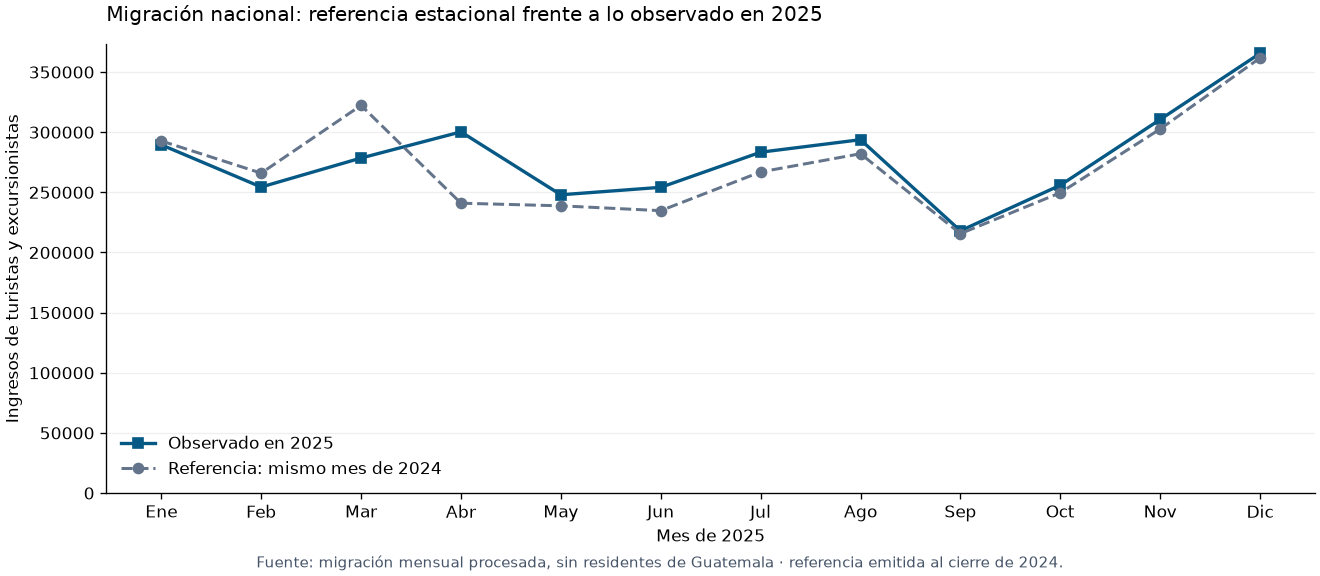

In [12]:
figura_referencia, eje_referencia = plt.subplots(figsize=(11, 4.8), layout="constrained")
eje_referencia.plot(range(1, 13), comparacion_referencia["observado"],
                    label="Observado en 2025", color="#075985", marker="s", linewidth=2)
eje_referencia.plot(range(1, 13), comparacion_referencia["estimado_referencia"],
                    label="Referencia: mismo mes de 2024", color="#64748B",
                    marker="o", linestyle="--", linewidth=1.8)
eje_referencia.set_title("Migración nacional: referencia estacional frente a lo observado en 2025", loc="left", pad=14)
eje_referencia.set_xlabel("Mes de 2025")
eje_referencia.set_ylabel("Ingresos de turistas y excursionistas")
eje_referencia.set_xticks(range(1, 13), meses_grafico)
eje_referencia.set_ylim(bottom=0)
eje_referencia.ticklabel_format(axis="y", style="plain")
eje_referencia.grid(axis="y", alpha=0.2)
eje_referencia.spines[["top", "right"]].set_visible(False)
eje_referencia.legend(loc="lower left", frameon=False)
figura_referencia.supxlabel("Fuente: migración mensual procesada, sin residentes de Guatemala · referencia emitida al cierre de 2024.",
                           fontsize=9, color="#475569")
display(figura_referencia)
plt.close(figura_referencia)


La tabla `resultados_validacion` queda como punto de comparación para los siguientes candidatos. Se conservarán las mismas fechas y la misma escala de MASE al evaluar cada uno. Un MASE inferior al de la referencia significará un MAE menor sobre ese mismo período.

Cuando se reajuste el candidato con 2023-2025, la escala para evaluar 2026 se recalculará solo con ese nuevo entrenamiento y se compartirá con su referencia. Las diferencias de escala y horizonte se documentarán; no se compararán ambos períodos como si fueran la misma prueba. MASE municipal requeriría su propia referencia local; esta escala nacional no se trasladará a Atitlán.

En este bloque se evaluó únicamente la regla sencilla. No se entrenaron ARIMA, LightGBM ni redes neuronales y no se utilizaron los valores de 2026 para seleccionar candidatos.


### **4.6. Diagnóstico antes de elegir ARMA, ARIMA o SARIMA**

Se revisan únicamente los 24 meses de entrenamiento, enero de 2023 a diciembre de 2024. No se usan las cantidades de validación de 2025 ni las de evaluación de 2026 para calcular estas pruebas. La comparación histórica de la sección 3 es descriptiva; no sustituye este diagnóstico sobre el entrenamiento.

Primero se observa la evolución mensual y una media móvil de seis meses para reconocer cambios de nivel. Esa media es una ayuda visual, no una estimación formal de tendencia. También se muestran ACF y PACF: la ACF resume la relación con meses anteriores y la PACF busca separar la relación directa con cada rezago de la que pasa por meses intermedios.

La estacionalidad anual sugiere un período de doce meses. Sin embargo, en este entrenamiento solo hay dos ciclos y la ACF en el rezago 12 dispone de doce pares de observaciones. La PACF se limita a diez rezagos por el tamaño de muestra. Estos gráficos orientan órdenes candidatos; no determinan una configuración exacta.


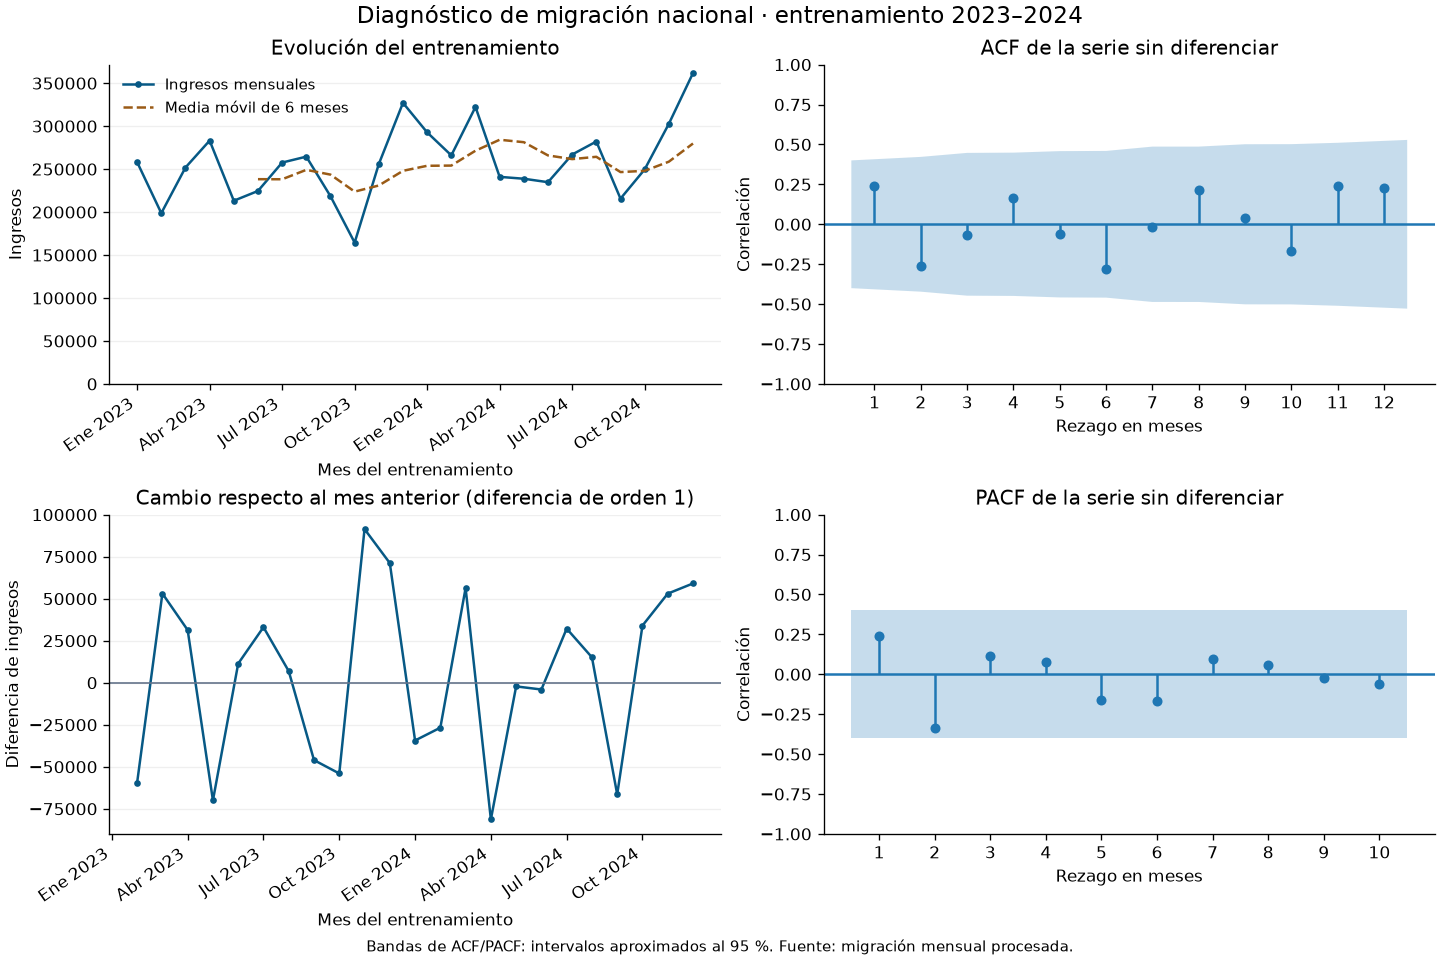

In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie_diagnostico = entrenamiento_nacional.astype(float)
figura_diagnostico, ejes_diagnostico = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")

etiquetas_diagnostico = [
    f"{meses_grafico[fecha.month - 1]} {fecha.year}"
    for fecha in serie_diagnostico.index[::3]
]
posiciones_diagnostico = np.arange(len(serie_diagnostico))
ejes_diagnostico[0, 0].plot(posiciones_diagnostico, serie_diagnostico.to_numpy(),
                           marker="o", markersize=3, color="#075985", label="Ingresos mensuales")
ejes_diagnostico[0, 0].plot(posiciones_diagnostico,
                           serie_diagnostico.rolling(6, min_periods=6).mean().to_numpy(),
                           color="#9A5B16", linestyle="--", label="Media móvil de 6 meses")
ejes_diagnostico[0, 0].set_title("Evolución del entrenamiento")
ejes_diagnostico[0, 0].set_ylabel("Ingresos")
ejes_diagnostico[0, 0].set_ylim(bottom=0)
ejes_diagnostico[0, 0].legend(frameon=False, fontsize=9)

ejes_diagnostico[1, 0].plot(posiciones_diagnostico,
                           serie_diagnostico.diff().to_numpy(), marker="o", markersize=3, color="#075985")
ejes_diagnostico[1, 0].axhline(0, color="#64748B", linewidth=1)
ejes_diagnostico[1, 0].set_title("Cambio respecto al mes anterior (diferencia de orden 1)")
ejes_diagnostico[1, 0].set_ylabel("Diferencia de ingresos")
for eje in ejes_diagnostico[:, 0]:
    eje.set_xticks(posiciones_diagnostico[::3], etiquetas_diagnostico, rotation=35, ha="right")
    eje.set_xlabel("Mes del entrenamiento")
    eje.grid(axis="y", alpha=0.2)

plot_acf(serie_diagnostico, lags=12, zero=False, alpha=0.05,
         ax=ejes_diagnostico[0, 1], title="ACF de la serie sin diferenciar")
plot_pacf(serie_diagnostico, lags=10, zero=False, alpha=0.05, method="ywm",
          ax=ejes_diagnostico[1, 1], title="PACF de la serie sin diferenciar")
for eje, maximo in zip(ejes_diagnostico[:, 1], [12, 10]):
    eje.set_xlabel("Rezago en meses")
    eje.set_ylabel("Correlación")
    eje.set_xticks(range(1, maximo + 1))
for eje in ejes_diagnostico.flat:
    eje.spines[["top", "right"]].set_visible(False)
figura_diagnostico.suptitle("Diagnóstico de migración nacional · entrenamiento 2023–2024", fontsize=14)
figura_diagnostico.supxlabel("Bandas de ACF/PACF: intervalos aproximados al 95 %. Fuente: migración mensual procesada.", fontsize=9)
display(figura_diagnostico)
plt.close(figura_diagnostico)


### **4.7. Pruebas ADF y KPSS**

Se contrastan dos pruebas complementarias con significancia del 5 %:

- **ADF:** parte de la hipótesis de raíz unitaria. Un valor p menor que 0,05 permite rechazarla bajo la especificación utilizada; no demuestra por sí solo que toda forma de inestabilidad haya desaparecido.
- **KPSS:** parte de la hipótesis de estacionariedad alrededor de un nivel constante. Un valor p menor que 0,05 aporta evidencia contra esa hipótesis. No rechazarla no equivale a demostrarla.

Se prueban la serie original y su primera diferencia. Ambas pruebas incluyen constante, sin tendencia determinista. ADF selecciona con AIC entre cero y tres rezagos, limitando la cantidad de parámetros por la muestra corta. KPSS utiliza dos rezagos de manera explícita para mantener una especificación breve y común. Los resultados dependen de estas decisiones y de la poca historia disponible.

Estas pruebas no identifican por sí solas raíces unitarias estacionales ni los órdenes exactos de AR o MA. No se aplica una diferencia anual solo porque el patrón se repita. Una diferencia a doce meses dejaría doce datos; combinarla con otra diferencia dejaría once.

Referencias: documentación oficial de [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html) y [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html).


In [14]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

filas_pruebas = []
for nombre, valores in {
    "Original (d=0)": serie_diagnostico,
    "Primera diferencia (d=1)": serie_diagnostico.diff().dropna(),
}.items():
    with warnings.catch_warnings(record=True) as avisos_adf:
        warnings.simplefilter("always")
        warnings.filterwarnings("ignore", category=FutureWarning)
        resultado_adf = adfuller(valores, regression="c", maxlag=3, autolag="AIC")
    with warnings.catch_warnings(record=True) as avisos_kpss:
        warnings.simplefilter("always")
        warnings.filterwarnings("ignore", category=FutureWarning)
        resultado_kpss = kpss(valores, regression="c", nlags=2)

    filas_pruebas.append({
        "serie": nombre, "prueba": "ADF", "meses_entrada": len(valores),
        "observaciones_efectivas": resultado_adf[3],
        "estadistico": resultado_adf[0], "valor_p": resultado_adf[1],
        "rezagos": resultado_adf[2],
        "lectura_al_5_pct": "Se rechaza raíz unitaria" if resultado_adf[1] < 0.05 else "No se rechaza raíz unitaria",
        "avisos": " | ".join(str(aviso.message) for aviso in avisos_adf),
    })
    filas_pruebas.append({
        "serie": nombre, "prueba": "KPSS", "meses_entrada": len(valores),
        "observaciones_efectivas": len(valores),
        "estadistico": resultado_kpss[0], "valor_p": resultado_kpss[1],
        "rezagos": resultado_kpss[2],
        "lectura_al_5_pct": "Se rechaza estacionariedad" if resultado_kpss[1] < 0.05 else "No se rechaza estacionariedad",
        "avisos": " | ".join(str(aviso.message) for aviso in avisos_kpss),
    })
resultados_estacionariedad = pd.DataFrame(filas_pruebas)
display(resultados_estacionariedad.drop(columns="avisos").round(6))
display(resultados_estacionariedad.loc[
    resultados_estacionariedad["avisos"].ne(""), ["serie", "prueba", "avisos"]
])


,serie,prueba,meses_entrada,observaciones_efectivas,estadistico,valor_p,rezagos,lectura_al_5_pct
0,Original (d=0),ADF,24,22,-3.460552,0.009060,1,Se rechaza raíz unitaria
1,Original (d=0),KPSS,24,24,0.321387,0.100000,2,No se rechaza estacionariedad
2,Primera diferencia (d=1),ADF,23,21,-5.371663,0.000004,1,Se rechaza raíz unitaria
3,Primera diferencia (d=1),KPSS,23,23,0.149411,0.100000,2,No se rechaza estacionariedad


,serie,prueba,avisos
1,Original (d=0),KPSS,The test statistic is outside of the range of ...
3,Primera diferencia (d=1),KPSS,The test statistic is outside of the range of ...


### **4.8. Interpretación antes de seleccionar candidatos**

En la serie original, ADF obtiene un valor p aproximado de 0,009 y rechaza la hipótesis de raíz unitaria. KPSS no rechaza la estacionariedad; su valor p real es mayor que 0,10, límite superior que devuelve la tabla de la prueba. Los avisos se conservan en la salida para no interpretar ese límite como una probabilidad exacta.

Bajo estas especificaciones, no encontramos una necesidad clara de aplicar la primera diferencia para corregir una raíz unitaria no estacional. Por eso consideraría **d=0 como punto de partida**, en lugar de diferenciar por costumbre. Que la primera diferencia también pase las pruebas no demuestra que sea necesaria ni que mejore el pronóstico.

La similitud de los perfiles anuales justifica explorar un componente de período **12**, pero no obliga a utilizar **D=1**. Una serie puede tener un patrón estacional estable sin necesitar diferenciación anual. Con dos ciclos, la evidencia para estimar órdenes estacionales es limitada.

En el siguiente paso se discutirán pocos candidatos de bajo orden, incluyendo una alternativa sin componente estacional y otra con él. ACF y PACF orientarán la propuesta, y los resultados sobre 2025 se compararán con la referencia mediante MAE, RMSE y MASE. El diagnóstico no garantiza de antemano que SARIMA sea superior.

Todavía no se ajustaron candidatos ni se seleccionaron órdenes definitivos.


### **4.9. Candidatos de la primera comparación**

Se prueban tres configuraciones pequeñas para representar las alternativas discutidas. No es una búsqueda exhaustiva ni permite concluir cuál familia funciona mejor en general. ACF y PACF no muestran cortes claros que determinen órdenes únicos; los órdenes 1 se utilizan como una primera exploración de baja complejidad.

| Candidato | Configuración | Qué se evalúa |
|---|---|---|
| ARMA | (1,1), equivalente a ARIMA(1,0,1), con constante | Relación de corto plazo con un término autorregresivo y uno de media móvil, sin diferenciar. |
| ARIMA | (1,1,1), sin deriva | La misma estructura corta después de una primera diferencia. Se incluye para contrastarla aunque las pruebas no indiquen que sea necesaria. |
| SARIMA | (0,0,0)(1,0,0) con período 12 y constante | Una relación autorregresiva anual, sin diferencias ni términos cortos, para explorar el aporte estacional con pocos parámetros. |

Se emplea la implementación `ARIMA` de statsmodels para los tres casos, que también admite órdenes estacionales. Se mantienen las restricciones de estacionariedad e invertibilidad. Para facilitar la optimización, se ajustan los ingresos en miles y se devuelven las predicciones a ingresos antes de calcular las métricas. Es un cambio fijo de unidad, no una transformación estimada con los datos reservados.

Los modelos reciben solamente 2023-2024 y generan desde diciembre de 2024 los doce meses de 2025, sin actualizarse con sus valores reales. Se mantienen la misma escala de MASE y la misma referencia del bloque anterior.

Referencia de implementación: [ARIMA en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html).


In [15]:
from statsmodels.tsa.arima.model import ARIMA

especificaciones_candidatos = {
    "ARMA(1,1)": {"order": (1, 0, 1), "seasonal_order": (0, 0, 0, 0), "trend": "c"},
    "ARIMA(1,1,1)": {"order": (1, 1, 1), "seasonal_order": (0, 0, 0, 0), "trend": "n"},
    "SARIMA(0,0,0)(1,0,0)[12]": {"order": (0, 0, 0), "seasonal_order": (1, 0, 0, 12), "trend": "c"},
}
factor_unidad = 1000.0
entrenamiento_modelos = entrenamiento_nacional.astype(float).asfreq("MS") / factor_unidad
ajustes_candidatos = {}
predicciones_candidatos = {}
filas_ajuste = []
filas_metricas = resultados_validacion.to_dict("records")
filas_parametros = []

for nombre, especificacion in especificaciones_candidatos.items():
    with warnings.catch_warnings(record=True) as avisos_ajuste:
        warnings.simplefilter("always")
        ajuste = ARIMA(
            entrenamiento_modelos,
            **especificacion,
            enforce_stationarity=True,
            enforce_invertibility=True,
        ).fit(method_kwargs={"maxiter": 300})

    prediccion = ajuste.forecast(steps=len(validacion_nacional)) * factor_unidad
    assert prediccion.index.equals(validacion_nacional.index), "Fechas de pronóstico incorrectas."
    convergio = bool(ajuste.mle_retvals.get("converged", False))
    parametros_finitos = bool(np.isfinite(np.asarray(ajuste.params)).all())
    pronostico_valido = bool(np.isfinite(prediccion.to_numpy()).all() and prediccion.ge(0).all())
    apto_comparacion = convergio and parametros_finitos and pronostico_valido
    filas_ajuste.append({
        "modelo": nombre,
        "convergio": convergio,
        "parametros_finitos": parametros_finitos,
        "pronostico_finito_no_negativo": pronostico_valido,
        "cantidad_parametros": len(ajuste.params),
        "avisos": " | ".join(str(aviso.message) for aviso in avisos_ajuste),
        "apto_comparacion_numerica": apto_comparacion,
    })
    ajustes_candidatos[nombre] = ajuste
    for parametro, valor in ajuste.params.items():
        filas_parametros.append({"modelo": nombre, "parametro": parametro, "valor": valor})
    if apto_comparacion:
        predicciones_candidatos[nombre] = prediccion
        filas_metricas.append({
            "modelo": nombre, "periodo": "Enero–diciembre de 2025",
            **evaluar_pronostico(validacion_nacional, prediccion, escala_mase_nacional),
        })

controles_candidatos = pd.DataFrame(filas_ajuste)
parametros_candidatos = pd.DataFrame(filas_parametros)
comparacion_modelos = pd.DataFrame(filas_metricas).sort_values("MASE").reset_index(drop=True)
comparacion_modelos["mejora_MAE_vs_referencia_pct"] = (
    1 - comparacion_modelos["MAE"] / metricas_referencia["MAE"]
) * 100
display(controles_candidatos)
display(parametros_candidatos.round(6))
display(comparacion_modelos.round(3))


,modelo,convergio,parametros_finitos,pronostico_finito_no_negativo,cantidad_parametros,avisos,apto_comparacion_numerica
0,"ARMA(1,1)",True,True,True,4,,True
1,"ARIMA(1,1,1)",True,True,True,3,,True
2,"SARIMA(0,0,0)(1,0,0)[12]",True,True,True,3,,True


,modelo,parametro,valor
0,"ARMA(1,1)",const,259.769953
1,"ARMA(1,1)",ar.L1,-0.259864
2,"ARMA(1,1)",ma.L1,0.773382
3,"ARMA(1,1)",sigma2,1475.515962
4,"ARIMA(1,1,1)",ar.L1,0.335364
5,"ARIMA(1,1,1)",ma.L1,-0.908469
6,"ARIMA(1,1,1)",sigma2,1879.898487
7,"SARIMA(0,0,0)(1,0,0)[12]",const,258.010948
8,"SARIMA(0,0,0)(1,0,0)[12]",ar.S.L12,0.452383
9,"SARIMA(0,0,0)(1,0,0)[12]",sigma2,1468.713451


,modelo,periodo,MAE,RMSE,MASE,mejora_MAE_vs_referencia_pct
0,Ingenua estacional (mismo mes de 2024),Enero–diciembre de 2025,16241.422,23389.837,0.436,0.000
1,"SARIMA(0,0,0)(1,0,0)[12]",Enero–diciembre de 2025,20937.372,27616.068,0.563,-28.913
2,"ARIMA(1,1,1)",Enero–diciembre de 2025,29001.750,37161.332,0.779,-78.567
3,"ARMA(1,1)",Enero–diciembre de 2025,29202.067,40328.300,0.785,-79.800


### **4.10. Valores reales y predicciones de cada candidato**

Cada panel utiliza la misma escala y muestra una configuración frente a las cantidades reales y a la referencia estacional. La tabla conserva los resultados mensuales para poder revisar dónde se producen los errores. Los valores no se redondean antes de calcular métricas ni se recortan para mejorar artificialmente la comparación.


,observado,referencia_estacional,"ARMA(1,1)","ARIMA(1,1,1)","SARIMA(0,0,0)(1,0,0)[12]"
2025-01-01,289543.60,292731.87,300236.87,302308.60,273718.11
2025-02-01,254428.89,265990.67,249254.06,282374.22,261620.84
2025-03-01,278538.25,322310.39,262502.66,275688.95,287098.93
2025-04-01,300287.69,240988.82,259059.82,273446.95,250310.42
2025-05-01,247981.93,238807.95,259954.49,272695.07,249323.84
2025-06-01,254190.10,234781.23,259722.00,272442.91,247502.21
2025-07-01,283388.70,266974.96,259782.41,272358.35,262066.11
2025-08-01,293780.52,282101.83,259766.71,272329.99,268909.26
2025-09-01,218069.51,215658.81,259770.79,272320.48,238851.55
2025-10-01,255920.93,249665.70,259769.73,272317.29,254235.70


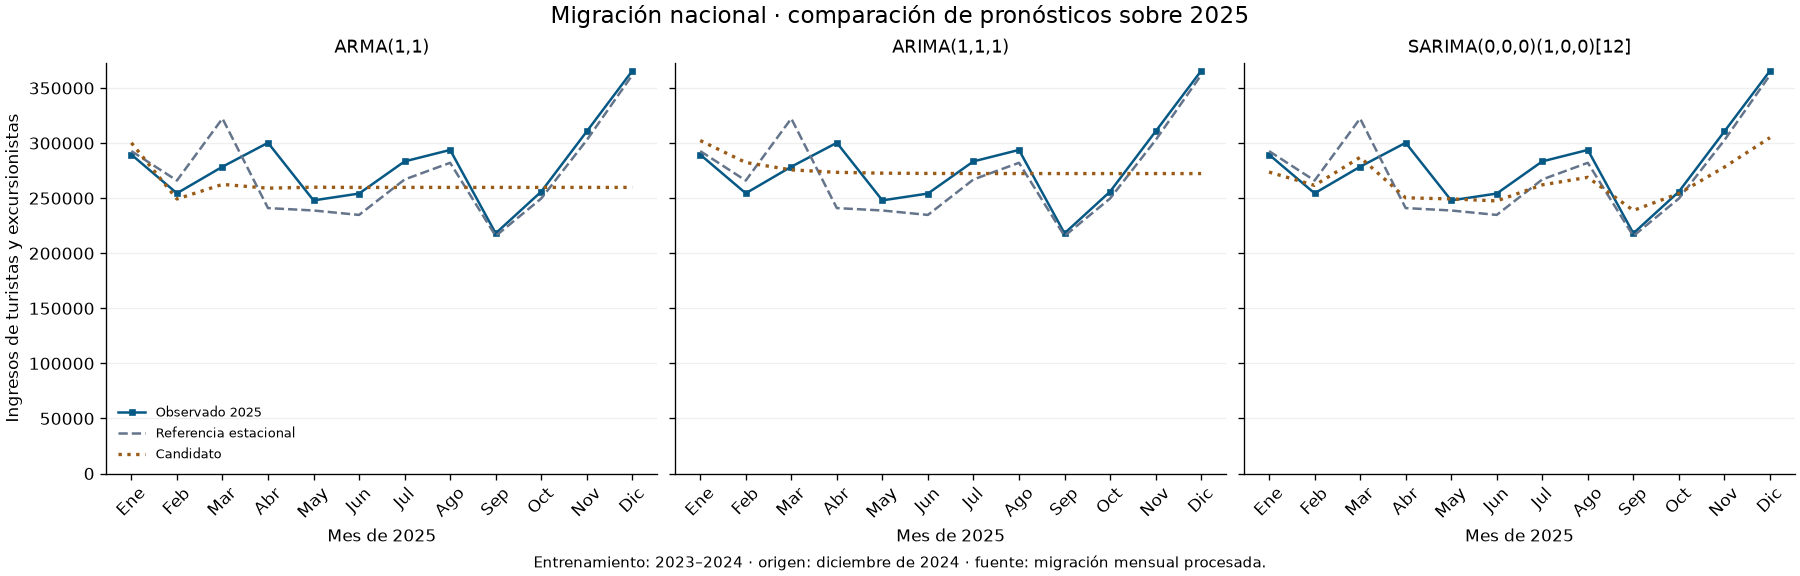

In [16]:
detalle_modelos = pd.DataFrame({
    "observado": validacion_nacional.astype(float),
    "referencia_estacional": prediccion_referencia,
    **predicciones_candidatos,
})
display(detalle_modelos.round(2))

figura_modelos, ejes_modelos = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True, layout="constrained")
for eje, nombre in zip(ejes_modelos, especificaciones_candidatos):
    eje.plot(range(1, 13), detalle_modelos["observado"], label="Observado 2025", color="#075985", marker="s", markersize=3)
    eje.plot(range(1, 13), detalle_modelos["referencia_estacional"], label="Referencia estacional", color="#64748B", linestyle="--")
    if nombre in predicciones_candidatos:
        eje.plot(range(1, 13), detalle_modelos[nombre], label="Candidato", color="#9A5B16", linestyle=":", linewidth=2)
    eje.set_title(nombre, fontsize=11)
    eje.set_xticks(range(1, 13), meses_grafico, rotation=45)
    eje.set_xlabel("Mes de 2025")
    eje.set_ylim(bottom=0)
    eje.grid(axis="y", alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)
ejes_modelos[0].set_ylabel("Ingresos de turistas y excursionistas")
ejes_modelos[0].legend(frameon=False, fontsize=8, loc="lower left")
figura_modelos.suptitle("Migración nacional · comparación de pronósticos sobre 2025", fontsize=14)
figura_modelos.supxlabel("Entrenamiento: 2023–2024 · origen: diciembre de 2024 · fuente: migración mensual procesada.", fontsize=9)
display(figura_modelos)
plt.close(figura_modelos)


### **4.11. Revisión de los residuos de entrenamiento**

Se inspeccionan los errores de predicción de un paso dentro del entrenamiento, estandarizados por su desviación prevista. Para evitar la inicialización difusa, se aparta el mayor entre el período de inicialización indicado por el ajuste y el orden de diferenciación. No se retiran los errores grandes.

La prueba Ljung–Box revisa conjuntamente la autocorrelación hasta seis meses; se descuentan como grados de libertad los términos AR y MA, tanto cortos como estacionales. Un valor p menor que 0,05 aporta evidencia de autocorrelación pendiente. No rechazar no demuestra que el modelo sea correcto ni sustituye la evaluación de 2025. Con 23 o 24 errores, la prueba es solo orientativa y no confirma que se haya capturado bien una dependencia anual.

Referencia: [Ljung–Box en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).


,modelo,errores_revisados,media_error_estandarizado,rezago_Ljung_Box,grados_modelo,valor_p_Ljung_Box,lectura_al_5_pct
0,"ARMA(1,1)",24,-0.0072,6,2,0.4656,No se detecta autocorrelación con esta prueba
1,"ARIMA(1,1,1)",23,0.1867,6,2,0.0614,No se detecta autocorrelación con esta prueba
2,"SARIMA(0,0,0)(1,0,0)[12]",24,0.1087,6,1,0.5701,No se detecta autocorrelación con esta prueba


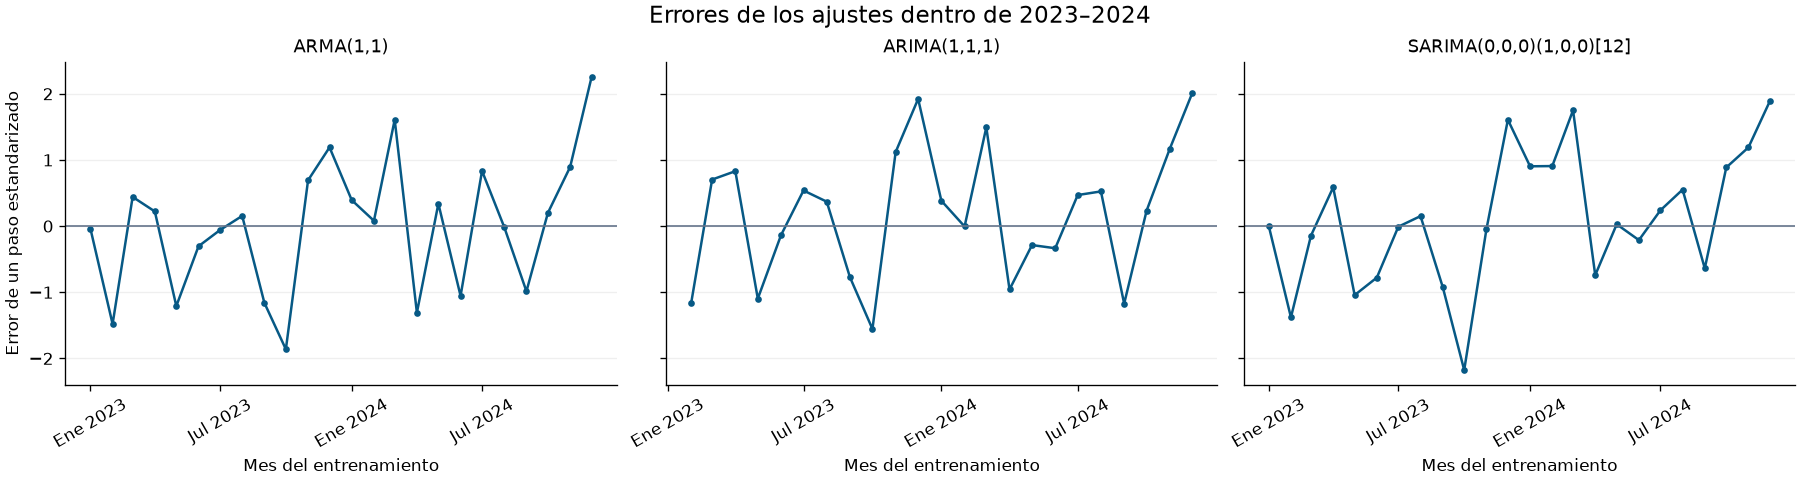

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox

filas_residuos = []
residuos_candidatos = {}
for nombre, ajuste in ajustes_candidatos.items():
    especificacion = especificaciones_candidatos[nombre]
    descarte_inicial = max(int(ajuste.loglikelihood_burn), especificacion["order"][1])
    residuos = pd.Series(
        ajuste.filter_results.standardized_forecasts_error[0],
        index=entrenamiento_modelos.index,
    ).iloc[descarte_inicial:]
    assert np.isfinite(residuos.to_numpy()).all(), "Hay errores estandarizados no finitos."
    residuos_candidatos[nombre] = residuos
    grados_modelo = sum(especificacion["order"][i] for i in (0, 2)) + sum(
        especificacion["seasonal_order"][i] for i in (0, 2)
    )
    prueba_lb = acorr_ljungbox(residuos, lags=[6], model_df=grados_modelo, return_df=True)
    valor_p_lb = float(prueba_lb.loc[6, "lb_pvalue"])
    filas_residuos.append({
        "modelo": nombre,
        "errores_revisados": len(residuos),
        "media_error_estandarizado": residuos.mean(),
        "rezago_Ljung_Box": 6,
        "grados_modelo": grados_modelo,
        "valor_p_Ljung_Box": valor_p_lb,
        "lectura_al_5_pct": "Se detecta autocorrelación" if valor_p_lb < 0.05 else "No se detecta autocorrelación con esta prueba",
    })
diagnostico_residuos = pd.DataFrame(filas_residuos)
display(diagnostico_residuos.round(4))

figura_residuos, ejes_residuos = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout="constrained")
for eje, (nombre, residuos) in zip(ejes_residuos, residuos_candidatos.items()):
    eje.plot(residuos.index, residuos.to_numpy(), marker="o", markersize=3, color="#075985")
    eje.axhline(0, color="#64748B", linewidth=1)
    eje.set_title(nombre, fontsize=11)
    eje.set_xticks(entrenamiento_modelos.index[::6],
                   [f"{meses_grafico[f.month - 1]} {f.year}" for f in entrenamiento_modelos.index[::6]], rotation=30)
    eje.set_xlabel("Mes del entrenamiento")
    eje.grid(axis="y", alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)
ejes_residuos[0].set_ylabel("Error de un paso estandarizado")
figura_residuos.suptitle("Errores de los ajustes dentro de 2023–2024", fontsize=14)
display(figura_residuos)
plt.close(figura_residuos)


### **4.12. Resultado de esta comparación**

Los tres ajustes convergieron, sin avisos del optimizador, con parámetros finitos y pronósticos no negativos. Ljung–Box no detecta autocorrelación al 5 % bajo la especificación utilizada; eso no garantiza un buen pronóstico ni permite confirmar la ausencia de dependencia estacional con tan pocos errores.

En validación, la referencia estacional obtiene MAE de aproximadamente 16.241 ingresos y MASE de 0,436. SARIMA alcanza MAE de 20.937 y MASE de 0,563; ARIMA obtiene MAE de 29.002 y MASE de 0,779; ARMA alcanza MAE de 29.202 y MASE de 0,785.

Por tanto, **la referencia estacional es la mejor de las cuatro alternativas en esta prueba**. SARIMA resulta el mejor de los tres candidatos ajustados, pero no mejora la referencia. Que todos tengan MASE menor que uno no cambia esa conclusión: comparten la escala del entrenamiento y deben compararse entre sí sobre 2025.

Esto no demuestra que cualquier ARMA, ARIMA o SARIMA sea inferior, sino que estas tres configuraciones no mejoran la regla sencilla bajo el entrenamiento y horizonte definidos. Esta primera tanda se conserva como referencia para distinguir el efecto de las configuraciones que se exploren después. Tampoco se ha estimado todavía el error municipal de Atitlán.

La evaluación de enero-junio de 2026 queda pendiente. En este bloque no se reajustó con 2025 ni se utilizó 2026 para modificar candidatos o decidir nuevas configuraciones.


### **4.13. Segunda tanda: búsqueda acotada de órdenes**

Se amplía la comparación con una lista pequeña de configuraciones, definida antes de revisar sus nuevos errores. La pregunta es si la primera tanda quedó limitada por los órdenes elegidos. No se busca garantizar que un modelo más complejo supere a la referencia.

| Familia | Órdenes de corto plazo | Diferenciación | Componente anual | Constante o deriva | Configuraciones |
|---|---|---|---|---|---|
| ARMA | p y q entre 0 y 2, con p+q ≤ 2 | d=0 | Ninguno | Constante | 6 |
| ARIMA | p y q entre 0 y 2, con p+q ≤ 2 | d=1 | Ninguno | Sin deriva | 6 |
| SARIMA | p y q entre 0 y 1, con p+q ≤ 1 | d=0 y D=0 | Un término AR anual o un término MA anual, período 12 | Constante | 6 |

Se incluyen dos casos especialmente sencillos: ARMA(0,0), que estima un nivel constante, y ARIMA(0,1,0), que repite la última observación. No se introducen diferencias anuales ni se aumenta el número de términos solo para mejorar el ajuste.

Los 18 ajustes utilizan exclusivamente los 24 meses de 2023-2024, en miles de ingresos, con las mismas restricciones de estacionariedad e invertibilidad y hasta 300 iteraciones. Se registran convergencia, advertencias y AICc. Los ajustes fallidos, no convergentes o con parámetros o AICc no finitos no participan en la selección.

Dentro de cada familia se elige el menor AICc de entrenamiento. No se utiliza el AICc para comparar familias con distinta diferenciación. El AICc penaliza la cantidad de parámetros, con una corrección para muestras pequeñas; no sustituye una prueba de pronóstico. Después se calcula el error de 2025 de un único candidato elegido por familia, con la escala MASE ya fijada.

Esta ampliación se planteó después de observar la primera validación. Por tanto, 2025 sigue siendo un período de desarrollo y selección, no una prueba final libre de esas decisiones. Enero-junio de 2026 permanece reservado.

Referencia: [criterios de información y elección de órdenes en Forecasting: Principles and Practice](https://otexts.com/fpp3/arima.html#information-criteria).


In [18]:
# Lista fijada antes de calcular los errores de la segunda tanda.
configuraciones_tanda_dos = []
for familia, diferenciacion, tendencia in [("ARMA", 0, "c"), ("ARIMA", 1, "n")]:
    for p_corto in range(3):
        for q_corto in range(3):
            if p_corto + q_corto <= 2:
                configuraciones_tanda_dos.append({
                    "familia": familia,
                    "orden": (p_corto, diferenciacion, q_corto),
                    "orden_estacional": (0, 0, 0, 0),
                    "tendencia": tendencia,
                })
for p_corto, q_corto in [(0, 0), (1, 0), (0, 1)]:
    for orden_anual in [(1, 0, 0, 12), (0, 0, 1, 12)]:
        configuraciones_tanda_dos.append({
            "familia": "SARIMA", "orden": (p_corto, 0, q_corto),
            "orden_estacional": orden_anual, "tendencia": "c",
        })

assert len(configuraciones_tanda_dos) == 18
ajustes_tanda_dos = {}
filas_busqueda = []
for identificador, especificacion in enumerate(configuraciones_tanda_dos, start=1):
    registro = {
        "id": identificador, **especificacion,
        "convergio": False, "parametros_finitos": False,
        "AICc": np.nan, "cantidad_parametros": np.nan,
        "apto_seleccion": False, "avisos": "", "fallo": "",
    }
    with warnings.catch_warnings(record=True) as avisos_busqueda:
        warnings.simplefilter("always")
        try:
            ajuste = ARIMA(
                entrenamiento_modelos,
                order=especificacion["orden"],
                seasonal_order=especificacion["orden_estacional"],
                trend=especificacion["tendencia"],
                enforce_stationarity=True,
                enforce_invertibility=True,
            ).fit(method_kwargs={"maxiter": 300})
            registro["convergio"] = bool(ajuste.mle_retvals.get("converged", False))
            registro["parametros_finitos"] = bool(np.isfinite(np.asarray(ajuste.params)).all())
            registro["AICc"] = float(ajuste.aicc)
            registro["cantidad_parametros"] = len(ajuste.params)
            registro["apto_seleccion"] = (
                registro["convergio"] and registro["parametros_finitos"]
                and np.isfinite(registro["AICc"])
            )
            ajustes_tanda_dos[identificador] = ajuste
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as error:
            registro["fallo"] = f"{type(error).__name__}: {error}"
    registro["avisos"] = " | ".join(str(aviso.message) for aviso in avisos_busqueda)
    filas_busqueda.append(registro)

busqueda_tanda_dos = pd.DataFrame(filas_busqueda)
elegibles_tanda_dos = busqueda_tanda_dos.loc[busqueda_tanda_dos["apto_seleccion"]].copy()
assert set(elegibles_tanda_dos["familia"]) == {"ARMA", "ARIMA", "SARIMA"}, "Hay una familia sin ajuste válido."
seleccion_tanda_dos = (
    elegibles_tanda_dos.sort_values(["familia", "AICc", "cantidad_parametros", "id"])
    .groupby("familia", sort=False).head(1).reset_index(drop=True)
)
display(busqueda_tanda_dos.drop(columns=["avisos", "fallo"])
        .sort_values(["familia", "AICc"]).round(3))
display(busqueda_tanda_dos.loc[
    busqueda_tanda_dos["avisos"].ne("") | busqueda_tanda_dos["fallo"].ne(""),
    ["id", "familia", "orden", "orden_estacional", "avisos", "fallo"],
])
display(seleccion_tanda_dos[["id", "familia", "orden", "orden_estacional", "AICc"]].round(3))


,id,familia,orden,orden_estacional,tendencia,convergio,parametros_finitos,AICc,cantidad_parametros,apto_seleccion
8,9,ARIMA,"(0, 1, 2)","(0, 0, 0, 0)",n,True,True,244.425,3,True
11,12,ARIMA,"(2, 1, 0)","(0, 0, 0, 0)",n,True,True,245.372,3,True
7,8,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)",n,True,True,246.175,2,True
10,11,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",n,True,True,247.056,3,True
6,7,ARIMA,"(0, 1, 0)","(0, 0, 0, 0)",n,True,True,247.130,1,True
9,10,ARIMA,"(1, 1, 0)","(0, 0, 0, 0)",n,True,True,249.297,2,True
1,2,ARMA,"(0, 0, 1)","(0, 0, 0, 0)",c,True,True,251.347,3,True
5,6,ARMA,"(2, 0, 0)","(0, 0, 0, 0)",c,True,True,253.164,4,True
0,1,ARMA,"(0, 0, 0)","(0, 0, 0, 0)",c,True,True,253.187,2,True
2,3,ARMA,"(0, 0, 2)","(0, 0, 0, 0)",c,True,True,253.592,4,True


,id,familia,orden,orden_estacional,avisos,fallo
13,14,SARIMA,"(0, 0, 0)","(0, 0, 1, 12)",Too few observations to estimate starting para...,
15,16,SARIMA,"(1, 0, 0)","(0, 0, 1, 12)",Too few observations to estimate starting para...,
17,18,SARIMA,"(0, 0, 1)","(0, 0, 1, 12)",Too few observations to estimate starting para...,


,id,familia,orden,orden_estacional,AICc
0,9,ARIMA,"(0, 1, 2)","(0, 0, 0, 0)",244.425
1,2,ARMA,"(0, 0, 1)","(0, 0, 0, 0)",251.347
2,17,SARIMA,"(0, 0, 1)","(1, 0, 0, 12)",252.326


### **4.14. Validación de los elegidos por AICc**

Solo después de elegir los órdenes se generan sus doce pronósticos de 2025 desde el cierre de 2024. No se actualiza el modelo con las observaciones reales de validación. La comparación conserva la referencia estacional, los resultados de la primera tanda y el origen de cada candidato.

La columna de mejora expresa la reducción del MAE frente a la referencia sobre 2025. Un valor negativo significa que el error es mayor. No se reemplazan ni se recortan predicciones para favorecer las métricas.


In [19]:
predicciones_tanda_dos = {}
ajustes_seleccionados_tanda_dos = {}
filas_validacion_tanda_dos = []
for fila in seleccion_tanda_dos.to_dict("records"):
    ajuste = ajustes_tanda_dos[fila["id"]]
    nombre = f"{fila['familia']} · orden {fila['orden']} · anual {fila['orden_estacional']}"
    prediccion = ajuste.forecast(steps=12) * factor_unidad
    assert prediccion.index.equals(validacion_nacional.index), "Fechas de pronóstico incorrectas."
    assert np.isfinite(prediccion.to_numpy()).all(), f"Pronóstico no finito: {nombre}"
    assert prediccion.ge(0).all(), f"Pronóstico negativo: {nombre}; revisar sin recortar."
    predicciones_tanda_dos[nombre] = prediccion
    ajustes_seleccionados_tanda_dos[nombre] = ajuste
    filas_validacion_tanda_dos.append({
        "modelo": nombre, "familia": fila["familia"],
        "periodo": "Enero–diciembre de 2025", "tanda": "Segunda · selección por AICc",
        **evaluar_pronostico(validacion_nacional, prediccion, escala_mase_nacional),
    })

comparacion_dos_tandas = comparacion_modelos[["modelo", "periodo", "MAE", "RMSE", "MASE"]].copy()
comparacion_dos_tandas["tanda"] = "Primera · configuración inicial"
comparacion_dos_tandas.loc[
    comparacion_dos_tandas["modelo"].eq("Ingenua estacional (mismo mes de 2024)"), "tanda"
] = "Referencia"
comparacion_dos_tandas = pd.concat(
    [comparacion_dos_tandas, pd.DataFrame(filas_validacion_tanda_dos)], ignore_index=True
)
comparacion_dos_tandas["mejora_MAE_vs_referencia_pct"] = (
    1 - comparacion_dos_tandas["MAE"] / metricas_referencia["MAE"]
) * 100
comparacion_dos_tandas = comparacion_dos_tandas.sort_values("MASE").reset_index(drop=True)
display(comparacion_dos_tandas[[
    "tanda", "modelo", "MAE", "RMSE", "MASE", "mejora_MAE_vs_referencia_pct"
]].round(3))

detalle_tanda_dos = pd.DataFrame({
    "observado": validacion_nacional.astype(float),
    "referencia_estacional": prediccion_referencia,
    **predicciones_tanda_dos,
})
display(detalle_tanda_dos.round(2))


,tanda,modelo,MAE,RMSE,MASE,mejora_MAE_vs_referencia_pct
0,Referencia,Ingenua estacional (mismo mes de 2024),16241.422,23389.837,0.436,0.000
1,Primera · configuración inicial,"SARIMA(0,0,0)(1,0,0)[12]",20937.372,27616.068,0.563,-28.913
2,Segunda · selección por AICc,"SARIMA · orden (0, 0, 1) · anual (1, 0, 0, 12)",21142.119,28562.657,0.568,-30.174
3,Primera · configuración inicial,"ARIMA(1,1,1)",29001.750,37161.332,0.779,-78.567
4,Primera · configuración inicial,"ARMA(1,1)",29202.067,40328.300,0.785,-79.800
5,Segunda · selección por AICc,"ARIMA · orden (0, 1, 2) · anual (0, 0, 0, 0)",29869.723,37817.998,0.803,-83.911
6,Segunda · selección por AICc,"ARMA · orden (0, 0, 1) · anual (0, 0, 0, 0)",30069.405,40305.304,0.808,-85.140


,observado,referencia_estacional,"ARIMA · orden (0, 1, 2) · anual (0, 0, 0, 0)","ARMA · orden (0, 0, 1) · anual (0, 0, 0, 0)","SARIMA · orden (0, 0, 1) · anual (1, 0, 0, 12)"
2025-01-01,289543.60,292731.87,316039.48,309427.73,303240.87
2025-02-01,254428.89,265990.67,269621.56,260613.62,261979.89
2025-03-01,278538.25,322310.39,269621.56,260613.62,284210.41
2025-04-01,300287.69,240988.82,269621.56,260613.62,252111.16
2025-05-01,247981.93,238807.95,269621.56,260613.62,251250.33
2025-06-01,254190.10,234781.23,269621.56,260613.62,249660.90
2025-07-01,283388.70,266974.96,269621.56,260613.62,262368.40
2025-08-01,293780.52,282101.83,269621.56,260613.62,268339.28
2025-09-01,218069.51,215658.81,269621.56,260613.62,242112.90
2025-10-01,255920.93,249665.70,269621.56,260613.62,255536.10


### **4.15. Pronósticos y controles de los candidatos seleccionados**

Se muestran los tres candidatos elegidos en paneles con escala común. Los residuos y Ljung–Box se revisan sobre el entrenamiento, con el mismo protocolo de la primera tanda. El valor p no se usa para convertir automáticamente un ajuste en un buen modelo. Las advertencias de optimización permanecen en la tabla de búsqueda.


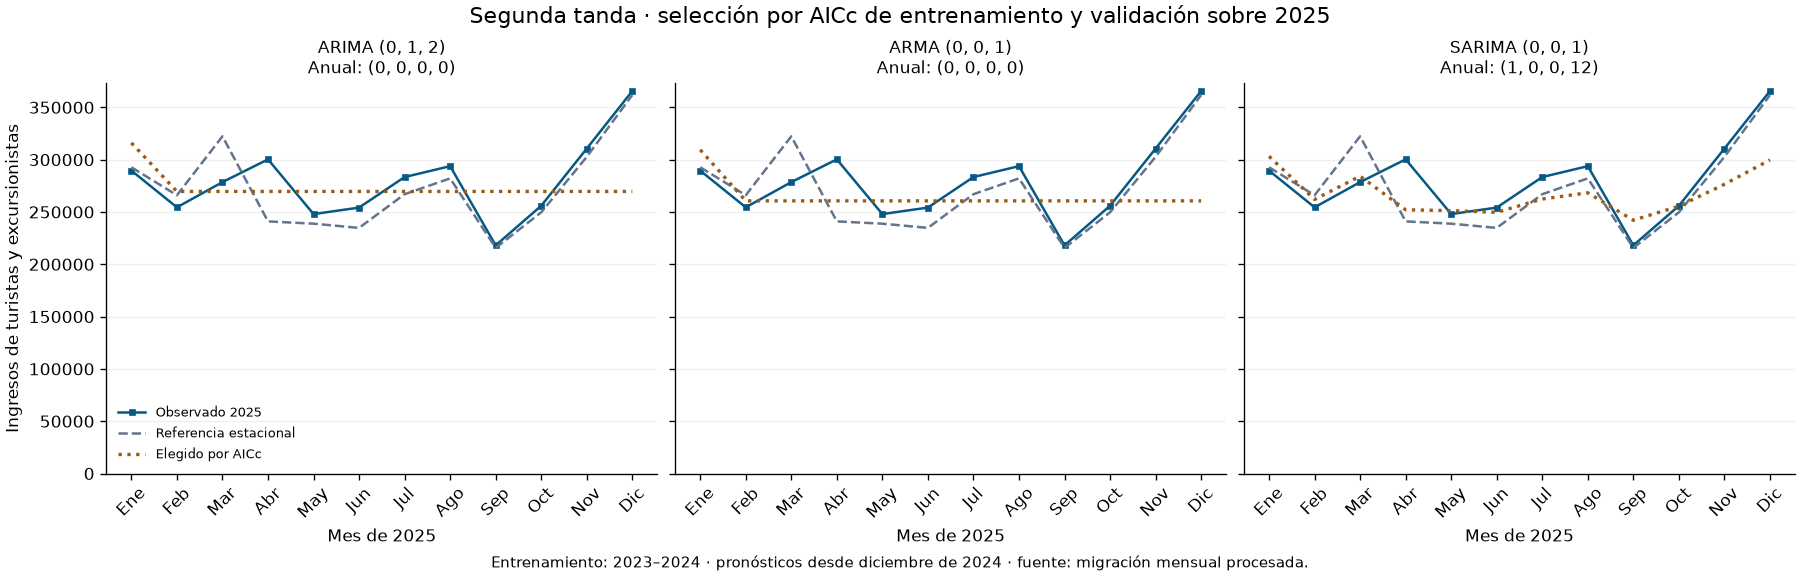

,familia,orden,anual,errores_revisados,grados_modelo,media_error_estandarizado,valor_p_Ljung_Box_rezago_6,lectura_al_5_pct
0,ARIMA,"(0, 1, 2)","(0, 0, 0, 0)",23,2,0.1734,0.3505,No se detecta autocorrelación con esta prueba
1,ARMA,"(0, 0, 1)","(0, 0, 0, 0)",24,1,-0.0084,0.5755,No se detecta autocorrelación con esta prueba
2,SARIMA,"(0, 0, 1)","(1, 0, 0, 12)",24,2,0.0705,0.7566,No se detecta autocorrelación con esta prueba


In [20]:
figura_tanda_dos, ejes_tanda_dos = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True, layout="constrained")
filas_residuos_tanda_dos = []
for eje, fila, (nombre, prediccion) in zip(
    ejes_tanda_dos, seleccion_tanda_dos.to_dict("records"), predicciones_tanda_dos.items()
):
    eje.plot(range(1, 13), validacion_nacional.to_numpy(dtype=float), color="#075985", marker="s", markersize=3, label="Observado 2025")
    eje.plot(range(1, 13), prediccion_referencia.to_numpy(), color="#64748B", linestyle="--", label="Referencia estacional")
    eje.plot(range(1, 13), prediccion.to_numpy(), color="#9A5B16", linestyle=":", linewidth=2, label="Elegido por AICc")
    eje.set_title(f"{fila['familia']} {fila['orden']}\nAnual: {fila['orden_estacional']}", fontsize=10)
    eje.set_xticks(range(1, 13), meses_grafico, rotation=45)
    eje.set_xlabel("Mes de 2025")
    eje.set_ylim(bottom=0)
    eje.grid(axis="y", alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)

    ajuste = ajustes_seleccionados_tanda_dos[nombre]
    inicio_residuos = max(int(ajuste.loglikelihood_burn), fila["orden"][1])
    residuos = ajuste.filter_results.standardized_forecasts_error[0][inicio_residuos:]
    assert np.isfinite(residuos).all(), "Residuos no finitos."
    grados_modelo = sum(fila["orden"][i] + fila["orden_estacional"][i] for i in (0, 2))
    prueba_lb = acorr_ljungbox(residuos, lags=[6], model_df=grados_modelo, return_df=True)
    valor_p = float(prueba_lb.loc[6, "lb_pvalue"])
    filas_residuos_tanda_dos.append({
        "familia": fila["familia"], "orden": fila["orden"], "anual": fila["orden_estacional"],
        "errores_revisados": len(residuos), "grados_modelo": grados_modelo,
        "media_error_estandarizado": float(np.mean(residuos)),
        "valor_p_Ljung_Box_rezago_6": valor_p,
        "lectura_al_5_pct": "Se detecta autocorrelación" if valor_p < 0.05 else "No se detecta autocorrelación con esta prueba",
    })
ejes_tanda_dos[0].set_ylabel("Ingresos de turistas y excursionistas")
ejes_tanda_dos[0].legend(frameon=False, fontsize=8, loc="lower left")
figura_tanda_dos.suptitle("Segunda tanda · selección por AICc de entrenamiento y validación sobre 2025", fontsize=13)
figura_tanda_dos.supxlabel("Entrenamiento: 2023–2024 · pronósticos desde diciembre de 2024 · fuente: migración mensual procesada.", fontsize=9)
display(figura_tanda_dos)
plt.close(figura_tanda_dos)
diagnostico_tanda_dos = pd.DataFrame(filas_residuos_tanda_dos)
display(diagnostico_tanda_dos.round(4))


### **4.16. Resultado de la segunda tanda**

Los 18 ajustes convergieron y tuvieron parámetros y AICc finitos. Las tres configuraciones con un término MA anual emitieron una advertencia por falta de observaciones para estimar sus parámetros iniciales; statsmodels utilizó ceros como punto de partida, no como valores finales impuestos. Esos avisos se conservan en la tabla. Ninguno de los tres candidatos elegidos emitió advertencias.

Dentro de cada familia, AICc eligió ARMA(0,1), ARIMA(0,1,2) y SARIMA(0,0,1)(1,0,0)[12]. Sobre 2025, sus MASE son aproximadamente 0,808, 0,803 y 0,568, respectivamente. Ninguno mejora el MASE de 0,436 de la referencia estacional, ni el resultado inicial de su familia en MAE. Mejor AICc de entrenamiento no garantizó menor error de validación.

La configuración SARIMA inicial sigue siendo la mejor de los modelos ajustados evaluados, con MASE de 0,563, pero también queda por detrás de la regla sencilla. No afirmamos que las 18 configuraciones sean peores sobre 2025: se ajustaron las 18, pero se pronosticó con las tres seleccionadas por AICc. La comparación se limita a ese protocolo.

Ljung–Box no detecta autocorrelación al 5 % en los candidatos seleccionados, bajo el rezago y grados de libertad especificados. El resultado es orientativo por el tamaño de muestra y no sustituye el desempeño fuera del entrenamiento.

Bajo estas dos tandas, la referencia estacional conserva el menor error y se mantiene como comparación para la comprobación posterior. No se amplía automáticamente la búsqueda ni se presenta esta selección como una evaluación final independiente: las decisiones se tomaron durante el desarrollo con 2025.

Todavía no se evalúa enero-junio de 2026 ni se estiman los visitantes municipales de Atitlán.


### **4.17. LightGBM con variables temporales**

Se incorpora un modelo de árboles para comprobar si las relaciones no lineales entre el calendario y los ingresos anteriores mejoran la referencia nacional. Esta prueba utiliza los mismos 24 meses de entrenamiento y estima todo 2025 desde diciembre de 2024. No se entrena con 2009-2019, pandemia o 2026.

| Variable | Información que representa |
|---|---|
| `mes_seno`, `mes_coseno` | Posición cíclica del mes: diciembre y enero quedan próximos en esta representación. |
| `paso_temporal` | Cantidad de meses desde el inicio del entrenamiento; permite explorar cambios de nivel. Un árbol no garantiza extrapolar una tendencia fuera del intervalo entrenado. |
| `rezago_1`, `rezago_2`, `rezago_3` | Ingresos de uno, dos y tres meses anteriores. |
| `rezago_12` | Ingresos del mismo mes del año anterior, cuando están disponibles. |
| `media_previa_3` | Promedio de los tres meses anteriores, sin incluir el mes objetivo. |

Las cantidades usadas como características y objetivo se expresan en miles durante el ajuste; las predicciones y métricas se devuelven a ingresos. Los tres primeros meses se utilizan solo como historia para generar rezagos: quedan 21 filas supervisadas. El rezago anual no está disponible en los primeros nueve ejemplos de entrenamiento y se mantiene como faltante estructural, que LightGBM maneja de forma nativa. No se rellena con información futura ni se convierte en cero.

Se evalúa un modelo inicial conservador y un modelo elegido por grid search. Es una prueba exploratoria: 21 ejemplos no equivalen a una historia amplia para aprender relaciones estables y la importancia de variables no se interpretará como causalidad.


In [21]:
from lightgbm import LGBMRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.utils.validation import check_is_fitted


def crear_fila_temporal(fecha, historia, origen):
    """Construye variables solo con fechas e ingresos anteriores al objetivo."""
    fila = {
        "mes_seno": np.sin(2 * np.pi * (fecha.month - 1) / 12),
        "mes_coseno": np.cos(2 * np.pi * (fecha.month - 1) / 12),
        "paso_temporal": (fecha.year - origen.year) * 12 + fecha.month - origen.month,
    }
    for rezago in [1, 2, 3, 12]:
        fecha_anterior = fecha - pd.DateOffset(months=rezago)
        fila[f"rezago_{rezago}"] = historia.get(fecha_anterior, np.nan) / 1000.0
    fechas_previas = [fecha - pd.DateOffset(months=k) for k in [1, 2, 3]]
    fila["media_previa_3"] = historia.reindex(fechas_previas).mean() / 1000.0
    return fila


class RegresorTemporalLightGBM(RegressorMixin, BaseEstimator):
    """Adaptador para que cada corte de GridSearchCV pronostique recursivamente."""

    def __init__(self, n_estimators=50, learning_rate=0.05, num_leaves=3, min_child_samples=3):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.num_leaves = num_leaves
        self.min_child_samples = min_child_samples

    def fit(self, X, y):
        if list(X.columns) != ["fecha"]:
            raise ValueError("X debe contener únicamente la fecha, no cantidades futuras.")
        fechas = pd.DatetimeIndex(pd.to_datetime(X["fecha"]))
        if not fechas.equals(pd.date_range(fechas.min(), periods=len(fechas), freq="MS")):
            raise ValueError("El entrenamiento debe tener meses consecutivos y únicos.")
        cantidades = np.asarray(y, dtype=float)
        if len(cantidades) != len(fechas) or len(cantidades) < 7:
            raise ValueError("Historia insuficiente o cantidades no alineadas.")
        if not np.isfinite(cantidades).all() or (cantidades < 0).any():
            raise ValueError("Se requieren cantidades finitas y no negativas.")
        self.historia_ = pd.Series(cantidades, index=fechas)
        self.origen_ = fechas.min()
        filas = [crear_fila_temporal(fecha, self.historia_, self.origen_) for fecha in fechas[3:]]
        self.tabla_entrenamiento_ = pd.DataFrame(filas, index=fechas[3:])
        assert self.tabla_entrenamiento_.drop(columns="rezago_12").notna().all().all()
        self.objetivo_entrenamiento_ = self.historia_.iloc[3:] / 1000.0
        self.modelo_ = LGBMRegressor(
            objective="regression", n_estimators=self.n_estimators,
            learning_rate=self.learning_rate, num_leaves=self.num_leaves,
            min_child_samples=self.min_child_samples,
            max_depth=2, reg_lambda=1.0, min_data_in_bin=1,
            random_state=42, n_jobs=1, deterministic=True,
            force_col_wise=True, verbosity=-1,
        )
        self.modelo_.fit(self.tabla_entrenamiento_, self.objetivo_entrenamiento_)
        self.n_features_in_ = 1
        return self

    def predict(self, X):
        check_is_fitted(self, "modelo_")
        if list(X.columns) != ["fecha"]:
            raise ValueError("La predicción solo recibe las fechas futuras.")
        fechas = pd.DatetimeIndex(pd.to_datetime(X["fecha"]))
        esperadas = pd.date_range(self.historia_.index.max() + pd.offsets.MonthBegin(), periods=len(fechas), freq="MS")
        if not fechas.equals(esperadas):
            raise ValueError("Las fechas deben continuar el entrenamiento mes a mes.")
        historia = self.historia_.copy()
        predicciones = []
        for fecha in fechas:
            fila = pd.DataFrame([crear_fila_temporal(fecha, historia, self.origen_)])
            fila = fila.reindex(columns=self.tabla_entrenamiento_.columns)
            valor = float(self.modelo_.predict(fila)[0]) * 1000.0
            if not np.isfinite(valor) or valor < 0:
                raise ValueError("Pronóstico inválido; no se recorta para mejorar las métricas.")
            predicciones.append(valor)
            historia.loc[fecha] = valor
        return np.asarray(predicciones)


fechas_entrenamiento_lgbm = pd.DataFrame({"fecha": entrenamiento_nacional.index})
fechas_validacion_lgbm = pd.DataFrame({"fecha": validacion_nacional.index})
objetivo_lgbm = entrenamiento_nacional.to_numpy(dtype=float)
modelo_lgbm_inicial = RegresorTemporalLightGBM().fit(fechas_entrenamiento_lgbm, objetivo_lgbm)
display(modelo_lgbm_inicial.tabla_entrenamiento_.head())
display(pd.DataFrame([{
    "meses_originales": len(entrenamiento_nacional),
    "ejemplos_supervisados": len(modelo_lgbm_inicial.tabla_entrenamiento_),
    "rezagos_anuales_no_disponibles": int(modelo_lgbm_inicial.tabla_entrenamiento_["rezago_12"].isna().sum()),
    "ultimo_mes_entrenamiento": modelo_lgbm_inicial.historia_.index.max(),
}]))


,mes_seno,mes_coseno,paso_temporal,rezago_1,rezago_2,rezago_3,rezago_12,media_previa_3
fecha,,,,,,,,
2023-04-01,1.000000e+00,6.123234e-17,3,251.839503,198.751858,258.166188,NaN,236.252516
2023-05-01,8.660254e-01,-5.000000e-01,4,283.179256,251.839503,198.751858,NaN,244.590205
2023-06-01,5.000000e-01,-8.660254e-01,5,213.191039,283.179256,251.839503,NaN,249.403266
2023-07-01,1.224647e-16,-1.000000e+00,6,224.580174,213.191039,283.179256,NaN,240.316823
2023-08-01,-5.000000e-01,-8.660254e-01,7,257.626950,224.580174,213.191039,NaN,231.799388


,meses_originales,ejemplos_supervisados,rezagos_anuales_no_disponibles,ultimo_mes_entrenamiento
0,24,21,9,2024-12-01


### **4.18. Grid search con cortes temporales internos**

La búsqueda se realiza únicamente dentro de 2023-2024. El primer corte entrena con los doce meses de 2023 y pronostica enero-junio de 2024; el segundo entrena hasta junio de 2024 y pronostica julio-diciembre de 2024. Después de formar rezagos, esos cortes tienen nueve y quince ejemplos supervisados, respectivamente.

Se prueban 16 combinaciones: 50 o 150 árboles, tasas de aprendizaje de 0,03 o 0,10, dos o cuatro hojas y un mínimo de dos o cuatro ejemplos por hoja. Se mantiene profundidad máxima de dos y regularización L2 de uno. El mínimo por hoja se reduce explícitamente frente al valor habitual de la librería porque las particiones son muy pequeñas; esto permite ajustar árboles, pero no elimina el riesgo de sobreajuste.

Cada `fit` reconstruye las variables solo con la historia recibida. Para pronosticar los seis meses siguientes, `predict` actualiza los rezagos cortos y la media con sus propias predicciones, sin recibir las cantidades reales del bloque reservado. Un GridSearchCV aplicado a rezagos precalculados de toda la serie no reproduciría estas condiciones y podría filtrar cantidades reales de meses intermedios.

La selección minimiza el MAE promedio de los dos cortes. No se calcula MASE dentro del primer corte porque doce meses no permiten formar diferencias a doce meses en su entrenamiento. La evaluación final sobre 2025 sí utiliza la escala MASE común de 2023-2024.

Los cortes internos tienen horizonte de seis meses y la validación externa doce. Esta diferencia y el escaso tamaño limitan la solidez de la selección; los resultados se presentan como exploratorios. El candidato inicial se conserva para comprobar si el ajuste aporta una mejora. No se usa 2025 para elegir los hiperparámetros de esta búsqueda ni 2026 para evaluarlos.

Referencias: [parámetros de LightGBM](https://lightgbm.readthedocs.io/en/stable/Parameters.html), [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) y [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).


In [22]:
cortes_lgbm = TimeSeriesSplit(n_splits=2, test_size=6)
lista_cortes_lgbm = list(cortes_lgbm.split(fechas_entrenamiento_lgbm))
filas_cortes_lgbm = []
for numero, (indices_ajuste, indices_prueba) in enumerate(lista_cortes_lgbm, start=1):
    historia_corte = entrenamiento_nacional.iloc[indices_ajuste]
    reales_corte = entrenamiento_nacional.iloc[indices_prueba]
    referencia_corte = historia_corte.reindex(reales_corte.index - pd.DateOffset(years=1)).to_numpy(dtype=float)
    assert np.isfinite(referencia_corte).all()
    filas_cortes_lgbm.append({
        "corte": numero,
        "ultimo_mes_ajuste": historia_corte.index.max().strftime("%Y-%m"),
        "meses_ajuste": len(historia_corte),
        "ejemplos_supervisados": len(historia_corte) - 3,
        "primer_mes_prueba": reales_corte.index.min().strftime("%Y-%m"),
        "ultimo_mes_prueba": reales_corte.index.max().strftime("%Y-%m"),
        "MAE_referencia_en_corte": float(np.mean(np.abs(reales_corte.to_numpy(dtype=float) - referencia_corte))),
    })
display(pd.DataFrame(filas_cortes_lgbm).round(2))

rejilla_lgbm = {
    "n_estimators": [50, 150],
    "learning_rate": [0.03, 0.10],
    "num_leaves": [2, 4],
    "min_child_samples": [2, 4],
}
busqueda_lgbm = GridSearchCV(
    RegresorTemporalLightGBM(), param_grid=rejilla_lgbm,
    scoring="neg_mean_absolute_error", cv=lista_cortes_lgbm,
    refit=True, n_jobs=1, error_score="raise", return_train_score=False,
)
busqueda_lgbm.fit(fechas_entrenamiento_lgbm, objetivo_lgbm)
modelo_lgbm_ajustado = busqueda_lgbm.best_estimator_
resultados_grid_lgbm = pd.DataFrame(busqueda_lgbm.cv_results_)
resultados_grid_lgbm["MAE_cv_promedio"] = -resultados_grid_lgbm["mean_test_score"]
resultados_grid_lgbm["MAE_corte_1"] = -resultados_grid_lgbm["split0_test_score"]
resultados_grid_lgbm["MAE_corte_2"] = -resultados_grid_lgbm["split1_test_score"]
display(resultados_grid_lgbm[[
    "rank_test_score", "param_n_estimators", "param_learning_rate", "param_num_leaves", "param_min_child_samples",
    "MAE_corte_1", "MAE_corte_2", "MAE_cv_promedio",
]].sort_values("rank_test_score").round(2))
display(pd.DataFrame([busqueda_lgbm.best_params_]))


,corte,ultimo_mes_ajuste,meses_ajuste,ejemplos_supervisados,primer_mes_prueba,ultimo_mes_prueba,MAE_referencia_en_corte
0,1,2023-12,12,9,2024-01,2024-06,41713.97
1,2,2024-06,18,15,2024-07,2024-12,32726.93


,rank_test_score,param_n_estimators,param_learning_rate,param_num_leaves,param_min_child_samples,MAE_corte_1,MAE_corte_2,MAE_cv_promedio
0,1,50,0.03,2,2,38916.45,35910.78,37413.61
1,2,50,0.03,4,2,41238.82,34203.96,37721.39
5,3,50,0.03,4,4,41329.91,34675.45,38002.68
11,4,150,0.10,4,2,42771.07,33357.91,38064.49
9,5,50,0.10,4,2,42308.30,35105.70,38707.00
3,6,150,0.03,4,2,43215.41,34840.65,39028.03
4,7,50,0.03,2,4,41329.91,37345.39,39337.65
8,8,50,0.10,2,2,43370.12,36557.81,39963.97
2,9,150,0.03,2,2,43773.07,36684.51,40228.79
10,10,150,0.10,2,2,53437.29,27817.30,40627.29


,learning_rate,min_child_samples,n_estimators,num_leaves
0,0.03,2,50,2


### **4.19. Comparación de LightGBM sobre 2025**

El modelo inicial y el elegido por el grid se ajustan con los mismos 24 meses, que generan 21 ejemplos supervisados. Ambos predicen enero-diciembre de 2025 desde el cierre de 2024 sin actualizarse con sus valores reales. Se utiliza exactamente la misma escala de MASE que en las dos tandas anteriores.

La importancia por ganancia se muestra solo como descripción del ajuste sobre pocos ejemplos; no demuestra que una variable cause los cambios turísticos ni que su importancia sea estable.


,modelo,MAE,RMSE,MASE,mejora_MAE_vs_referencia_pct
0,Ingenua estacional (mismo mes de 2024),16241.422,23389.837,0.436,0.000
1,"SARIMA(0,0,0)(1,0,0)[12]",20937.372,27616.068,0.563,-28.913
2,"SARIMA · orden (0, 0, 1) · anual (1, 0, 0, 12)",21142.119,28562.657,0.568,-30.174
3,LightGBM · grid temporal,23203.912,29923.381,0.623,-42.869
4,LightGBM inicial,24387.444,28886.861,0.655,-50.156
5,"ARIMA(1,1,1)",29001.750,37161.332,0.779,-78.567
6,"ARMA(1,1)",29202.067,40328.300,0.785,-79.800
7,"ARIMA · orden (0, 1, 2) · anual (0, 0, 0, 0)",29869.723,37817.998,0.803,-83.911
8,"ARMA · orden (0, 0, 1) · anual (0, 0, 0, 0)",30069.405,40305.304,0.808,-85.140


,modelo,ejemplos_supervisados,ultimo_mes_ajuste,arboles_construidos,maximo_hojas_observado
0,LightGBM inicial,21,2024-12-01,50,3
1,LightGBM · grid temporal,21,2024-12-01,50,2


,observado,referencia_estacional,LightGBM inicial,LightGBM · grid temporal
fecha,,,,
2025-01-01,289543.60,292731.87,300751.64,283190.73
2025-02-01,254428.89,265990.67,299394.54,283190.73
2025-03-01,278538.25,322310.39,299394.54,283190.73
2025-04-01,300287.69,240988.82,258462.47,258944.50
2025-05-01,247981.93,238807.95,250424.28,251231.46
2025-06-01,254190.10,234781.23,242738.04,241522.89
2025-07-01,283388.70,266974.96,252638.36,251231.46
2025-08-01,293780.52,282101.83,259122.95,262193.59
2025-09-01,218069.51,215658.81,236766.22,239842.89


,variable,ganancia
1,mes_coseno,243836.18
4,rezago_2,64753.61
6,rezago_12,55540.91
0,mes_seno,7637.21
2,paso_temporal,0.00
3,rezago_1,0.00
5,rezago_3,0.00
7,media_previa_3,0.00


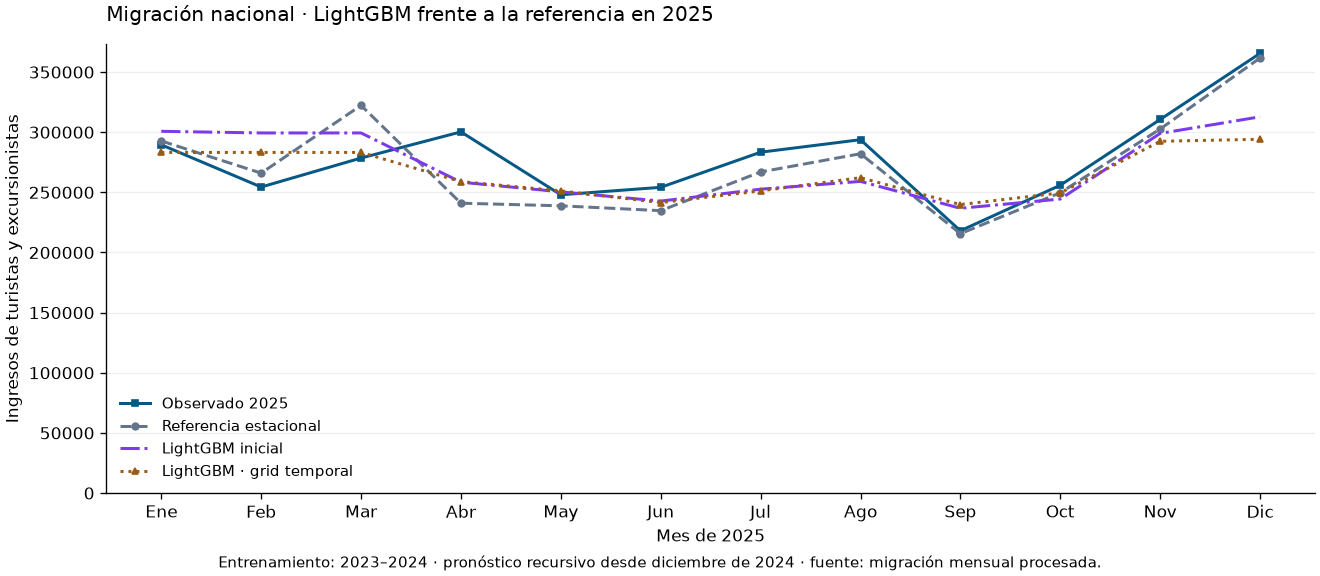

In [23]:
predicciones_lgbm = {}
filas_metricas_lgbm = []
filas_control_lgbm = []
for nombre, modelo in {
    "LightGBM inicial": modelo_lgbm_inicial,
    "LightGBM · grid temporal": modelo_lgbm_ajustado,
}.items():
    valores = modelo.predict(fechas_validacion_lgbm)
    prediccion = pd.Series(valores, index=validacion_nacional.index)
    predicciones_lgbm[nombre] = prediccion
    filas_metricas_lgbm.append({
        "modelo": nombre, "tanda": "LightGBM", "periodo": "Enero–diciembre de 2025",
        **evaluar_pronostico(validacion_nacional, prediccion, escala_mase_nacional),
    })
    arboles = modelo.modelo_.booster_.dump_model()["tree_info"]
    filas_control_lgbm.append({
        "modelo": nombre,
        "ejemplos_supervisados": len(modelo.tabla_entrenamiento_),
        "ultimo_mes_ajuste": modelo.historia_.index.max(),
        "arboles_construidos": len(arboles),
        "maximo_hojas_observado": max(arbol["num_leaves"] for arbol in arboles),
    })
comparacion_con_lgbm = pd.concat([
    comparacion_dos_tandas.drop(columns="familia", errors="ignore"),
    pd.DataFrame(filas_metricas_lgbm),
], ignore_index=True)
comparacion_con_lgbm["mejora_MAE_vs_referencia_pct"] = (
    1 - comparacion_con_lgbm["MAE"] / metricas_referencia["MAE"]
) * 100
comparacion_con_lgbm = comparacion_con_lgbm.sort_values("MASE").reset_index(drop=True)
display(comparacion_con_lgbm[["modelo", "MAE", "RMSE", "MASE", "mejora_MAE_vs_referencia_pct"]].round(3))
display(pd.DataFrame(filas_control_lgbm))

detalle_lgbm = pd.DataFrame({
    "observado": validacion_nacional.astype(float),
    "referencia_estacional": prediccion_referencia,
    **predicciones_lgbm,
})
display(detalle_lgbm.round(2))
importancia_lgbm = pd.DataFrame({
    "variable": modelo_lgbm_ajustado.tabla_entrenamiento_.columns,
    "ganancia": modelo_lgbm_ajustado.modelo_.booster_.feature_importance(importance_type="gain"),
}).sort_values("ganancia", ascending=False)
display(importancia_lgbm.round(2))

figura_lgbm, eje_lgbm = plt.subplots(figsize=(11, 4.8), layout="constrained")
for nombre, valores, color, estilo, marcador in [
    ("Observado 2025", detalle_lgbm["observado"], "#075985", "-", "s"),
    ("Referencia estacional", detalle_lgbm["referencia_estacional"], "#64748B", "--", "o"),
    ("LightGBM inicial", detalle_lgbm["LightGBM inicial"], "#7C3AED", "-.", None),
    ("LightGBM · grid temporal", detalle_lgbm["LightGBM · grid temporal"], "#9A5B16", ":", "^"),
]:
    eje_lgbm.plot(range(1, 13), valores, label=nombre, color=color, linestyle=estilo, marker=marcador, markersize=4, linewidth=1.8)
eje_lgbm.set_title("Migración nacional · LightGBM frente a la referencia en 2025", loc="left", pad=14)
eje_lgbm.set_xlabel("Mes de 2025")
eje_lgbm.set_ylabel("Ingresos de turistas y excursionistas")
eje_lgbm.set_xticks(range(1, 13), meses_grafico)
eje_lgbm.set_ylim(bottom=0)
eje_lgbm.grid(axis="y", alpha=0.2)
eje_lgbm.spines[["top", "right"]].set_visible(False)
eje_lgbm.legend(loc="lower left", frameon=False, fontsize=9)
figura_lgbm.supxlabel("Entrenamiento: 2023–2024 · pronóstico recursivo desde diciembre de 2024 · fuente: migración mensual procesada.", fontsize=9)
display(figura_lgbm)
plt.close(figura_lgbm)


### **4.20. Lectura del experimento LightGBM**

El grid search evaluó 16 configuraciones sobre dos cortes temporales internos: 32 ajustes, además del reajuste final de la configuración elegida. Seleccionó 50 árboles, tasa de aprendizaje de 0,03, dos hojas y mínimo de dos ejemplos por hoja. El MAE promedio interno fue aproximadamente 37.414 ingresos. Este error corresponde a cortes y horizontes distintos de 2025, por lo que no se compara directamente con su MAE como si midieran la misma prueba.

Sobre 2025, el LightGBM inicial obtuvo MAE de 24.387, RMSE de 28.887 y MASE de 0,655. El elegido por el grid redujo el MAE a 23.204 y el MASE a 0,623, pero su RMSE aumentó a 29.923. La selección por MAE no garantizó mejorar todos los criterios a la vez.

La referencia estacional conserva el menor error: MAE de 16.241 y MASE de 0,436. El ajuste LightGBM tampoco supera al SARIMA inicial, cuyo MASE es 0,563. Esto describe estos datos, variables y configuraciones; no demuestra que una familia sea superior en cualquier problema.

Los modelos construyeron los árboles solicitados y realizaron divisiones, por lo que el resultado no se explica por un modelo que haya quedado limitado a una constante por falta de ejemplos para dividir. Aun así, los cortes internos solo tienen nueve y quince filas supervisadas, y el ajuste final tiene 21. Esa poca historia y la acumulación de errores al actualizar rezagos con predicciones limitan esta prueba; no se ha cuantificado cuánto aporta cada limitación por separado.

Se verificó que las variables no incluyan el objetivo contemporáneo, que la predicción no modifique la historia entrenada y que los cortes internos terminen antes de 2025. No se precalculan rezagos con valores reales de meses reservados ni se aplica validación aleatoria.

El resultado sigue correspondiendo a migración nacional. No constituye validación municipal ni permite afirmar que LightGBM vaya a estimar bien las visitas a Atitlán. Enero-junio de 2026 continúa sin evaluarse. No se amplía automáticamente la rejilla después de observar estos errores.


### **4.21. Experimento LSTM con calendario**

Se prueba una red recurrente para contrastar el resultado de los modelos anteriores sobre la misma migración nacional. La arquitectura se fija antes de calcular sus errores de 2025: una capa LSTM de ocho unidades y una salida lineal, sin red apilada ni búsqueda extensa. Se utilizan ventanas de seis meses. Cada paso recibe ingresos normalizados y seno y coseno del mes; la salida también recibe el calendario del mes que se quiere estimar, que se conoce de antemano.

La red usa seis meses de contexto en cada predicción y reinicia su estado entre ventanas; no conserva una memoria indefinida. La ventana de seis meses no contiene directamente el mismo mes del año anterior. El calendario aporta una señal anual, pero no garantiza aprenderla con tan poca historia.

Se aplica `log1p` a los ingresos y después se estandariza. Ambos pasos se invierten antes de calcular las métricas. Los parámetros de estandarización se obtienen solo del entrenamiento correspondiente. No se recortan las predicciones para mejorar el resultado.

Se fija una validación interna: enero de 2023 a junio de 2024 para entrenar y julio-diciembre de 2024 para decidir la cantidad de épocas. Esa selección usa pronósticos recursivos de seis meses. Después se reinicia y entrena la red con todo 2023-2024 durante la cantidad elegida de épocas, y se pronostican los doce meses de 2025 sin recibir sus valores reales.

La parada se comprueba cada diez épocas, con un máximo de 300 y paciencia de cinco comprobaciones sin mejora del MAE interno. Se usa Adam, tasa de aprendizaje de 0,01, regularización de 0,001 y recorte de la norma del gradiente a uno. Se mantienen estas decisiones fijas durante el experimento.

Las semillas 17, 42 y 73 se definen antes de evaluar. Se reportan todas y se promedian sus predicciones; no se escoge la mejor semilla de 2025. Se ejecuta en CPU con algoritmos deterministas. La reproducibilidad exacta entre versiones y plataformas no queda garantizada por fijar semillas.

Con la ventana elegida, el ajuste interno tiene doce ejemplos y el final dieciocho. Las ventanas se traslapan y no son observaciones independientes. Esta limitación es especialmente relevante frente al número de parámetros de la red.

Referencias: [LSTM de PyTorch](https://docs.pytorch.org/docs/2.15/generated/torch.nn.LSTM.html) y [reproducibilidad](https://docs.pytorch.org/docs/2.15/notes/randomness.html).


In [24]:
import random
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler

# CPU y configuración explícita para reducir la variación en este entorno.
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
ventana_lstm = 6
unidades_lstm = 8
semillas_lstm = [17, 42, 73]


def fijar_semilla_lstm(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)


def calendario_lstm(fechas):
    meses = np.asarray(pd.DatetimeIndex(fechas).month, dtype=float)
    angulos = 2 * np.pi * (meses - 1) / 12
    return np.column_stack([np.sin(angulos), np.cos(angulos)])


def escalador_lstm_desde(serie):
    valores = serie.to_numpy(dtype=float)
    if not np.isfinite(valores).all() or (valores < 0).any():
        raise ValueError("Se requieren ingresos finitos y no negativos.")
    return StandardScaler().fit(np.log1p(valores).reshape(-1, 1))


def crear_ventanas_lstm(serie, escalador, ventana):
    if len(serie) <= ventana:
        raise ValueError("No hay historia suficiente para crear ventanas.")
    cantidades = escalador.transform(np.log1p(serie.to_numpy(dtype=float)).reshape(-1, 1))
    variables = np.column_stack([cantidades, calendario_lstm(serie.index)])
    ventanas = np.stack([variables[i - ventana:i] for i in range(ventana, len(serie))])
    calendario_objetivo = calendario_lstm(serie.index[ventana:])
    objetivos = cantidades[ventana:]
    return tuple(torch.tensor(v, dtype=torch.float32) for v in (ventanas, calendario_objetivo, objetivos))


class RedLSTMCalendario(nn.Module):
    def __init__(self, unidades=8):
        super().__init__()
        self.recurrente = nn.LSTM(input_size=3, hidden_size=unidades, num_layers=1, batch_first=True)
        self.salida = nn.Linear(unidades + 2, 1)

    def forward(self, ventanas, calendario_objetivo):
        secuencia, _ = self.recurrente(ventanas)
        contexto = torch.cat([secuencia[:, -1, :], calendario_objetivo], dim=1)
        return self.salida(contexto)


def pronosticar_lstm(red, escalador, historia, fechas, ventana):
    fechas = pd.DatetimeIndex(fechas)
    esperadas = pd.date_range(historia.index.max() + pd.offsets.MonthBegin(), periods=len(fechas), freq="MS")
    if not fechas.equals(esperadas):
        raise ValueError("El pronóstico debe continuar la historia sin saltos.")
    historia_recursiva = historia.astype(float).copy()
    predicciones = []
    red.eval()
    with torch.no_grad():
        for fecha in fechas:
            contexto = historia_recursiva.iloc[-ventana:]
            normalizado = escalador.transform(np.log1p(contexto.to_numpy()).reshape(-1, 1))
            entrada = np.column_stack([normalizado, calendario_lstm(contexto.index)])
            tensor_entrada = torch.tensor(entrada[None, :, :], dtype=torch.float32)
            tensor_calendario = torch.tensor(calendario_lstm([fecha]), dtype=torch.float32)
            salida = red(tensor_entrada, tensor_calendario).item()
            log_ingresos = escalador.inverse_transform([[salida]])[0, 0]
            valor = float(np.expm1(log_ingresos))
            if not np.isfinite(valor) or valor < 0:
                raise ValueError("La red produjo un ingreso inválido; no se recorta.")
            predicciones.append(valor)
            historia_recursiva.loc[fecha] = valor
    return pd.Series(predicciones, index=fechas)


def paso_entrenamiento_lstm(red, optimizador, ventanas, calendario, objetivo):
    red.train()
    optimizador.zero_grad()
    perdida = nn.functional.mse_loss(red(ventanas, calendario), objetivo)
    if not torch.isfinite(perdida):
        raise ValueError("Pérdida no finita durante el entrenamiento.")
    perdida.backward()
    nn.utils.clip_grad_norm_(red.parameters(), max_norm=1.0)
    optimizador.step()
    return float(perdida.detach())


### **4.22. Parada interna y reajuste sobre 2023-2024**

El escalador del corte interno solo utiliza sus dieciocho meses de entrenamiento. Los seis meses siguientes se usan para seleccionar la época, no para calcular gradientes ni alimentar los rezagos del pronóstico. Al reajustar, el escalador se calcula de nuevo con los 24 meses disponibles y la red se inicializa desde cero.

Se conserva la curva de pérdida de entrenamiento y el MAE recursivo interno en cada comprobación. La pérdida usa unidades estandarizadas, mientras que el MAE se expresa en ingresos; no se dibujan sobre un mismo eje.


,semilla,epoca_elegida,ultima_epoca_interna,MAE_interno_elegido,ventanas_internas,ventanas_finales,parametros,ultimo_mes_ajuste_final,parametros_finitos
0,17,40,90,37229.906,12,18,427,2024-12-01,True
1,42,80,130,31841.994,12,18,427,2024-12-01,True
2,73,40,90,36187.889,12,18,427,2024-12-01,True


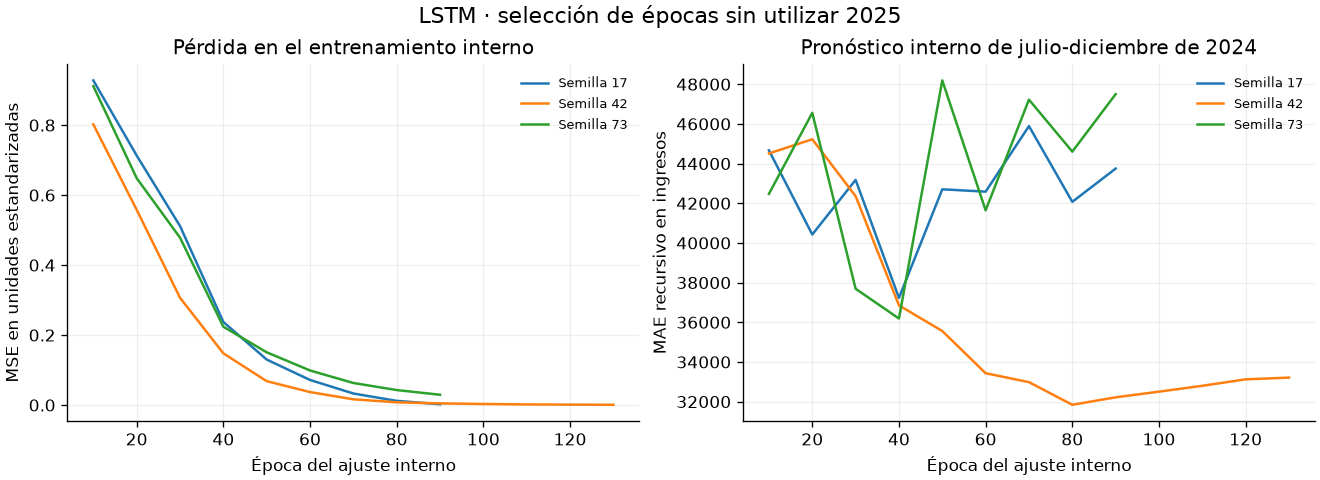

In [25]:
ajuste_interno_lstm = entrenamiento_nacional.iloc[:18].astype(float)
validacion_interna_lstm = entrenamiento_nacional.iloc[18:].astype(float)
escalador_interno_lstm = escalador_lstm_desde(ajuste_interno_lstm)
ventanas_internas_lstm, calendario_interno_lstm, objetivos_internos_lstm = crear_ventanas_lstm(
    ajuste_interno_lstm, escalador_interno_lstm, ventana_lstm
)
redes_lstm = {}
escaladores_finales_lstm = {}
curvas_lstm = []
controles_lstm = []

for semilla in semillas_lstm:
    fijar_semilla_lstm(semilla)
    red_interna = RedLSTMCalendario(unidades_lstm)
    optimizador_interno = torch.optim.Adam(red_interna.parameters(), lr=0.01, weight_decay=0.001)
    mejor_mae_interno = np.inf
    mejor_epoca = None
    sin_mejora = 0
    for epoca in range(1, 301):
        perdida = paso_entrenamiento_lstm(
            red_interna, optimizador_interno,
            ventanas_internas_lstm, calendario_interno_lstm, objetivos_internos_lstm,
        )
        if epoca % 10 == 0:
            prediccion_interna = pronosticar_lstm(
                red_interna, escalador_interno_lstm,
                ajuste_interno_lstm, validacion_interna_lstm.index, ventana_lstm,
            )
            mae_interno = float(np.mean(np.abs(validacion_interna_lstm - prediccion_interna)))
            curvas_lstm.append({"semilla": semilla, "epoca": epoca, "MSE_entrenamiento": perdida, "MAE_interno_recursivo": mae_interno})
            if mae_interno < mejor_mae_interno:
                mejor_mae_interno = mae_interno
                mejor_epoca = epoca
                sin_mejora = 0
            else:
                sin_mejora += 1
            if sin_mejora >= 5:
                break
    assert mejor_epoca is not None

    # Nueva inicialización y nuevo escalador; no se prolonga el ajuste interno.
    fijar_semilla_lstm(semilla)
    red_final = RedLSTMCalendario(unidades_lstm)
    escalador_final = escalador_lstm_desde(entrenamiento_nacional.astype(float))
    ventanas_finales, calendario_final, objetivo_final = crear_ventanas_lstm(
        entrenamiento_nacional.astype(float), escalador_final, ventana_lstm
    )
    optimizador_final = torch.optim.Adam(red_final.parameters(), lr=0.01, weight_decay=0.001)
    for _ in range(mejor_epoca):
        perdida_final = paso_entrenamiento_lstm(red_final, optimizador_final, ventanas_finales, calendario_final, objetivo_final)
    redes_lstm[semilla] = red_final
    escaladores_finales_lstm[semilla] = escalador_final
    controles_lstm.append({
        "semilla": semilla, "epoca_elegida": mejor_epoca,
        "ultima_epoca_interna": epoca, "MAE_interno_elegido": mejor_mae_interno,
        "ventanas_internas": len(ventanas_internas_lstm), "ventanas_finales": len(ventanas_finales),
        "parametros": sum(parametro.numel() for parametro in red_final.parameters()),
        "ultimo_mes_ajuste_final": entrenamiento_nacional.index.max(),
        "parametros_finitos": all(torch.isfinite(parametro).all().item() for parametro in red_final.parameters()),
    })

controles_lstm = pd.DataFrame(controles_lstm)
curvas_lstm = pd.DataFrame(curvas_lstm)
display(controles_lstm.round(3))
figura_curvas_lstm, ejes_curvas_lstm = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for semilla, grupo in curvas_lstm.groupby("semilla"):
    ejes_curvas_lstm[0].plot(grupo["epoca"], grupo["MSE_entrenamiento"], label=f"Semilla {semilla}")
    ejes_curvas_lstm[1].plot(grupo["epoca"], grupo["MAE_interno_recursivo"], label=f"Semilla {semilla}")
for eje in ejes_curvas_lstm:
    eje.set_xlabel("Época del ajuste interno")
    eje.grid(alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(frameon=False, fontsize=8)
ejes_curvas_lstm[0].set_title("Pérdida en el entrenamiento interno")
ejes_curvas_lstm[0].set_ylabel("MSE en unidades estandarizadas")
ejes_curvas_lstm[1].set_title("Pronóstico interno de julio-diciembre de 2024")
ejes_curvas_lstm[1].set_ylabel("MAE recursivo en ingresos")
figura_curvas_lstm.suptitle("LSTM · selección de épocas sin utilizar 2025", fontsize=13)
display(figura_curvas_lstm)
plt.close(figura_curvas_lstm)


### **4.23. Predicciones recursivas y evaluación sobre 2025**

Cada red genera enero-diciembre de 2025 usando sus propias predicciones al avanzar la ventana. El promedio de las tres redes se compara con las alternativas anteriores. Las métricas individuales se muestran para reconocer sensibilidad a la inicialización, sin seleccionar la semilla ganadora. La dispersión entre tres redes no se interpreta como un intervalo de confianza.


,inicializacion,MAE,RMSE,MASE
0,semilla_17,24921.604,30996.088,0.670
1,semilla_42,25763.876,30952.086,0.692
2,semilla_73,24958.504,30800.709,0.671


,modelo,MAE,RMSE,MASE,mejora_MAE_vs_referencia_pct
0,Ingenua estacional (mismo mes de 2024),16241.422,23389.837,0.436,0.000
1,"SARIMA(0,0,0)(1,0,0)[12]",20937.372,27616.068,0.563,-28.913
2,"SARIMA · orden (0, 0, 1) · anual (1, 0, 0, 12)",21142.119,28562.657,0.568,-30.174
3,LightGBM · grid temporal,23203.912,29923.381,0.623,-42.869
4,LSTM · promedio de 3 semillas,23433.675,27930.848,0.630,-44.283
5,LightGBM inicial,24387.444,28886.861,0.655,-50.156
6,"ARIMA(1,1,1)",29001.750,37161.332,0.779,-78.567
7,"ARMA(1,1)",29202.067,40328.300,0.785,-79.800
8,"ARIMA · orden (0, 1, 2) · anual (0, 0, 0, 0)",29869.723,37817.998,0.803,-83.911
9,"ARMA · orden (0, 0, 1) · anual (0, 0, 0, 0)",30069.405,40305.304,0.808,-85.140


,observado,referencia_estacional,semilla_17,semilla_42,semilla_73,LSTM_promedio
fecha,,,,,,
2025-01-01,289543.6,292731.87,293590.60,309658.59,289248.68,297499.29
2025-02-01,254428.89,265990.67,276666.38,306375.18,284222.99,289088.18
2025-03-01,278538.25,322310.39,267360.24,322939.39,269610.01,286636.55
2025-04-01,300287.69,240988.82,260599.84,245842.11,257483.59,254641.85
2025-05-01,247981.93,238807.95,254091.52,231349.05,253528.93,246323.16
2025-06-01,254190.1,234781.23,246811.62,238301.76,249672.28,244928.55
2025-07-01,283388.7,266974.96,238980.29,261357.51,243113.38,247817.06
2025-08-01,293780.52,282101.83,231434.58,273073.88,234386.59,246298.35
2025-09-01,218069.51,215658.81,228724.79,224932.84,227405.94,227021.19


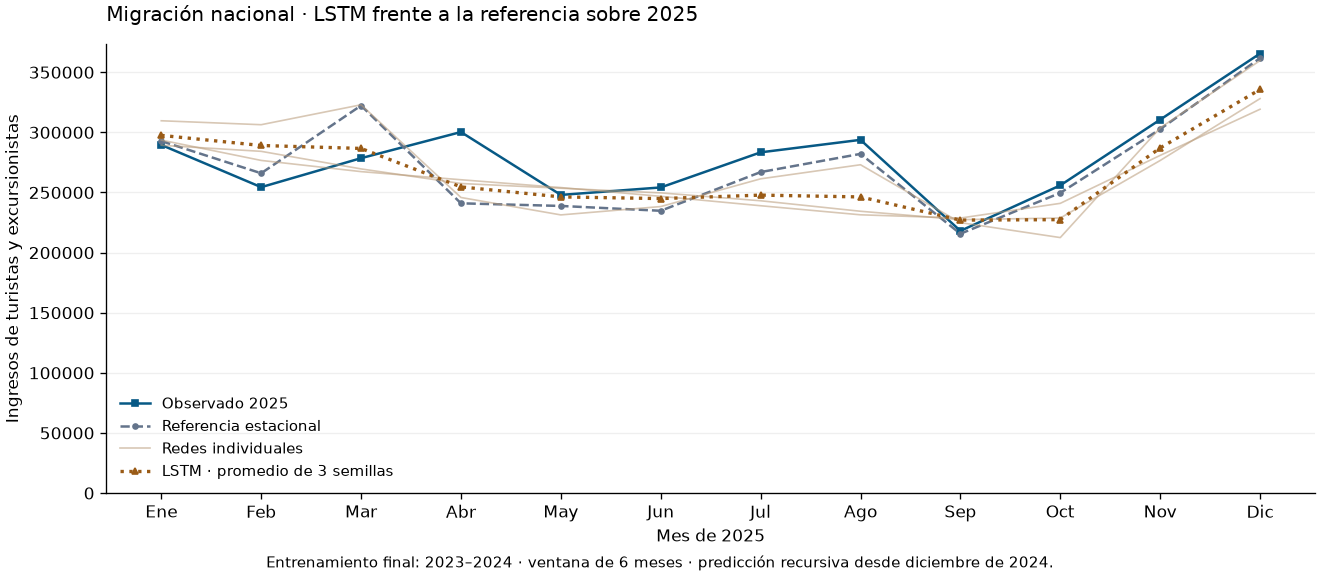

In [26]:
predicciones_semillas_lstm = pd.DataFrame({
    f"semilla_{semilla}": pronosticar_lstm(
        redes_lstm[semilla], escaladores_finales_lstm[semilla],
        entrenamiento_nacional.astype(float), validacion_nacional.index, ventana_lstm,
    ) for semilla in semillas_lstm
})
prediccion_lstm_promedio = predicciones_semillas_lstm.mean(axis=1)
metricas_lstm_promedio = evaluar_pronostico(
    validacion_nacional, prediccion_lstm_promedio, escala_mase_nacional
)
metricas_semillas_lstm = pd.DataFrame([
    {"inicializacion": nombre, **evaluar_pronostico(validacion_nacional, valores, escala_mase_nacional)}
    for nombre, valores in predicciones_semillas_lstm.items()
])
comparacion_con_lstm = pd.concat([
    comparacion_con_lgbm,
    pd.DataFrame([{
        "modelo": "LSTM · promedio de 3 semillas", "tanda": "LSTM",
        "periodo": "Enero–diciembre de 2025", **metricas_lstm_promedio,
    }]),
], ignore_index=True)
comparacion_con_lstm["mejora_MAE_vs_referencia_pct"] = (
    1 - comparacion_con_lstm["MAE"] / metricas_referencia["MAE"]
) * 100
comparacion_con_lstm = comparacion_con_lstm.sort_values("MASE").reset_index(drop=True)
display(metricas_semillas_lstm.round(3))
display(comparacion_con_lstm[["modelo", "MAE", "RMSE", "MASE", "mejora_MAE_vs_referencia_pct"]].round(3))
detalle_lstm = pd.concat([
    validacion_nacional.rename("observado"),
    prediccion_referencia.rename("referencia_estacional"),
    predicciones_semillas_lstm,
    prediccion_lstm_promedio.rename("LSTM_promedio"),
], axis=1)
display(detalle_lstm.round(2))

figura_lstm, eje_lstm = plt.subplots(figsize=(11, 4.8), layout="constrained")
eje_lstm.plot(range(1, 13), validacion_nacional.to_numpy(dtype=float), label="Observado 2025", color="#075985", marker="s", markersize=4)
eje_lstm.plot(range(1, 13), prediccion_referencia.to_numpy(), label="Referencia estacional", color="#64748B", linestyle="--", marker="o", markersize=3)
for numero, (_, valores) in enumerate(predicciones_semillas_lstm.items()):
    eje_lstm.plot(range(1, 13), valores.to_numpy(), color="#B89A78", linewidth=1, alpha=0.55,
                  label="Redes individuales" if numero == 0 else None)
eje_lstm.plot(range(1, 13), prediccion_lstm_promedio.to_numpy(), label="LSTM · promedio de 3 semillas", color="#9A5B16", linestyle=":", marker="^", markersize=4, linewidth=2)
eje_lstm.set_title("Migración nacional · LSTM frente a la referencia sobre 2025", loc="left", pad=14)
eje_lstm.set_xlabel("Mes de 2025")
eje_lstm.set_ylabel("Ingresos de turistas y excursionistas")
eje_lstm.set_xticks(range(1, 13), meses_grafico)
eje_lstm.set_ylim(bottom=0)
eje_lstm.grid(axis="y", alpha=0.2)
eje_lstm.spines[["top", "right"]].set_visible(False)
eje_lstm.legend(loc="lower left", frameon=False, fontsize=9)
figura_lstm.supxlabel("Entrenamiento final: 2023–2024 · ventana de 6 meses · predicción recursiva desde diciembre de 2024.", fontsize=9)
display(figura_lstm)
plt.close(figura_lstm)


### **4.24. Lectura del experimento LSTM**

La selección interna eligió 40, 80 y 40 épocas para las semillas 17, 42 y 73, respectivamente. Cada red final tiene 427 parámetros y solo dieciocho ventanas de entrenamiento que se traslapan. Las curvas permiten revisar cómo una disminución de la pérdida dentro del entrenamiento no implica mejorar el pronóstico recursivo interno.

Sobre 2025, los MASE individuales fueron aproximadamente 0,670, 0,692 y 0,671. El promedio de las tres predicciones obtuvo MAE de 23.434 ingresos, RMSE de 27.931 y MASE de 0,630. Se evaluó el promedio fijado antes de conocer los resultados; no se eligió una semilla por su desempeño externo. El error del promedio puede ser menor que el de cada red individual porque sus errores no coinciden en todos los meses.

La referencia estacional sigue obteniendo el menor error, con MAE de 16.241 y MASE de 0,436. El LightGBM ajustado tiene un MAE ligeramente menor que el promedio LSTM, pero un RMSE mayor. La configuración SARIMA inicial conserva el menor MAE entre los modelos ajustados evaluados. No hay una mejora general por aumentar la complejidad.

El experimento no permite concluir que una LSTM sea inadecuada para cualquier serie turística: esta arquitectura se ajustó con dos años, pocos ejemplos y una ventana de seis meses. El calendario aporta una señal anual conocida, pero no reemplaza la falta de ciclos observados. No se atribuye el resultado a una única causa sin experimentos adicionales.

Se comprobaron las dimensiones de las ventanas, el escalado calculado solo con el entrenamiento correspondiente, el uso exclusivo de fechas futuras durante el pronóstico, la ausencia del objetivo contemporáneo dentro de su ventana y que predecir no modifique la historia. Repetir la predicción con una red entrenada produjo los mismos valores en este entorno.

El ajuste interno se utilizó para seleccionar épocas y no constituye una evaluación final independiente. Esta prueba sigue correspondiendo a ingresos nacionales, no a visitantes municipales. Enero-junio de 2026 permanece reservado. No se inicia otra arquitectura o búsqueda automáticamente después de observar los resultados.


### **4.25. Prueba final con Chronos-2 preentrenado**

Se utiliza una sola versión de `amazon/chronos-2`, con revisión fija `29ec3766d36d6f73f0696f85560a422f50e8498c`. Es un modelo fundacional preentrenado: no se ajustan sus pesos, no se realiza fine-tuning ni se busca otro checkpoint después de conocer su resultado. Se ejecuta localmente en CPU con precisión float32.

Recibe exclusivamente los 24 ingresos mensuales de enero de 2023 a diciembre de 2024, en sus unidades originales. Se solicitan doce predicciones y los cuantiles 0,10, 0,50 y 0,90. La mediana, fijada como predicción puntual antes de ejecutar, se evalúa con el MAE, RMSE y la misma escala de MASE utilizados en las pruebas anteriores. No se elige entre media y mediana según su resultado.

Esta primera prueba fundacional es univariada y no añade variables externas. El pipeline aplica su normalización interna al contexto; no se utiliza el escalador de la LSTM ni se normaliza con cantidades de 2025 o 2026. No se actualiza con los valores reales de 2025 al avanzar el horizonte.

Los cuantiles 10–90 describen un intervalo predictivo nominal del 80 %, no un intervalo de confianza sobre la media ni una cobertura garantizada. Se comprueba cuántos de los doce valores de 2025 quedan dentro, sin calibrar los intervalos con esos mismos valores.

El preentrenamiento utiliza datos externos. Restringir nuestro contexto hasta diciembre de 2024 no demuestra que el modelo nunca haya visto datos relacionados durante su preentrenamiento; no se ha auditado exhaustivamente ese corpus. Esta diferencia se conserva al comparar un modelo preentrenado con los ajustados localmente.

El checkpoint descargado queda en `data/processed/modelos_preentrenados/chronos_2`, excluido de Git. La primera ejecución requiere descargar sus archivos públicos; las siguientes pueden utilizar la copia local. No se contrata una API ni se envían los ingresos del proyecto a un servicio de predicción.

Referencias: [ficha del modelo](https://huggingface.co/amazon/chronos-2) e [implementación oficial](https://github.com/amazon-science/chronos-forecasting).


In [27]:
import time
from importlib.metadata import version
from chronos import Chronos2Pipeline
from huggingface_hub import snapshot_download
from huggingface_hub.errors import LocalEntryNotFoundError
from config import PROCESSED

identificador_chronos = "amazon/chronos-2"
revision_chronos = "29ec3766d36d6f73f0696f85560a422f50e8498c"
cache_chronos = PROCESSED / "modelos_preentrenados" / "chronos_2" / "hub"
argumentos_descarga_chronos = {
    "repo_id": identificador_chronos,
    "revision": revision_chronos,
    "allow_patterns": ["config.json", "model.safetensors"],
    "cache_dir": str(cache_chronos),
    "token": False,
}
try:
    checkpoint_chronos = snapshot_download(**argumentos_descarga_chronos, local_files_only=True)
except LocalEntryNotFoundError:
    checkpoint_chronos = snapshot_download(**argumentos_descarga_chronos, max_workers=1)

pipeline_chronos = Chronos2Pipeline.from_pretrained(
    checkpoint_chronos, device_map="cpu", dtype=torch.float32, local_files_only=True,
)
pipeline_chronos.model.eval()
pipeline_chronos.model.requires_grad_(False)

contexto_chronos = torch.tensor(
    entrenamiento_nacional.to_numpy(dtype=np.float32)[None, None, :], dtype=torch.float32,
)
assert contexto_chronos.shape == (1, 1, 24)
assert entrenamiento_nacional.index.max() == pd.Timestamp("2024-12-01")
assert torch.isfinite(contexto_chronos).all()
cuantiles_solicitados_chronos = [0.1, 0.5, 0.9]
inicio_inferencia_chronos = time.perf_counter()
with torch.inference_mode():
    cuantiles_chronos, _ = pipeline_chronos.predict_quantiles(
        inputs=contexto_chronos,
        prediction_length=12,
        quantile_levels=cuantiles_solicitados_chronos,
        context_length=24,
        batch_size=1,
        cross_learning=False,
        limit_prediction_length=True,
    )
segundos_chronos = time.perf_counter() - inicio_inferencia_chronos
valores_cuantiles_chronos = cuantiles_chronos[0].detach().cpu().numpy()
assert valores_cuantiles_chronos.shape == (1, 12, 3)
assert np.isfinite(valores_cuantiles_chronos).all()
assert (np.diff(valores_cuantiles_chronos[0], axis=1) >= 0).all(), "Los cuantiles se cruzan; revisar sin reordenarlos."

pronostico_chronos = pd.DataFrame(
    valores_cuantiles_chronos[0], index=validacion_nacional.index,
    columns=["q10", "mediana", "q90"],
)
assert pronostico_chronos["mediana"].ge(0).all(), "La mediana tiene valores negativos; no se recortan."
assert not any(parametro.requires_grad for parametro in pipeline_chronos.model.parameters())
controles_chronos = pd.DataFrame([{
    "modelo": identificador_chronos,
    "revision": revision_chronos,
    "version_chronos": version("chronos-forecasting"),
    "version_transformers": version("transformers"),
    "version_torch": version("torch"),
    "parametros_preentrenados": sum(parametro.numel() for parametro in pipeline_chronos.model.parameters()),
    "parametros_entrenables_en_prueba": sum(parametro.numel() for parametro in pipeline_chronos.model.parameters() if parametro.requires_grad),
    "meses_contexto": contexto_chronos.shape[-1],
    "primer_mes_contexto": entrenamiento_nacional.index.min(),
    "ultimo_mes_contexto": entrenamiento_nacional.index.max(),
    "meses_pronosticados": len(pronostico_chronos),
    "segundos_inferencia_CPU": segundos_chronos,
}])
display(controles_chronos)


,modelo,revision,version_chronos,version_transformers,version_torch,parametros_preentrenados,parametros_entrenables_en_prueba,meses_contexto,primer_mes_contexto,ultimo_mes_contexto,meses_pronosticados,segundos_inferencia_CPU
0,amazon/chronos-2,29ec3766d36d6f73f0696f85560a422f50e8498c,2.3.2,5.22.1,2.15.0,119477664,0,24,2023-01-01,2024-12-01,12,2.169694


### **4.26. Comparación puntual y revisión de cuantiles**

Se mantienen separadas la comparación de predicciones puntuales y la revisión de intervalos. El porcentaje de valores cubiertos se calcula sobre solo doce meses y no valida por sí solo la calibración de la distribución. La amplitud media del intervalo se expresa en ingresos y se muestra para no interpretar una cobertura alta sin considerar su anchura.


,modelo,MAE,RMSE,MASE,mejora_MAE_vs_referencia_pct
0,Ingenua estacional (mismo mes de 2024),16241.422,23389.837,0.436,0.000
1,"SARIMA(0,0,0)(1,0,0)[12]",20937.372,27616.068,0.563,-28.913
2,"SARIMA · orden (0, 0, 1) · anual (1, 0, 0, 12)",21142.119,28562.657,0.568,-30.174
3,LightGBM · grid temporal,23203.912,29923.381,0.623,-42.869
4,LSTM · promedio de 3 semillas,23433.675,27930.848,0.630,-44.283
5,LightGBM inicial,24387.444,28886.861,0.655,-50.156
6,Chronos-2 · zero-shot · mediana,28908.269,36389.957,0.777,-77.991
7,"ARIMA(1,1,1)",29001.750,37161.332,0.779,-78.567
8,"ARMA(1,1)",29202.067,40328.300,0.785,-79.800
9,"ARIMA · orden (0, 1, 2) · anual (0, 0, 0, 0)",29869.723,37817.998,0.803,-83.911


,observado,referencia_estacional,q10,mediana,q90,error_mediana,dentro_q10_q90
fecha,,,,,,,
2025-01-01,289543.60,292731.87,228218.953125,305421.50000,399678.00000,-15877.90,True
2025-02-01,254428.89,265990.67,207969.562500,289739.34375,396116.09375,-35310.46,True
2025-03-01,278538.25,322310.39,200884.546875,286778.68750,395111.37500,-8240.44,True
2025-04-01,300287.69,240988.82,199507.765625,283232.68750,396035.87500,17055.00,True
2025-05-01,247981.93,238807.95,192128.046875,277750.84375,394456.81250,-29768.92,True
2025-06-01,254190.10,234781.23,191455.078125,275822.87500,395673.15625,-21632.78,True
2025-07-01,283388.70,266974.96,191546.375000,277738.37500,399998.43750,5650.32,True
2025-08-01,293780.52,282101.83,189691.343750,278261.18750,404833.59375,15519.34,True
2025-09-01,218069.51,215658.81,186851.203125,276347.37500,405735.81250,-58277.86,True


,meses_evaluados,meses_dentro_q10_q90,cobertura_observada_pct,cobertura_nominal_pct,amplitud_media_intervalo_ingresos
0,12,12,100.0,80,205878.515625


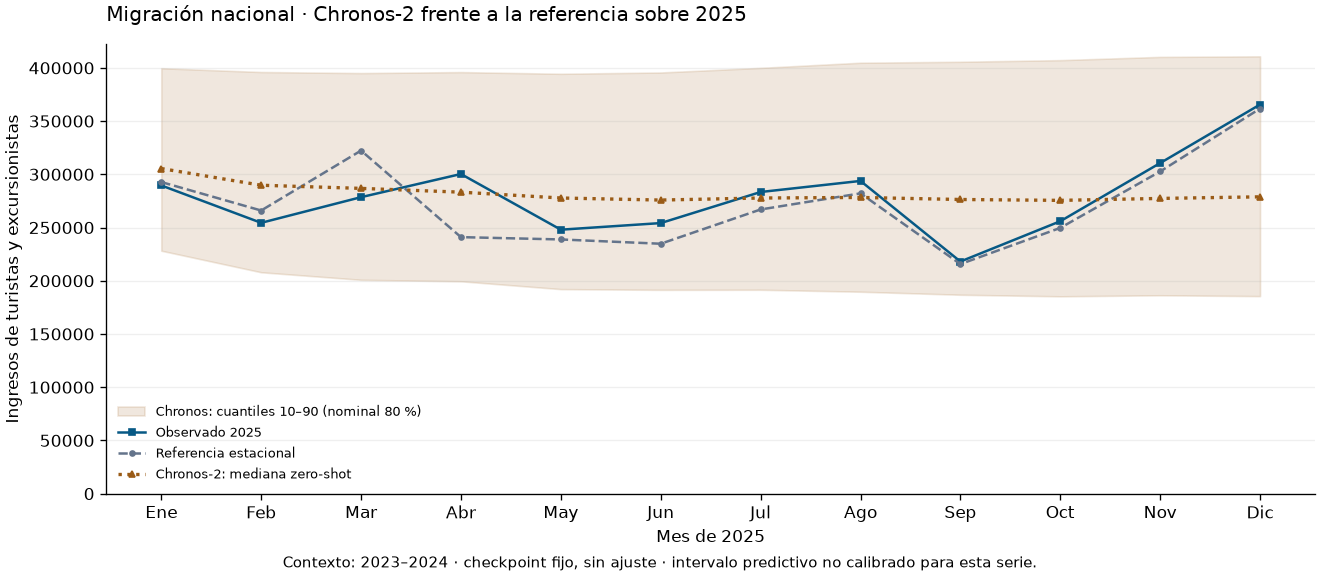

In [28]:
metricas_chronos = evaluar_pronostico(
    validacion_nacional, pronostico_chronos["mediana"], escala_mase_nacional,
)
comparacion_final_nacional = pd.concat([
    comparacion_con_lstm,
    pd.DataFrame([{
        "modelo": "Chronos-2 · zero-shot · mediana", "tanda": "Chronos preentrenado",
        "periodo": "Enero–diciembre de 2025", **metricas_chronos,
    }]),
], ignore_index=True)
comparacion_final_nacional["mejora_MAE_vs_referencia_pct"] = (
    1 - comparacion_final_nacional["MAE"] / metricas_referencia["MAE"]
) * 100
comparacion_final_nacional = comparacion_final_nacional.sort_values("MASE").reset_index(drop=True)
display(comparacion_final_nacional[[
    "modelo", "MAE", "RMSE", "MASE", "mejora_MAE_vs_referencia_pct",
]].round(3))

detalle_chronos = pd.concat([
    validacion_nacional.astype(float).rename("observado"),
    prediccion_referencia.rename("referencia_estacional"), pronostico_chronos,
], axis=1)
detalle_chronos["error_mediana"] = detalle_chronos["observado"] - detalle_chronos["mediana"]
detalle_chronos["dentro_q10_q90"] = detalle_chronos["observado"].between(
    detalle_chronos["q10"], detalle_chronos["q90"],
)
resumen_intervalos_chronos = pd.DataFrame([{
    "meses_evaluados": len(detalle_chronos),
    "meses_dentro_q10_q90": int(detalle_chronos["dentro_q10_q90"].sum()),
    "cobertura_observada_pct": detalle_chronos["dentro_q10_q90"].mean() * 100,
    "cobertura_nominal_pct": 80,
    "amplitud_media_intervalo_ingresos": (detalle_chronos["q90"] - detalle_chronos["q10"]).mean(),
}])
display(detalle_chronos.round(2))
display(resumen_intervalos_chronos.round(2))

figura_chronos, eje_chronos = plt.subplots(figsize=(11, 4.8), layout="constrained")
eje_chronos.fill_between(range(1, 13), detalle_chronos["q10"].to_numpy(), detalle_chronos["q90"].to_numpy(),
                        color="#9A5B16", alpha=0.14, label="Chronos: cuantiles 10–90 (nominal 80 %)")
eje_chronos.plot(range(1, 13), detalle_chronos["observado"], label="Observado 2025", color="#075985", marker="s", markersize=4)
eje_chronos.plot(range(1, 13), detalle_chronos["referencia_estacional"], label="Referencia estacional", color="#64748B", linestyle="--", marker="o", markersize=3)
eje_chronos.plot(range(1, 13), detalle_chronos["mediana"], label="Chronos-2: mediana zero-shot", color="#9A5B16", linestyle=":", marker="^", markersize=4, linewidth=2)
eje_chronos.set_title("Migración nacional · Chronos-2 frente a la referencia sobre 2025", loc="left", pad=14)
eje_chronos.set_xlabel("Mes de 2025")
eje_chronos.set_ylabel("Ingresos de turistas y excursionistas")
eje_chronos.set_xticks(range(1, 13), meses_grafico)
# Se conserva el límite inferior negativo si el modelo produce cuantiles negativos.
eje_chronos.set_ylim(bottom=min(0, float(detalle_chronos["q10"].min())))
eje_chronos.grid(axis="y", alpha=0.2)
eje_chronos.spines[["top", "right"]].set_visible(False)
eje_chronos.legend(loc="lower left", frameon=False, fontsize=8)
figura_chronos.supxlabel("Contexto: 2023–2024 · checkpoint fijo, sin ajuste · intervalo predictivo no calibrado para esta serie.", fontsize=9)
display(figura_chronos)
plt.close(figura_chronos)


### **4.27. Cierre de los experimentos sobre 2025**

Chronos-2, sin ajuste y con los mismos 24 meses de contexto, obtuvo MAE de aproximadamente 28.908 ingresos, RMSE de 36.390 y MASE de 0,777. La mediana muestra poca variación durante buena parte del horizonte y no reproduce el pico observado de diciembre. Esa lectura describe la salida de esta prueba, sin atribuirla a una causa única ni afirmar que cualquier modelo fundacional tendrá el mismo comportamiento.

Los doce valores reales quedaron dentro de los cuantiles 10–90. Sin embargo, la amplitud media del intervalo fue de aproximadamente 205.879 ingresos. Una cobertura observada del 100 % con intervalos tan amplios y solo doce observaciones no demuestra superioridad ni una buena calibración. La comparación puntual sigue basada en la mediana definida antes de ejecutar.

Se comprobó que el modelo mantuviera todos sus pesos congelados, que el contexto tuviera exactamente los 24 meses hasta diciembre de 2024, que los doce resultados coincidieran con el calendario de 2025 y que los cuantiles estuvieran ordenados. Repetir la inferencia conservó el contexto y produjo los mismos resultados en este entorno. No se probaron otros checkpoints ni se ajustó el modelo después de ver los errores.

**La referencia estacional conserva el menor MAE, RMSE y MASE sobre 2025 entre las alternativas puntuales evaluadas.** La configuración SARIMA inicial es la mejor entre los modelos ajustados localmente en MAE y RMSE. Estos resultados corresponden a las configuraciones, contexto y horizonte ensayados, no a una jerarquía universal de familias.

Con ello se cierra la exploración nacional acordada, sin añadir nuevos experimentos para buscar un ganador más complejo. La referencia estacional se conserva como contraste para la comprobación reservada de enero-junio de 2026. La elección del modelo ajustado se documenta en la sección 4.30. Esa comprobación no se ha ejecutado todavía; 2025 se ha usado para desarrollo y selección.

La estimación de enero-febrero de Atitlán requiere después evaluar la relación municipal con migración. Los resultados nacionales no sustituyen esa validación ni obligan a pronosticar la migración de esos meses, porque ya está observada. El método naive se conserva como contraste nacional; su error no se presentará como error de visitantes municipales.


### **4.28. Comparación explícita de AR y MA**

AR utiliza relaciones con cantidades pasadas; MA utiliza relaciones con errores pasados del proceso. MA no significa sustituir la predicción por una media móvil de los últimos meses.

AR(1), AR(2), MA(1) y MA(2) ya se ajustaron dentro de la rejilla ARMA de la segunda tanda, pero solo MA(1) pasó a la comparación externa por haber sido elegido mediante AICc dentro de esa familia. Ahora se evalúan los cuatro explícitamente sobre 2025. Se reutilizan los ajustes de entrenamiento, con constante, sin diferenciación y sin componente anual. No se cambian sus órdenes después de calcular estos nuevos errores.

Esta es una comparación adicional durante el desarrollo, distinta del protocolo anterior que evaluaba un elegido por familia. Se identifica por separado y se conserva el mismo horizonte, escala MASE y referencia. Enero-junio de 2026 no participa.

El naive estacional se mantiene como método de referencia. Si se adopta un modelo ajustado aunque su error sea mayor, se documentará ese costo sin presentar su resultado como superior ni eliminar la referencia de la comparación.


,modelo,MAE,RMSE,MASE
0,AR(1),29052.831,40257.129,0.781
1,MA(2),29767.917,40896.312,0.800
2,MA(1),30069.405,40305.304,0.808
3,AR(2),35645.485,44350.929,0.958


,modelo,MAE,RMSE,MASE,mejora_MAE_vs_referencia_pct
0,Ingenua estacional (mismo mes de 2024),16241.422,23389.837,0.436,0.000
1,"SARIMA(0,0,0)(1,0,0)[12]",20937.372,27616.068,0.563,-28.913
2,"SARIMA · orden (0, 0, 1) · anual (1, 0, 0, 12)",21142.119,28562.657,0.568,-30.174
3,LightGBM · grid temporal,23203.912,29923.381,0.623,-42.869
4,LSTM · promedio de 3 semillas,23433.675,27930.848,0.630,-44.283
5,LightGBM inicial,24387.444,28886.861,0.655,-50.156
6,Chronos-2 · zero-shot · mediana,28908.269,36389.957,0.777,-77.991
7,"ARIMA(1,1,1)",29001.750,37161.332,0.779,-78.567
8,AR(1),29052.831,40257.129,0.781,-78.881
9,"ARMA(1,1)",29202.067,40328.300,0.785,-79.800


,observado,referencia_estacional,AR(1),AR(2),MA(1),MA(2)
2025-01-01,289543.60,292731.87,290505.70,278116.12,309427.73,291079.82
2025-02-01,254428.89,265990.67,269054.24,220078.12,260613.62,236827.50
2025-03-01,278538.25,322310.39,262595.23,234630.30,260613.62,258956.92
2025-04-01,300287.69,240988.82,260650.43,265739.34,260613.62,258956.92
2025-05-01,247981.93,238807.95,260064.85,271258.63,260613.62,258956.92
2025-06-01,254190.10,234781.23,259888.54,259687.93,260613.62,258956.92
2025-07-01,283388.70,266974.96,259835.45,252825.86,260613.62,258956.92
2025-08-01,293780.52,282101.83,259819.46,255286.54,260613.62,258956.92
2025-09-01,218069.51,215658.81,259814.65,259248.31,260613.62,258956.92
2025-10-01,255920.93,249665.70,259813.20,259683.96,260613.62,258956.92


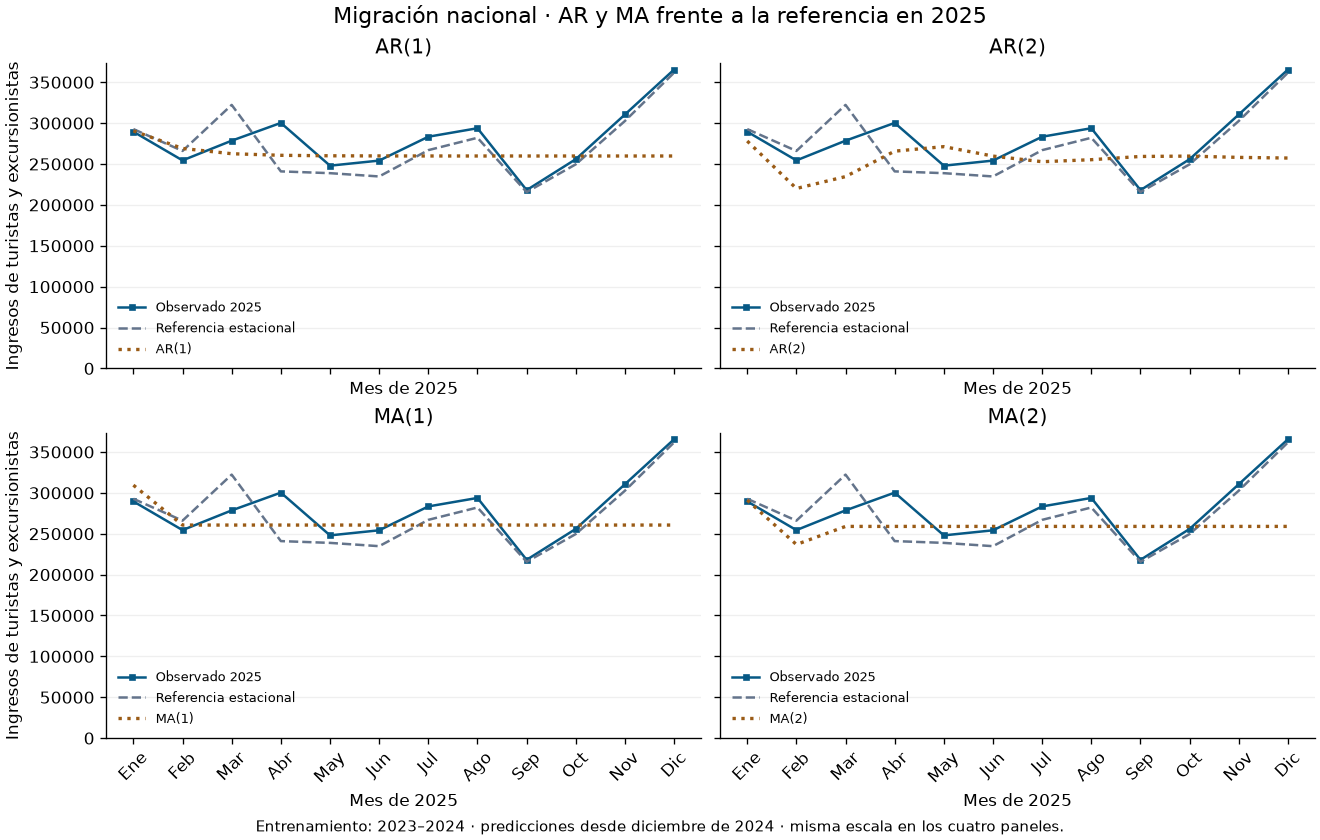

In [29]:
ordenes_ar_ma = {
    "AR(1)": (1, 0, 0),
    "AR(2)": (2, 0, 0),
    "MA(1)": (0, 0, 1),
    "MA(2)": (0, 0, 2),
}
predicciones_ar_ma = {}
filas_ar_ma = []
for nombre, orden in ordenes_ar_ma.items():
    coincide = busqueda_tanda_dos["familia"].eq("ARMA") & busqueda_tanda_dos["orden"].map(lambda candidato: candidato == orden)
    fila = busqueda_tanda_dos.loc[coincide].iloc[0]
    assert fila["apto_seleccion"], f"Ajuste no apto: {nombre}"
    ajuste = ajustes_tanda_dos[fila["id"]]
    assert ajuste.nobs == 24
    prediccion = ajuste.forecast(steps=12) * factor_unidad
    assert prediccion.index.equals(validacion_nacional.index)
    assert np.isfinite(prediccion.to_numpy()).all() and prediccion.ge(0).all()
    predicciones_ar_ma[nombre] = prediccion
    filas_ar_ma.append({
        "modelo": nombre, "tanda": "AR/MA · comparación explícita",
        "periodo": "Enero–diciembre de 2025",
        **evaluar_pronostico(validacion_nacional, prediccion, escala_mase_nacional),
    })
resultados_ar_ma = pd.DataFrame(filas_ar_ma).sort_values("MASE").reset_index(drop=True)
comparacion_con_ar_ma = pd.concat([comparacion_final_nacional, pd.DataFrame(filas_ar_ma)], ignore_index=True)
comparacion_con_ar_ma["mejora_MAE_vs_referencia_pct"] = (
    1 - comparacion_con_ar_ma["MAE"] / metricas_referencia["MAE"]
) * 100
comparacion_con_ar_ma = comparacion_con_ar_ma.sort_values("MASE").reset_index(drop=True)
display(resultados_ar_ma[["modelo", "MAE", "RMSE", "MASE"]].round(3))
display(comparacion_con_ar_ma[["modelo", "MAE", "RMSE", "MASE", "mejora_MAE_vs_referencia_pct"]].round(3))
detalle_ar_ma = pd.DataFrame({
    "observado": validacion_nacional.astype(float),
    "referencia_estacional": prediccion_referencia,
    **predicciones_ar_ma,
})
display(detalle_ar_ma.round(2))

figura_ar_ma, ejes_ar_ma = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True, layout="constrained")
for eje, (nombre, prediccion) in zip(ejes_ar_ma.flat, predicciones_ar_ma.items()):
    eje.plot(range(1, 13), detalle_ar_ma["observado"], color="#075985", marker="s", markersize=3, label="Observado 2025")
    eje.plot(range(1, 13), detalle_ar_ma["referencia_estacional"], color="#64748B", linestyle="--", label="Referencia estacional")
    eje.plot(range(1, 13), prediccion.to_numpy(), color="#9A5B16", linestyle=":", linewidth=2, label=nombre)
    eje.set_title(nombre)
    eje.set_xticks(range(1, 13), meses_grafico, rotation=45)
    eje.set_xlabel("Mes de 2025")
    eje.set_ylim(bottom=0)
    eje.grid(axis="y", alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(loc="lower left", frameon=False, fontsize=8)
for eje in ejes_ar_ma[:, 0]:
    eje.set_ylabel("Ingresos de turistas y excursionistas")
figura_ar_ma.suptitle("Migración nacional · AR y MA frente a la referencia en 2025", fontsize=13)
figura_ar_ma.supxlabel("Entrenamiento: 2023–2024 · predicciones desde diciembre de 2024 · misma escala en los cuatro paneles.", fontsize=9)
display(figura_ar_ma)
plt.close(figura_ar_ma)


### **4.29. Lectura de la comparación AR/MA**

AR(1) obtuvo MAE de aproximadamente 29.053 ingresos y MASE de 0,781; MA(2), MAE de 29.768 y MASE de 0,800; MA(1), MAE de 30.069 y MASE de 0,808; y AR(2), MAE de 35.645 y MASE de 0,958. Ninguno mejora la referencia estacional ni la configuración SARIMA inicial.

En los gráficos, las predicciones se acercan a un nivel constante al avanzar el horizonte. Estos modelos no incorporan explícitamente el calendario anual, y sus relaciones de corto plazo no reproducen el comportamiento de todo 2025 en esta prueba.

Si se requiere un modelo ajustado, SARIMA(0,0,0)(1,0,0)[12] sigue siendo el candidato con menor error entre los evaluados: MAE de 20.937 y MASE de 0,563. Su MAE es aproximadamente 28,9 % mayor que el de la referencia, por lo que no se presentará como una mejora sobre ella.

Esta comparación explícita se incorpora durante el desarrollo, después de observar resultados previos de 2025. No convierte ese año en una prueba final independiente. La referencia estacional se conserva en las tablas y gráficos. Enero-junio de 2026 continúa sin evaluarse y todavía no se estiman las visitas municipales.


### **4.30. Modelo seleccionado y comparación con naive estacional**

Se selecciona **SARIMA(0,0,0)(1,0,0)[12] con constante**, correspondiente a la primera configuración estacional evaluada, para continuar con el modelo de referencia nacional. Incluye un término autorregresivo anual, sin términos AR o MA de corto plazo y sin diferenciación ordinaria o estacional. Se conserva la implementación y el cambio fijo de unidad a miles de ingresos utilizados en la primera tanda.

La elección responde a continuar con un modelo paramétrico ajustado y a que esta configuración obtuvo el menor error entre los modelos ajustados evaluados sobre 2025. **No se selecciona porque haya superado al naive estacional:** ese método obtuvo mejores resultados y se conserva en las tablas, los gráficos y la evaluación posterior.

| Método | MAE en ingresos | RMSE en ingresos | MASE |
|---|---:|---:|---:|
| Naive estacional: mismo mes del año anterior | 16.241,42 | 23.389,84 | 0,436 |
| SARIMA seleccionado | 20.937,37 | 27.616,07 | 0,563 |

El MAE de SARIMA fue aproximadamente **28,9 % mayor** que el del naive estacional. Esta diferencia se reportará como una limitación de la elección, sin eliminar el método sencillo ni afirmar que una mayor complejidad produjo una mejora.

La configuración queda fijada antes de la comprobación posterior. El siguiente paso será reajustar este SARIMA con enero de 2023 a diciembre de 2025 y evaluar sus seis pronósticos de enero-junio de 2026 junto al naive estacional, recalculando la escala MASE exclusivamente con ese nuevo entrenamiento. No se modificarán los órdenes a partir de los resultados de 2026 para presentarlos después como una prueba independiente.

Esta selección quedó fijada antes del reajuste y la apertura del test. Su ejecución se presenta en las secciones 4.31-4.34. El modelo corresponde a ingresos nacionales. La relación con las visitas municipales y su validación siguen pendientes; la migración de enero-febrero de 2026 ya está observada y no se reemplazará automáticamente por un pronóstico nacional.


### **4.31. Reajuste del SARIMA elegido con 2023-2025**

Después de fijar la configuración, se incorporan al entrenamiento los doce meses de 2025 que antes se utilizaron para validar. El entrenamiento final tiene 36 meses y el test conserva enero-junio de 2026, seis meses que no se usaron para elegir los órdenes. No se reabre la búsqueda después de calcular este error.

Se ajusta desde cero **SARIMA(0,0,0)(1,0,0)[12] con constante**, manteniendo el cambio fijo de unidad a miles, las restricciones de estacionariedad e invertibilidad y hasta 300 iteraciones. Los coeficientes vuelven a estimarse con más observaciones; los órdenes y la estructura no cambian.

La escala MASE se recalcula solo con 2023-2025: ahora hay 24 diferencias absolutas entre cada mes y el mismo mes del año anterior. No se utiliza ninguna cantidad del test para obtener esa escala. Sus resultados se mantienen separados de la validación de 2025, porque cambian el entrenamiento, la escala y el horizonte.


In [30]:
entrenamiento_final_nacional = pd.concat([
    series_nacionales["entrenamiento_inicial"],
    series_nacionales["validacion"],
]).astype(float).asfreq("MS")
test_final_nacional = series_nacionales["evaluacion_posterior"].astype(float).asfreq("MS")
assert entrenamiento_final_nacional.index.equals(pd.date_range("2023-01-01", "2025-12-01", freq="MS"))
assert test_final_nacional.index.equals(pd.date_range("2026-01-01", "2026-06-01", freq="MS"))
assert entrenamiento_final_nacional.notna().all() and test_final_nacional.notna().all()
assert entrenamiento_final_nacional.index.max() < test_final_nacional.index.min()

nombre_sarima_seleccionado = "SARIMA(0,0,0)(1,0,0)[12]"
especificacion_sarima_final = especificaciones_candidatos[nombre_sarima_seleccionado].copy()
assert especificacion_sarima_final == {
    "order": (0, 0, 0), "seasonal_order": (1, 0, 0, 12), "trend": "c",
}, "La configuración final debe coincidir con la elegida antes del test."

with warnings.catch_warnings(record=True) as avisos_sarima_final:
    warnings.simplefilter("always")
    ajuste_sarima_final = ARIMA(
        entrenamiento_final_nacional / factor_unidad,
        **especificacion_sarima_final,
        enforce_stationarity=True, enforce_invertibility=True,
    ).fit(method_kwargs={"maxiter": 300})
assert ajuste_sarima_final.nobs == 36
assert ajuste_sarima_final.mle_retvals.get("converged", False), "El reajuste no convergió."
assert np.isfinite(np.asarray(ajuste_sarima_final.params)).all(), "Parámetros finales no finitos."
escala_mase_final_nacional = escala_mase_estacional(entrenamiento_final_nacional, periodo=12)
diferencias_escala_final = entrenamiento_final_nacional.diff(12).dropna().abs()
assert len(diferencias_escala_final) == 24

controles_sarima_final = pd.DataFrame([{
    "modelo": nombre_sarima_seleccionado,
    "primer_mes_entrenamiento": entrenamiento_final_nacional.index.min(),
    "ultimo_mes_entrenamiento": entrenamiento_final_nacional.index.max(),
    "meses_entrenamiento": len(entrenamiento_final_nacional),
    "meses_test": len(test_final_nacional),
    "convergio": bool(ajuste_sarima_final.mle_retvals["converged"]),
    "escala_MASE_ingresos": escala_mase_final_nacional,
    "diferencias_para_escala": len(diferencias_escala_final),
    "avisos": " | ".join(str(aviso.message) for aviso in avisos_sarima_final),
}])
display(controles_sarima_final)
display(ajuste_sarima_final.params.rename("valor").to_frame())


,modelo,primer_mes_entrenamiento,ultimo_mes_entrenamiento,meses_entrenamiento,meses_test,convergio,escala_MASE_ingresos,diferencias_para_escala,avisos
0,"SARIMA(0,0,0)(1,0,0)[12]",2023-01-01,2025-12-01,36,6,True,26730.935673,24,


,valor
const,263.032349
ar.S.L12,0.638555
sigma2,1057.156758


### **4.32. Test final: enero-junio de 2026**

SARIMA pronostica los seis meses desde el cierre de diciembre de 2025, sin actualizarse con las cantidades reales de 2026. El naive estacional utiliza enero-junio de 2025, que ya forman parte del entrenamiento. Se comparan exactamente las mismas fechas y la misma escala MASE para ambos métodos.

El error mensual se define como observado menos estimado: un valor positivo indica subestimación y uno negativo indica sobreestimación. MAE y RMSE se expresan en ingresos; MASE es una razón sin unidad, no un porcentaje. El test cubre solo seis meses y no permite asegurar cómo se comportará el modelo durante todo un año, en particular en diciembre.


,modelo,MAE,RMSE,MASE
0,SARIMA seleccionado,18217.142,18893.901,0.682
1,Naive estacional,15972.693,19392.247,0.598


,observado,SARIMA,naive_estacional,error_SARIMA,error_naive
2026-01-01,300664.08,279961.24,289543.60,20702.83,11120.48
2026-02-01,236844.11,257538.56,254428.89,-20694.45,-17584.77
2026-03-01,291160.37,272933.72,278538.25,18226.64,12622.11
2026-04-01,260951.05,286821.94,300287.69,-25870.89,-39336.65
2026-05-01,241312.30,253421.83,247981.93,-12109.53,-6669.63
2026-06-01,245687.58,257386.08,254190.10,-11698.50,-8502.52


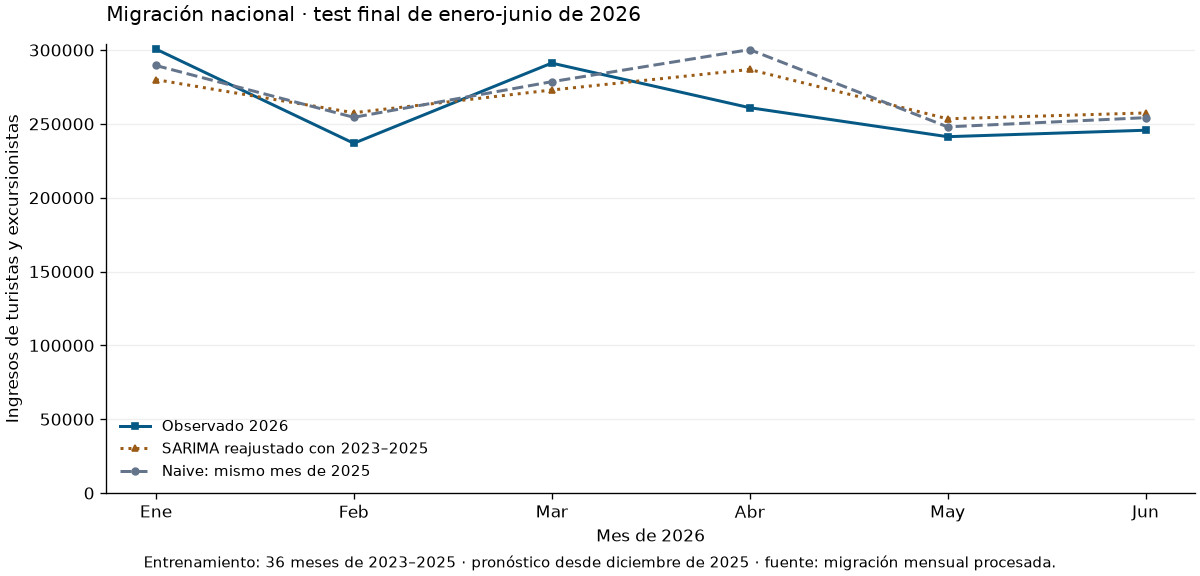

In [31]:
prediccion_sarima_test = ajuste_sarima_final.forecast(steps=len(test_final_nacional)) * factor_unidad
fechas_referencia_test = test_final_nacional.index - pd.DateOffset(years=1)
prediccion_naive_test = pd.Series(
    entrenamiento_final_nacional.reindex(fechas_referencia_test).to_numpy(dtype=float),
    index=test_final_nacional.index, name="naive_estacional",
)
for prediccion in [prediccion_sarima_test, prediccion_naive_test]:
    assert prediccion.index.equals(test_final_nacional.index)
    assert np.isfinite(prediccion.to_numpy()).all() and prediccion.ge(0).all()

metricas_test_final = pd.DataFrame([
    {"modelo": "SARIMA seleccionado", **evaluar_pronostico(
        test_final_nacional, prediccion_sarima_test, escala_mase_final_nacional)},
    {"modelo": "Naive estacional", **evaluar_pronostico(
        test_final_nacional, prediccion_naive_test, escala_mase_final_nacional)},
])
detalle_test_final = pd.DataFrame({
    "observado": test_final_nacional,
    "SARIMA": prediccion_sarima_test,
    "naive_estacional": prediccion_naive_test,
})
detalle_test_final["error_SARIMA"] = detalle_test_final["observado"] - detalle_test_final["SARIMA"]
detalle_test_final["error_naive"] = detalle_test_final["observado"] - detalle_test_final["naive_estacional"]
display(metricas_test_final.round(3))
display(detalle_test_final.round(2))

figura_test_final, eje_test_final = plt.subplots(figsize=(10, 4.8), layout="constrained")
for nombre, columna, color, estilo, marcador in [
    ("Observado 2026", "observado", "#075985", "-", "s"),
    ("SARIMA reajustado con 2023–2025", "SARIMA", "#9A5B16", ":", "^"),
    ("Naive: mismo mes de 2025", "naive_estacional", "#64748B", "--", "o"),
]:
    eje_test_final.plot(range(1, 7), detalle_test_final[columna], label=nombre,
                       color=color, linestyle=estilo, marker=marcador, linewidth=1.8, markersize=4)
eje_test_final.set_title("Migración nacional · test final de enero-junio de 2026", loc="left", pad=14)
eje_test_final.set_xlabel("Mes de 2026")
eje_test_final.set_ylabel("Ingresos de turistas y excursionistas")
eje_test_final.set_xticks(range(1, 7), meses_grafico[:6])
eje_test_final.set_ylim(bottom=0)
eje_test_final.grid(axis="y", alpha=0.2)
eje_test_final.spines[["top", "right"]].set_visible(False)
eje_test_final.legend(frameon=False, fontsize=9, loc="lower left")
figura_test_final.supxlabel("Entrenamiento: 36 meses de 2023–2025 · pronóstico desde diciembre de 2025 · fuente: migración mensual procesada.", fontsize=9)
display(figura_test_final)
plt.close(figura_test_final)


### **4.33. Control del reajuste y alcance de los resultados**

Se revisan los errores de un paso estandarizados del entrenamiento de 36 meses, con Ljung–Box hasta el rezago seis y un grado de libertad de modelo por el término AR anual. Este control se calcula sobre el entrenamiento, no sobre los seis errores del test. No se utiliza para modificar la configuración después de abrir la evaluación final ni confirma por sí solo que no quede dependencia estacional.


In [32]:
inicio_residuos_final = int(ajuste_sarima_final.loglikelihood_burn)
residuos_sarima_final = ajuste_sarima_final.filter_results.standardized_forecasts_error[0][inicio_residuos_final:]
assert np.isfinite(residuos_sarima_final).all()
control_residuos_final = acorr_ljungbox(
    residuos_sarima_final, lags=[6], model_df=1, return_df=True,
)
display(control_residuos_final.rename(columns={
    "lb_stat": "estadistico_Ljung_Box", "lb_pvalue": "valor_p",
}).rename_axis("rezago").round(5))


,estadistico_Ljung_Box,valor_p
rezago,,
6,3.24532,0.66222


### **4.34. Lectura del test y cierre de la referencia nacional**

El SARIMA seleccionado se reajustó con los 36 meses de 2023-2025 y convergió sin advertencias. Se conservaron los órdenes definidos antes del test. La escala MASE obtenida solo del entrenamiento fue de aproximadamente 26.730,94 ingresos, a partir de 24 diferencias estacionales. Ljung–Box sobre el entrenamiento no detectó autocorrelación al 5 % con la especificación elegida, con valor p aproximado de 0,662; este resultado no demuestra que el modelo capture toda la estructura anual.

| Método | MAE en ingresos | RMSE en ingresos | MASE |
|---|---:|---:|---:|
| SARIMA seleccionado | 18.217,14 | 18.893,90 | 0,682 |
| Naive estacional | 15.972,69 | 19.392,25 | 0,598 |

El resultado del test es mixto: **naive conserva el menor MAE y MASE, mientras SARIMA obtiene el menor RMSE**. El error absoluto medio de SARIMA fue aproximadamente 14,1 % mayor. Sin embargo, redujo algunos errores grandes: en abril sobreestimó los ingresos en alrededor de 25.871, frente a 39.337 del naive. Eso ayuda a entender por qué RMSE favorece a SARIMA aunque su MAE sea mayor.

No se compara directamente el MASE de este test con el de 2025 para afirmar una mejora o deterioro: cambian la escala, el entrenamiento y el horizonte. La comparación válida aquí enfrenta los dos métodos sobre los mismos seis meses y con la misma escala.

Se mantiene SARIMA como modelo ajustado elegido, documentando que el naive fue superior en MAE tanto en validación como en test. No se cambian los órdenes ni se elige retrospectivamente una métrica para afirmar superioridad general. Los seis meses evaluados no incluyen diciembre y no permiten asegurar el comportamiento durante un año completo.

Con ello queda ejecutada la comprobación nacional reservada. No se inicia otra búsqueda ni se utiliza este test para modificar el modelo y presentar después su resultado como una evaluación independiente.

Estas métricas corresponden a ingresos nacionales. Sigue pendiente evaluar cómo relacionar esa información con las visitas de los municipios. Las cantidades nacionales reales de enero y febrero de 2026 ya están disponibles y no se reemplazarán automáticamente con estas predicciones.


## **5. Relación con las visitas de los municipios**

### **5.1. Preparación de la tabla mensual municipal**

Primero se prepara una tabla donde cada fila representa un mes, un municipio y un origen. La cantidad que queremos estimar es `visitantes`. Todavía no se cruza esta tabla con migración ni se calculan factores o predicciones municipales.

Se utiliza `movilidad_mensual_atitlan.csv`. Los registros cuyo país es Guatemala se agrupan como nacionales y los demás países conocidos como extranjeros. Los registros sin país se conservan aparte como país no identificado: no hay información para asignarlos a uno de los dos orígenes.

Dentro de cada combinación de mes, municipio y origen, se suman las cantidades de los países y de las dos categorías de permanencia. Se utiliza la estructura de categorías de la fuente, sin mover registros entre ellas. `dias_persona` no participa porque el objetivo es la cantidad mensual de visitantes. No se suman municipios para obtener un total del lago ni se mezclan nacionales con extranjeros.


In [33]:
import numpy as np
from config import MUNICIPIOS

ruta_movilidad_mensual = ruta("movilidad_mensual", "movilidad_mensual_atitlan")
movilidad_mensual = pd.read_csv(
    ruta_movilidad_mensual,
    na_values=[NULO_CSV], keep_default_na=False, parse_dates=["fecha"],
    dtype={"destino": "string", "pais": "string", "visitantes": "Float64"},
)
assert set(movilidad_mensual["destino"].dropna()) == MUNICIPIOS
assert movilidad_mensual["destino"].notna().all() and movilidad_mensual["fecha"].notna().all()
assert movilidad_mensual["fecha"].eq(movilidad_mensual["fecha"].dt.to_period("M").dt.to_timestamp()).all()
assert np.isfinite(movilidad_mensual["visitantes"].to_numpy(dtype=float)).all()
assert movilidad_mensual["visitantes"].ge(0).all()
assert set(movilidad_mensual["es_consecutivo"].unique()) == {"menor a 1 dia", "mayor a 1 dia"}

# Vista de análisis: no se modifica el archivo procesado ni se escribe otra salida.
movilidad_con_origen = movilidad_mensual.copy()
pais_clasificacion = movilidad_con_origen["pais"].str.strip().str.casefold()
pais_conocido = pais_clasificacion.notna() & pais_clasificacion.ne("")
movilidad_con_origen["origen"] = pd.Series(pd.NA, index=movilidad_con_origen.index, dtype="string")
movilidad_con_origen.loc[pais_conocido & pais_clasificacion.eq("guatemala"), "origen"] = "Nacionales"
movilidad_con_origen.loc[pais_conocido & pais_clasificacion.ne("guatemala"), "origen"] = "Extranjeros"

registros_sin_origen = movilidad_con_origen.loc[
    movilidad_con_origen["origen"].isna(),
    ["fecha", "destino", "pais", "es_consecutivo", "visitantes"],
].copy()
registros_con_origen = movilidad_con_origen.loc[movilidad_con_origen["origen"].notna()].copy()

tabla_municipal = (
    registros_con_origen.groupby(["fecha", "destino", "origen"], as_index=False)["visitantes"]
    .sum(min_count=1)
    .rename(columns={"destino": "municipio"})
    .sort_values(["fecha", "municipio", "origen"]).reset_index(drop=True)
)
assert not tabla_municipal.duplicated(["fecha", "municipio", "origen"]).any()
assert tabla_municipal["visitantes"].notna().all()


### **5.2. Primeras cinco filas**

- **Fecha:** mes al que corresponde la cantidad de visitantes.
- **Municipio:** municipio del lago al que corresponde el registro.
- **Origen:** nacionales o extranjeros, según el país registrado en la fuente.
- **Visitantes:** cantidad mensual del municipio y origen indicados, sumando los países y categorías de permanencia correspondientes.

Cada fila sigue siendo una medida municipal. La misma persona podría aparecer en distintos municipios o meses; esta tabla no representa un conteo de personas únicas de todo el lago ni de varios meses juntos. Las cantidades conservan sus decimales para los cálculos.


In [34]:
display(tabla_municipal.head())
display(pd.DataFrame([{
    "filas_de_origen": len(movilidad_mensual),
    "registros_con_origen_identificado": len(registros_con_origen),
    "registros_sin_pais_apartados": len(registros_sin_origen),
    "filas_municipales_agregadas": len(tabla_municipal),
    "municipios": tabla_municipal["municipio"].nunique(),
    "meses_observados": tabla_municipal["fecha"].nunique(),
    "origenes_analizados": tabla_municipal["origen"].nunique(),
}]))


,fecha,municipio,origen,visitantes
0,2025-09-01,Panajachel,Extranjeros,10273.413284
1,2025-09-01,Panajachel,Nacionales,196231.782856
2,2025-09-01,San Antonio Palopo,Extranjeros,2201.205066
3,2025-09-01,San Antonio Palopo,Nacionales,52750.404643
4,2025-09-01,San Juan La Laguna,Extranjeros,6548.071967


,filas_de_origen,registros_con_origen_identificado,registros_sin_pais_apartados,filas_municipales_agregadas,municipios,meses_observados,origenes_analizados
0,9860,9835,25,200,10,10,2


### **5.3. Conservación de las cantidades y país no identificado**

Se comprueba la suma por mes y municipio, sin formar un total turístico del lago. La suma de los dos orígenes identificados más las cantidades con país desconocido debe coincidir con la fuente para esa misma combinación. Esta conciliación es únicamente un control de agregación: no se presenta como indicador combinado de nacionales y extranjeros ni calcula participaciones entre sus cantidades.

Los registros sin país permanecen en una tabla separada y en la fuente. La tabla de revisión indica en qué meses y municipios aparecen; sus cantidades no se añaden al segmento extranjero por descarte.


In [35]:
claves_conciliacion = ["fecha", "destino"]
suma_fuente = movilidad_con_origen.groupby(claves_conciliacion)["visitantes"].sum(min_count=1)
suma_identificada = registros_con_origen.groupby(claves_conciliacion)["visitantes"].sum(min_count=1)
suma_sin_origen = registros_sin_origen.groupby(claves_conciliacion)["visitantes"].sum(min_count=1)
control_agregacion = pd.DataFrame({
    "fuente": suma_fuente,
    "origen_identificado": suma_identificada.reindex(suma_fuente.index, fill_value=0),
    "pais_no_identificado": suma_sin_origen.reindex(suma_fuente.index, fill_value=0),
})
control_agregacion["diferencia"] = (
    control_agregacion["fuente"]
    - control_agregacion["origen_identificado"]
    - control_agregacion["pais_no_identificado"]
)
assert np.allclose(control_agregacion["diferencia"].to_numpy(dtype=float), 0, rtol=0, atol=1e-7), "La agrupación no conserva las cantidades."

# Control adicional por origen: comprueba la tabla final sin mezclar segmentos.
reconstruccion_origen = tabla_municipal.rename(columns={"municipio": "destino"}).set_index(["fecha", "destino", "origen"])["visitantes"].sort_index()
referencia_origen = registros_con_origen.groupby(["fecha", "destino", "origen"])["visitantes"].sum(min_count=1).sort_index()
assert reconstruccion_origen.index.equals(referencia_origen.index)
assert np.allclose(reconstruccion_origen.to_numpy(dtype=float), referencia_origen.to_numpy(dtype=float), rtol=0, atol=1e-7)
assert len(registros_con_origen) + len(registros_sin_origen) == len(movilidad_mensual)

revision_sin_pais = (
    registros_sin_origen.groupby(["fecha", "destino"], as_index=False)
    .agg(registros_sin_pais=("visitantes", "size"), visitantes_sin_pais=("visitantes", "sum"))
    .rename(columns={"destino": "municipio"})
)
display(pd.DataFrame([{
    "combinaciones_mes_municipio_revisadas": len(control_agregacion),
    "cantidades_conservadas": bool(np.allclose(control_agregacion["diferencia"].to_numpy(dtype=float), 0, rtol=0, atol=1e-7)),
    "origenes_sin_reclasificar": len(registros_sin_origen),
}]))
display(revision_sin_pais)


,combinaciones_mes_municipio_revisadas,cantidades_conservadas,origenes_sin_reclasificar
0,100,True,25


,fecha,municipio,registros_sin_pais,visitantes_sin_pais
0,2025-11-01,Panajachel,1,2.0
1,2025-11-01,San Antonio Palopo,1,1.0
2,2025-11-01,San Juan La Laguna,1,1.0
3,2025-11-01,San Pedro La Laguna,2,2.0
4,2025-11-01,Santiago Atitlan,2,2.0
5,2026-03-01,Panajachel,1,1.0
6,2026-03-01,San Juan La Laguna,1,1.0
7,2026-03-01,San Marcos La Laguna,1,1.0
8,2026-03-01,San Pedro La Laguna,1,1.0
9,2026-06-01,Santiago Atitlan,1,1.0


### **5.4. Meses disponibles por origen**

Se cuenta cuántos municipios tienen observación en cada mes para nacionales y extranjeros. Un cero en esta tabla significa **cero municipios con dato**, no cero visitantes. No se rellenan las cantidades faltantes de enero y febrero de 2026.


In [36]:
calendario_municipal = pd.date_range(
    tabla_municipal["fecha"].min(), tabla_municipal["fecha"].max(), freq="MS",
)
cobertura_municipal = (
    tabla_municipal.groupby(["fecha", "origen"])["municipio"].nunique().unstack("origen")
    .reindex(index=calendario_municipal, columns=["Nacionales", "Extranjeros"])
    .fillna(0).astype(int).rename_axis(index="fecha", columns=None)
)
cobertura_municipal["estado"] = cobertura_municipal.apply(
    lambda fila: "Sin observaciones" if fila.eq(0).all()
    else "10 municipios en ambos orígenes" if fila.eq(len(MUNICIPIOS)).all()
    else "Cobertura parcial: revisar", axis=1,
)

# Verificar que cada mes observado contenga los diez municipios en los dos orígenes.
combinaciones_esperadas = pd.MultiIndex.from_product([
    sorted(tabla_municipal["fecha"].unique()), sorted(MUNICIPIOS), ["Extranjeros", "Nacionales"],
], names=["fecha", "municipio", "origen"])
combinaciones_observadas = pd.MultiIndex.from_frame(tabla_municipal[["fecha", "municipio", "origen"]])
assert len(combinaciones_observadas.difference(combinaciones_esperadas)) == 0
assert len(combinaciones_esperadas.difference(combinaciones_observadas)) == 0
display(cobertura_municipal)


,Nacionales,Extranjeros,estado
fecha,,,
2025-09-01,10,10,10 municipios en ambos orígenes
2025-10-01,10,10,10 municipios en ambos orígenes
2025-11-01,10,10,10 municipios en ambos orígenes
2025-12-01,10,10,10 municipios en ambos orígenes
2026-01-01,0,0,Sin observaciones
2026-02-01,0,0,Sin observaciones
2026-03-01,10,10,10 municipios en ambos orígenes
2026-04-01,10,10,10 municipios en ambos orígenes
2026-05-01,10,10,10 municipios en ambos orígenes


### **5.5. Resultado de esta preparación**

La tabla municipal contiene 200 filas: diez meses observados, diez municipios y dos orígenes analizados por separado. La cobertura va de septiembre de 2025 a agosto de 2026, con enero y febrero de 2026 sin observaciones. Todos los meses disponibles incluyen los diez municipios y ambos orígenes.

Los 25 registros sin país se conservan aparte y no se asignan a nacionales o extranjeros. La conciliación comprueba que no se perdieron cantidades al agrupar. No se modificó la fuente procesada ni se guardó una nueva salida del pipeline.

En este paso solo se preparó y revisó la tabla local. El cruce con migración, la relación entre ambas fuentes y las estimaciones municipales siguen pendientes.


### **5.6. Cruce por mes con la migración observada**

Se agrega a cada fila municipal la cantidad de ingresos nacionales registrada en el mismo mes. El cruce utiliza `fecha`, porque la migración es una referencia de todo el país y no tiene una cantidad particular para cada municipio. Se utilizan valores observados, no las predicciones nacionales de SARIMA.

La tabla local se conserva completa. Se prepara una vista con los meses donde ambas fuentes tienen datos y otra con los registros locales sin referencia migratoria. La referencia nacional se repite para los municipios y orígenes de un mismo mes; esas repeticiones no representan nuevas observaciones nacionales independientes.

Los dos orígenes se revisan por separado. La migración mide ingresos al país y no viajes internos de residentes de Guatemala, de modo que usarla como referencia para nacionales es una aproximación que deberá justificarse con su relación y su error municipal.


In [37]:
migracion_para_cruce = migracion[["fecha", "viajeros"]].rename(
    columns={"viajeros": "ingresos_migratorios_observados"}
).copy()
assert not migracion_para_cruce["fecha"].duplicated().any()

cruce_municipal_migracion = tabla_municipal.merge(
    migracion_para_cruce, on="fecha", how="left", validate="many_to_one",
    indicator="coincidencia_migracion",
)
assert len(cruce_municipal_migracion) == len(tabla_municipal)
assert not cruce_municipal_migracion.duplicated(["fecha", "municipio", "origen"]).any()
clave_local = ["fecha", "municipio", "origen"]
assert np.allclose(
    cruce_municipal_migracion.set_index(clave_local)["visitantes"].sort_index().to_numpy(dtype=float),
    tabla_municipal.set_index(clave_local)["visitantes"].sort_index().to_numpy(dtype=float),
    rtol=0, atol=1e-7,
), "El cruce alteró las cantidades locales."

meses_con_ambas_fuentes = cruce_municipal_migracion.loc[
    cruce_municipal_migracion["ingresos_migratorios_observados"].notna()
].drop(columns="coincidencia_migracion").copy()
registros_locales_sin_migracion = cruce_municipal_migracion.loc[
    cruce_municipal_migracion["ingresos_migratorios_observados"].isna()
].copy()
assert meses_con_ambas_fuentes["ingresos_migratorios_observados"].gt(0).all()

cobertura_cruce = cobertura_municipal[["Nacionales", "Extranjeros"]].copy()
referencia_por_fecha = migracion_para_cruce.set_index("fecha")["ingresos_migratorios_observados"]
cobertura_cruce["migracion_observada_disponible"] = referencia_por_fecha.reindex(cobertura_cruce.index).notna()
cobertura_cruce["visitas_municipales_disponibles"] = cobertura_cruce[["Nacionales", "Extranjeros"]].gt(0).all(axis=1)
cobertura_cruce["ambas_fuentes_disponibles"] = (
    cobertura_cruce["migracion_observada_disponible"] & cobertura_cruce["visitas_municipales_disponibles"]
)
display(cobertura_cruce)
display(pd.DataFrame([{
    "filas_locales_conservadas": len(cruce_municipal_migracion),
    "meses_coincidentes": meses_con_ambas_fuentes["fecha"].nunique(),
    "filas_con_ambas_fuentes": len(meses_con_ambas_fuentes),
    "filas_locales_sin_migracion": len(registros_locales_sin_migracion),
    "meses_locales_sin_migracion": registros_locales_sin_migracion["fecha"].nunique(),
}]))
display(meses_con_ambas_fuentes.head())


,Nacionales,Extranjeros,migracion_observada_disponible,visitas_municipales_disponibles,ambas_fuentes_disponibles
fecha,,,,,
2025-09-01,10,10,True,True,True
2025-10-01,10,10,True,True,True
2025-11-01,10,10,True,True,True
2025-12-01,10,10,True,True,True
2026-01-01,0,0,True,False,False
2026-02-01,0,0,True,False,False
2026-03-01,10,10,True,True,True
2026-04-01,10,10,True,True,True
2026-05-01,10,10,True,True,True


,filas_locales_conservadas,meses_coincidentes,filas_con_ambas_fuentes,filas_locales_sin_migracion,meses_locales_sin_migracion
0,200,8,160,40,2


,fecha,municipio,origen,visitantes,ingresos_migratorios_observados
0,2025-09-01,Panajachel,Extranjeros,10273.413284,218069.511221
1,2025-09-01,Panajachel,Nacionales,196231.782856,218069.511221
2,2025-09-01,San Antonio Palopo,Extranjeros,2201.205066,218069.511221
3,2025-09-01,San Antonio Palopo,Nacionales,52750.404643,218069.511221
4,2025-09-01,San Juan La Laguna,Extranjeros,6548.071967,218069.511221


### **5.7. Primera lectura: Panajachel**

Se empieza con un municipio como ejemplo de lectura, sin asumir que represente a los otros nueve. La tabla muestra sus cantidades reales y la referencia nacional de los ocho meses coincidentes.

Para el gráfico, cada serie toma **su propio valor de septiembre de 2025 como 100**. Por ejemplo, 120 significa que esa serie está 20 % por encima de su propio septiembre; no significa 120 visitantes ni una participación en el total nacional. Así se comparan movimientos relativos de cantidades con niveles distintos, sin convertir extranjeros y nacionales en porcentajes de un mismo total.

Nacionales y extranjeros se muestran en paneles separados con escala común. La misma referencia de migración se repite en ambos. Enero y febrero quedan como huecos visibles en la comparación porque faltan las visitas locales, aunque sí exista migración observada para esos meses. Julio-agosto quedan fuera de este gráfico pareado porque no hay migración observada; sus visitas siguen en la tabla local.


,Extranjeros,Nacionales,ingresos_migratorios_observados
fecha,,,
2025-09-01,10273.413284,196231.782856,218069.511221
2025-10-01,11651.309147,185522.494819,255920.932322
2025-11-01,20242.810939,211591.536826,310585.520107
2025-12-01,22021.044792,246474.379839,365573.021807
2026-03-01,25225.234864,201122.425364,291160.3657
2026-04-01,23183.696764,221860.842878,260951.045612
2026-05-01,17925.301876,201259.156103,241312.295259
2026-06-01,14406.381292,208620.442121,245687.580977


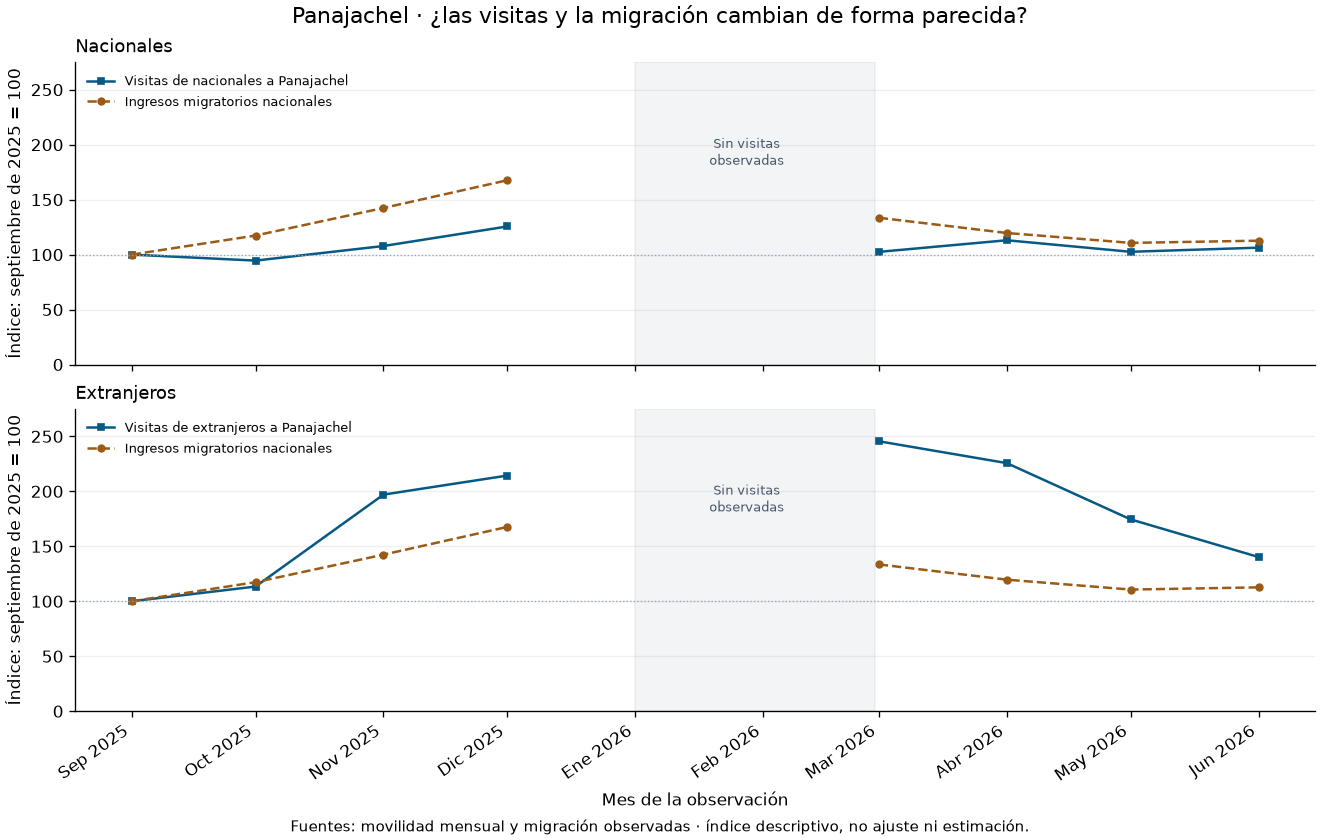

In [38]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

municipio_ejemplo = "Panajachel"
ejemplo_municipal = meses_con_ambas_fuentes.loc[
    meses_con_ambas_fuentes["municipio"].eq(municipio_ejemplo)
].copy()
visitas_ejemplo = ejemplo_municipal.pivot(index="fecha", columns="origen", values="visitantes")
referencia_ejemplo = ejemplo_municipal.groupby("fecha")["ingresos_migratorios_observados"].first()
tabla_ejemplo_municipal = visitas_ejemplo.join(referencia_ejemplo).rename_axis(columns=None)
display(tabla_ejemplo_municipal)

mes_base_comparacion = tabla_ejemplo_municipal.index.min()
assert mes_base_comparacion == pd.Timestamp("2025-09-01")
assert tabla_ejemplo_municipal.loc[mes_base_comparacion].gt(0).all()
indices_ejemplo_municipal = tabla_ejemplo_municipal.div(
    tabla_ejemplo_municipal.loc[mes_base_comparacion]
) * 100
calendario_comparacion = pd.date_range(
    tabla_ejemplo_municipal.index.min(), tabla_ejemplo_municipal.index.max(), freq="MS",
)
# Mantener NaN para romper las líneas durante el hueco de movilidad local.
indices_ejemplo_municipal = indices_ejemplo_municipal.reindex(calendario_comparacion)
assert indices_ejemplo_municipal.loc["2026-01-01":"2026-02-01"].isna().all().all()
limite_superior_indice = max(120, float(indices_ejemplo_municipal.max().max()) * 1.12)
figura_cruce_municipal, ejes_cruce_municipal = plt.subplots(2, 1, figsize=(11, 7), sharex=True, sharey=True, layout="constrained")
meses_texto_cruce = {9: "Sep", 10: "Oct", 11: "Nov", 12: "Dic", 1: "Ene", 2: "Feb", 3: "Mar", 4: "Abr", 5: "May", 6: "Jun"}
for eje, origen in zip(ejes_cruce_municipal, ["Nacionales", "Extranjeros"]):
    eje.plot(indices_ejemplo_municipal.index,
             indices_ejemplo_municipal[origen].to_numpy(dtype=float, na_value=np.nan),
             label=f"Visitas de {origen.lower()} a {municipio_ejemplo}",
             color="#075985", marker="s", markersize=4)
    eje.plot(indices_ejemplo_municipal.index,
             indices_ejemplo_municipal["ingresos_migratorios_observados"].to_numpy(dtype=float, na_value=np.nan),
             label="Ingresos migratorios nacionales", color="#9A5B16", linestyle="--", marker="o", markersize=4)
    eje.axhline(100, color="#94A3B8", linewidth=0.8, linestyle=":")
    eje.axvspan(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-02-28"), color="#64748B", alpha=0.08)
    eje.set_title(origen, loc="left", fontsize=11)
    eje.set_ylabel("Índice: septiembre de 2025 = 100")
    eje.set_ylim(0, limite_superior_indice)
    eje.grid(axis="y", alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(frameon=False, fontsize=8, loc="upper left")
    eje.text(pd.Timestamp("2026-01-28"), limite_superior_indice * 0.7,
             "Sin visitas\nobservadas", ha="center", va="center", fontsize=8, color="#475569")
ejes_cruce_municipal[-1].set_xticks(calendario_comparacion)
ejes_cruce_municipal[-1].set_xticklabels([
    f"{meses_texto_cruce[fecha.month]} {fecha.year}" for fecha in calendario_comparacion
], rotation=35, ha="right")
ejes_cruce_municipal[-1].set_xlabel("Mes de la observación")
figura_cruce_municipal.suptitle(f"{municipio_ejemplo} · ¿las visitas y la migración cambian de forma parecida?", fontsize=13)
figura_cruce_municipal.supxlabel("Fuentes: movilidad mensual y migración observadas · índice descriptivo, no ajuste ni estimación.", fontsize=9)
display(figura_cruce_municipal)
plt.close(figura_cruce_municipal)


### **5.8. Resultado del cruce y alcance de esta primera lectura**

Las fuentes coinciden en septiembre-diciembre de 2025 y marzo-junio de 2026: ocho meses por municipio y origen, que producen 160 filas pareadas. Hay 40 filas locales de julio-agosto sin referencia migratoria observada; se conservan sin inventar esa referencia. Las 160 filas no equivalen a 160 meses independientes: cada serie municipal sigue teniendo solo ocho meses coincidentes.

En el ejemplo de Panajachel, migración y visitas nacionales aumentan en diciembre respecto a noviembre, pero sus variaciones no son idénticas. Las visitas extranjeras alcanzan su mayor cantidad de estos ocho meses en marzo de 2026, mientras que la migración alcanza su máximo en diciembre de 2025. La referencia nacional no reproduce automáticamente todos los movimientos locales.

Este gráfico permite reconocer diferencias, pero no demuestra causalidad ni justifica todavía un factor de calibración. Tampoco permite trasladar el comportamiento de Panajachel a todos los municipios. El índice se usa solo para visualizar la forma: no será un predictor normalizado con datos de validación ni una proporción de turistas del país que visitan el municipio.

En este paso no se calcularon factores, correlaciones inferenciales ni predicciones de visitas municipales. El siguiente análisis deberá revisar por municipio y origen si la referencia ofrece un apoyo útil, antes de definir cómo calibrarla y validarla.


### **5.9. Relación descriptiva en los diez municipios**

Después del ejemplo de Panajachel, se revisa cada municipio y origen con los mismos ocho meses coincidentes. Se calcula la correlación lineal de Pearson entre sus visitantes y los ingresos migratorios observados del mismo mes, sin sumar municipios ni combinar orígenes.

La correlación resume cómo se relacionan las cantidades en estos meses:

- **Cerca de 1:** las cantidades muestran una asociación lineal positiva; los meses con más ingresos migratorios tienden a tener más visitas locales.
- **Cerca de 0:** no se observa una asociación lineal marcada; podrían existir otras relaciones que este resumen no detecta.
- **Cerca de −1:** las cantidades muestran una asociación lineal negativa; los meses con más ingresos migratorios tienden a tener menos visitas locales.

El resultado no es un porcentaje de visitantes, una medida de precisión ni un factor para multiplicar la migración. Una correlación alta no demuestra causalidad y tampoco garantiza una proporción constante entre las dos cantidades.

Con ocho meses por serie, algunos puntos pueden influir mucho. Se utiliza el coeficiente como descripción exploratoria, sin valores p, pruebas de significancia o afirmaciones sobre una relación estable en otros meses. Las observaciones están ordenadas en el tiempo y no se tratan como una muestra independiente para hacer inferencia. Este diagnóstico utiliza todos los meses coincidentes; cuando se evalúe un ajuste, los meses reservados no se usarán para calcular sus parámetros o seleccionar variantes sin declararlo.

Referencia conceptual: [coeficiente de Pearson en la documentación de SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html).


In [39]:
filas_relacion_municipal = []
for (municipio, origen), grupo in meses_con_ambas_fuentes.groupby(["municipio", "origen"]):
    grupo = grupo.sort_values("fecha")
    visitantes = grupo["visitantes"].to_numpy(dtype=float)
    ingresos = grupo["ingresos_migratorios_observados"].to_numpy(dtype=float)
    assert np.isfinite(visitantes).all() and np.isfinite(ingresos).all()
    assert not grupo["fecha"].duplicated().any()
    relacion_definida = len(grupo) >= 3 and np.std(visitantes) > 0 and np.std(ingresos) > 0
    correlacion = float(np.corrcoef(visitantes, ingresos)[0, 1]) if relacion_definida else np.nan
    filas_relacion_municipal.append({
        "municipio": municipio, "origen": origen,
        "meses_comparados": len(grupo),
        "correlacion_Pearson": correlacion,
        "estado": "Calculable" if relacion_definida else "No definida: revisar variación o cobertura",
    })

relacion_municipal = pd.DataFrame(filas_relacion_municipal)
assert len(relacion_municipal) == len(MUNICIPIOS) * 2
assert relacion_municipal["meses_comparados"].eq(8).all()
assert relacion_municipal["correlacion_Pearson"].between(-1, 1).all()
resumen_relacion_municipal = relacion_municipal.pivot(
    index="municipio", columns="origen", values="correlacion_Pearson",
).reindex(columns=["Nacionales", "Extranjeros"]).sort_index().rename_axis(columns=None)
resumen_relacion_municipal["meses_por_origen"] = relacion_municipal.groupby("municipio")["meses_comparados"].min()
display(resumen_relacion_municipal.round(3))


,Nacionales,Extranjeros,meses_por_origen
municipio,,,
Panajachel,0.756,0.637,8
San Antonio Palopo,-0.152,0.259,8
San Juan La Laguna,0.396,0.808,8
San Lucas Toliman,0.403,0.951,8
San Marcos La Laguna,-0.405,0.446,8
San Pablo La Laguna,0.454,0.787,8
San Pedro La Laguna,0.516,0.698,8
Santa Catarina Palopo,0.466,0.836,8
Santa Cruz La Laguna,0.340,0.895,8


### **5.10. Comparación visual de la asociación**

Cada punto representa la correlación de un municipio y un origen con la misma referencia migratoria nacional. Los paneles comparten la escala de −1 a 1 y el orden de los municipios. El cero indica ausencia de asociación lineal en este resumen, no ausencia de visitantes ni independencia entre las variables.

El gráfico no ordena municipios por importancia turística ni por cantidad de visitantes. Tampoco clasifica automáticamente cuáles pueden modelarse: la utilidad de la referencia se comprobará después con errores sobre meses locales reservados.


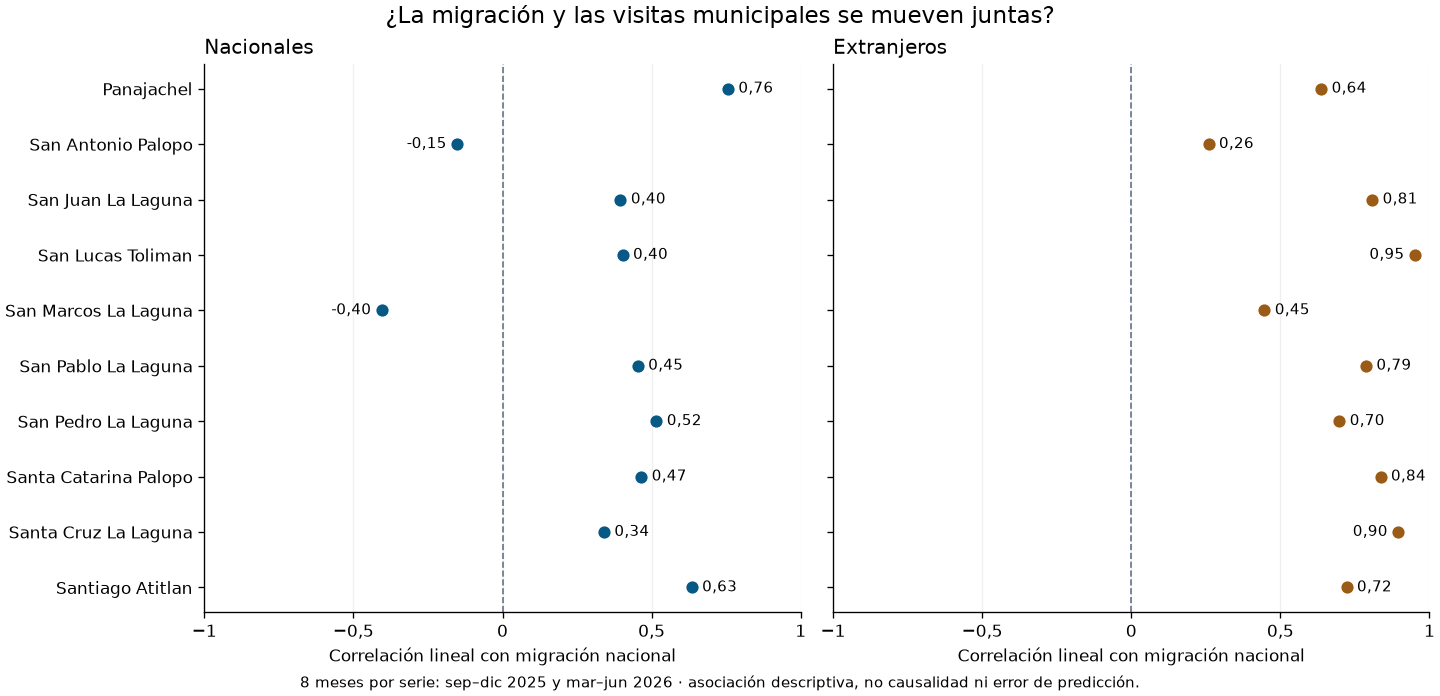

In [40]:
figura_relacion_municipal, ejes_relacion_municipal = plt.subplots(
    1, 2, figsize=(12, 5.8), sharex=True, sharey=True, layout="constrained",
)
posiciones_municipios = np.arange(len(resumen_relacion_municipal))
for eje, origen, color in zip(ejes_relacion_municipal, ["Nacionales", "Extranjeros"], ["#075985", "#9A5B16"]):
    valores = resumen_relacion_municipal[origen].to_numpy(dtype=float)
    eje.scatter(valores, posiciones_municipios, color=color, s=40, zorder=3)
    eje.axvline(0, color="#64748B", linestyle="--", linewidth=1)
    eje.set_title(origen, loc="left")
    eje.set_xlim(-1, 1)
    eje.set_xticks([-1, -0.5, 0, 0.5, 1], ["−1", "−0,5", "0", "0,5", "1"])
    eje.set_xlabel("Correlación lineal con migración nacional")
    eje.set_yticks(posiciones_municipios, resumen_relacion_municipal.index)
    eje.grid(axis="x", alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)
    for posicion, valor in zip(posiciones_municipios, valores):
        hacia_izquierda = valor > 0.85 or valor < 0
        desplazamiento = -0.035 if hacia_izquierda else 0.035
        eje.text(valor + desplazamiento, posicion, f"{valor:.2f}".replace(".", ","),
                 va="center", ha="right" if hacia_izquierda else "left", fontsize=9)
ejes_relacion_municipal[0].invert_yaxis()
figura_relacion_municipal.suptitle("¿La migración y las visitas municipales se mueven juntas?", fontsize=14)
figura_relacion_municipal.supxlabel(
    "8 meses por serie: sep–dic 2025 y mar–jun 2026 · asociación descriptiva, no causalidad ni error de predicción.",
    fontsize=9,
)
display(figura_relacion_municipal)
plt.close(figura_relacion_municipal)


### **5.11. Lectura antes de plantear un ajuste local**

La relación varía según municipio y origen. En extranjeros, los diez coeficientes son positivos, aunque su magnitud va de aproximadamente 0,259 en San Antonio Palopó a 0,951 en San Lucas Tolimán. Esto muestra una asociación positiva en los meses revisados, no que la migración explique todas las visitas ni que pueda utilizarse con igual precisión en todos los municipios.

En nacionales, San Antonio Palopó tiene una correlación aproximada de −0,152 y San Marcos La Laguna de −0,405. En Panajachel es positiva, de aproximadamente 0,756. Por tanto, no podemos asumir una respuesta positiva uniforme al movimiento internacional. La migración no mide directamente los desplazamientos internos y esta diferencia se tendrá presente al justificar el uso de esa referencia.

Con estos ocho meses no se puede afirmar que las relaciones se mantengan en enero y febrero ni elegir un procedimiento únicamente por correlación. Una correlación alta tampoco determina una conversión proporcional: esa es otra suposición que requiere revisión y validación.

Todavía no se ajustaron factores o modelos municipales ni se generaron estimaciones. El siguiente paso será discutir una calibración sencilla por municipio y origen, junto con una referencia local que permita comprobar si incorporar migración realmente reduce el error.


### **5.12. Prueba municipal: regresión temporal con migración**

El objetivo de esta prueba es **visitantes mensuales por municipio y origen**, no ingresos nacionales. Se pregunta si añadir migración observada mejora una regresión temporal sencilla. No se comparan sus errores con los del SARIMA nacional, porque ese modelo estimaba otra variable y otra población.

Se fijan tres alternativas para cada municipio y origen:

| Alternativa | Cómo estima visitantes | Propósito |
|---|---|---|
| Mediana local | Repite la mediana de los visitantes de entrenamiento. | Referencia sencilla sin migración. |
| Regresión temporal | Ajusta un nivel y una tendencia lineal con el paso de los meses. | Comparador temporal sencillo, sin componente anual. |
| Regresión temporal + migración | Añade los ingresos migratorios observados del mismo mes a la regresión temporal. | Comprobar el aporte de esa variable manteniendo la tendencia. |

No se intenta ajustar un SARIMA municipal anual con ocho meses. La regresión temporal es un comparador de tendencia, no una representación de todas las familias temporales. Tampoco se añaden variables de calendario estacional o interacciones con una muestra tan corta.

Se utilizan **seis meses para ajustar**: septiembre-diciembre de 2025 y marzo-abril de 2026. Se reservan **mayo-junio de 2026** para comparar, sin introducir sus visitantes en los ajustes. Enero-febrero siguen sin observación; julio-agosto no entran en esta comparación pareada por falta de migración. La posición temporal conserva los saltos reales del calendario.

El escalador de cada regresión se ajusta solo con sus seis filas de entrenamiento. La regresión completa estima tres coeficientes, incluida la constante; seis observaciones dejan muy poco margen. No se ejecuta grid search ni se vuelve a elegir variables después de observar estos errores.

Este es un ejercicio retrospectivo condicionado a migración conocida: se utiliza la migración observada de mayo-junio, disponible en el paquete, como ocurriría al reconstruir enero-febrero. No representa un pronóstico municipal emitido antes de disponer de esos ingresos nacionales.

La evaluación es exploratoria: solo hay dos meses reservados por serie y las correlaciones de las secciones anteriores ya describieron los ocho meses. No se presenta como un test final completamente independiente de las decisiones de desarrollo ni garantiza el comportamiento de enero-febrero.

Referencias: [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) y [prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).


In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

base_regresion_municipal = meses_con_ambas_fuentes.copy()
base_regresion_municipal["paso_temporal"] = (
    (base_regresion_municipal["fecha"].dt.year - 2025) * 12
    + base_regresion_municipal["fecha"].dt.month - 9
)
fechas_ajuste_local = pd.DatetimeIndex([
    "2025-09-01", "2025-10-01", "2025-11-01", "2025-12-01", "2026-03-01", "2026-04-01",
])
fechas_prueba_local = pd.DatetimeIndex(["2026-05-01", "2026-06-01"])
variables_regresion_local = {
    "Regresión temporal": ["paso_temporal"],
    "Regresión temporal + migración": ["paso_temporal", "ingresos_migratorios_observados"],
}
assert fechas_ajuste_local.max() < fechas_prueba_local.min()
assert base_regresion_municipal["fecha"].isin(fechas_ajuste_local.union(fechas_prueba_local)).all()
display(pd.DataFrame({
    "fecha": fechas_ajuste_local.append(fechas_prueba_local),
    "uso": ["Ajuste"] * 6 + ["Prueba exploratoria"] * 2,
}))


,fecha,uso
0,2025-09-01,Ajuste
1,2025-10-01,Ajuste
2,2025-11-01,Ajuste
3,2025-12-01,Ajuste
4,2026-03-01,Ajuste
5,2026-04-01,Ajuste
6,2026-05-01,Prueba exploratoria
7,2026-06-01,Prueba exploratoria


### **5.13. Ajuste y errores por municipio y origen**

Se comparan las mismas dos observaciones en los tres métodos. Se reportan MAE y RMSE en visitantes por mes. No se calcula MASE estacional de período doce porque no hay suficientes meses locales para formar su escala; tampoco se utiliza la escala nacional para puntuar visitantes municipales.

Las cantidades no se redondean, se recortan ni se mezclan entre orígenes para calcular los errores. Se conservan parámetros y predicciones para revisar cada serie. Los coeficientes son ajustes estadísticos entre universos distintos: no representan porcentajes reales de personas que ingresan al país y después visitan un municipio.


In [42]:
modelos_regresion_local = {}
filas_predicciones_locales = []
filas_metricas_locales = []
filas_controles_locales = []
filas_coeficientes_locales = []
for (municipio, origen), grupo in base_regresion_municipal.groupby(["municipio", "origen"]):
    grupo = grupo.sort_values("fecha")
    ajuste_local = grupo.loc[grupo["fecha"].isin(fechas_ajuste_local)].copy()
    prueba_local = grupo.loc[grupo["fecha"].isin(fechas_prueba_local)].copy()
    assert pd.DatetimeIndex(ajuste_local["fecha"]).equals(fechas_ajuste_local)
    assert pd.DatetimeIndex(prueba_local["fecha"]).equals(fechas_prueba_local)
    objetivo_ajuste = ajuste_local["visitantes"].to_numpy(dtype=float)
    objetivo_prueba = prueba_local["visitantes"].to_numpy(dtype=float)
    predicciones_locales = {"Mediana local": np.repeat(np.median(objetivo_ajuste), len(prueba_local))}

    for nombre, columnas in variables_regresion_local.items():
        modelo = make_pipeline(StandardScaler(), LinearRegression())
        modelo.fit(ajuste_local[columnas], objetivo_ajuste)
        predicciones_locales[nombre] = modelo.predict(prueba_local[columnas])
        modelos_regresion_local[(municipio, origen, nombre)] = modelo
        escalador = modelo.named_steps["standardscaler"]
        regresion = modelo.named_steps["linearregression"]
        matriz_diseno = np.column_stack([np.ones(len(ajuste_local)), escalador.transform(ajuste_local[columnas])])
        assert np.linalg.matrix_rank(matriz_diseno) == len(columnas) + 1, "Diseño sin rango completo."
        assert np.allclose(escalador.mean_, ajuste_local[columnas].mean().to_numpy(dtype=float))
        assert int(escalador.n_samples_seen_) == 6
        coeficientes_originales = regresion.coef_ / escalador.scale_
        intercepto_original = float(regresion.intercept_ - np.sum(regresion.coef_ * escalador.mean_ / escalador.scale_))
        assert np.isfinite(coeficientes_originales).all() and np.isfinite(intercepto_original)
        filas_controles_locales.append({
            "municipio": municipio, "origen": origen, "modelo": nombre,
            "meses_ajuste": len(ajuste_local), "meses_prueba": len(prueba_local),
            "ultimo_mes_ajuste": ajuste_local["fecha"].max(),
            "cantidad_coeficientes": len(columnas) + 1,
            "rango_completo": True,
        })
        filas_coeficientes_locales.append({
            "municipio": municipio, "origen": origen, "modelo": nombre,
            "intercepto": intercepto_original,
            **dict(zip(columnas, coeficientes_originales)),
        })

    for nombre, prediccion in predicciones_locales.items():
        assert np.isfinite(prediccion).all() and (prediccion >= 0).all(), "Predicción inválida; revisar sin recortar."
        errores = objetivo_prueba - prediccion
        filas_metricas_locales.append({
            "municipio": municipio, "origen": origen, "modelo": nombre,
            "meses_prueba": len(prueba_local),
            "MAE": float(np.mean(np.abs(errores))),
            "RMSE": float(np.sqrt(np.mean(errores ** 2))),
        })
        for fecha, real, estimado, error in zip(prueba_local["fecha"], objetivo_prueba, prediccion, errores):
            filas_predicciones_locales.append({
                "fecha": fecha, "municipio": municipio, "origen": origen, "modelo": nombre,
                "observado": real, "estimado": estimado, "error": error,
                "error_absoluto": abs(error), "error_cuadrado": error ** 2,
            })

predicciones_prueba_local = pd.DataFrame(filas_predicciones_locales)
metricas_prueba_local = pd.DataFrame(filas_metricas_locales)
controles_regresion_local = pd.DataFrame(filas_controles_locales)
coeficientes_regresion_local = pd.DataFrame(filas_coeficientes_locales)
comparacion_MAE_local = metricas_prueba_local.pivot(
    index=["municipio", "origen"], columns="modelo", values="MAE",
).reindex(columns=["Mediana local", "Regresión temporal", "Regresión temporal + migración"])
comparacion_MAE_local["mejora_al_agregar_migracion"] = (
    comparacion_MAE_local["Regresión temporal + migración"] < comparacion_MAE_local["Regresión temporal"]
)
comparacion_MAE_local["mejora_frente_mediana"] = (
    comparacion_MAE_local["Regresión temporal + migración"] < comparacion_MAE_local["Mediana local"]
)
display(comparacion_MAE_local.round(2))
display(controles_regresion_local.head())


modelo                             Mediana local  ...  mejora_frente_mediana
municipio             origen                      ...                       
Panajachel            Extranjeros        4966.09  ...                  False
                      Nacionales         3680.64  ...                   True
San Antonio Palopo    Extranjeros         731.27  ...                  False
                      Nacionales        20120.39  ...                   True
San Juan La Laguna    Extranjeros        4022.26  ...                  False
                      Nacionales        12543.89  ...                  False
San Lucas Toliman     Extranjeros         957.40  ...                   True
                      Nacionales         6835.26  ...                  False
San Marcos La Laguna  Extranjeros        1228.59  ...                  False
                      Nacionales         1551.88  ...                  False
San Pablo La Laguna   Extranjeros        2461.67  ...                  False
                      Nacionales         3288.07  ...                  False
San Pedro La Laguna   Extranjeros        5362.62  ...                  False
                      Nacionales        15286.67  ...                   True
Santa Catarina Palopo Extranjeros        1433.16  ...                   True
                      Nacionales         2823.58  ...                  False
Santa Cruz La Laguna  Extranjeros         606.42  ...                   True
                      Nacionales         3478.61  ...                   True
Santiago Atitlan      Extranjeros        3384.87  ...                  False
                      Nacionales         3834.74  ...                   True

[20 rows x 5 columns]

,municipio,origen,modelo,meses_ajuste,meses_prueba,ultimo_mes_ajuste,cantidad_coeficientes,rango_completo
0,Panajachel,Extranjeros,Regresión temporal,6,2,2026-04-01,2,True
1,Panajachel,Extranjeros,Regresión temporal + migración,6,2,2026-04-01,3,True
2,Panajachel,Nacionales,Regresión temporal,6,2,2026-04-01,2,True
3,Panajachel,Nacionales,Regresión temporal + migración,6,2,2026-04-01,3,True
4,San Antonio Palopo,Extranjeros,Regresión temporal,6,2,2026-04-01,2,True


### **5.14. Resumen separado por origen**

El resumen promedia errores, no cantidades turísticas de los municipios. Cada método se evalúa sobre veinte observaciones por origen: diez municipios y dos meses. Se mantiene nacionales separado de extranjeros. MAE es el promedio de los errores absolutos y RMSE se calcula como la raíz del promedio de los errores cuadrados de esas observaciones, sin promediar las raíces de cada municipio.

Los municipios con cantidades grandes pueden aportar errores absolutos mayores y afectar esta lectura agregada. Por eso se conserva la comparación por municipio y el número de series donde mejora cada alternativa. Un promedio menor no significa que todos los municipios mejoren.


,origen,modelo,observaciones_evaluadas,MAE,RMSE
0,Extranjeros,Mediana local,20,2515.44,3220.76
1,Extranjeros,Regresión temporal,20,5804.62,7247.57
2,Extranjeros,Regresión temporal + migración,20,3993.77,5250.46
3,Nacionales,Mediana local,20,7344.37,10302.17
4,Nacionales,Regresión temporal,20,7711.55,9938.69
5,Nacionales,Regresión temporal + migración,20,5878.83,9659.33


,origen,series_revisadas,mejora_al_agregar_migracion,mejora_frente_mediana
0,Extranjeros,10,10,3
1,Nacionales,10,4,5


modelo                                Mediana local  ...  Regresión temporal + migración
fecha      origen      observado                     ...                                
2026-05-01 Extranjeros 17925.301876        21131.93  ...                        24628.65
           Nacionales  201259.156103      206356.98  ...                       204944.27
2026-06-01 Extranjeros 14406.381292        21131.93  ...                        26586.06
           Nacionales  208620.442121      206356.98  ...                       207854.37

[4 rows x 3 columns]

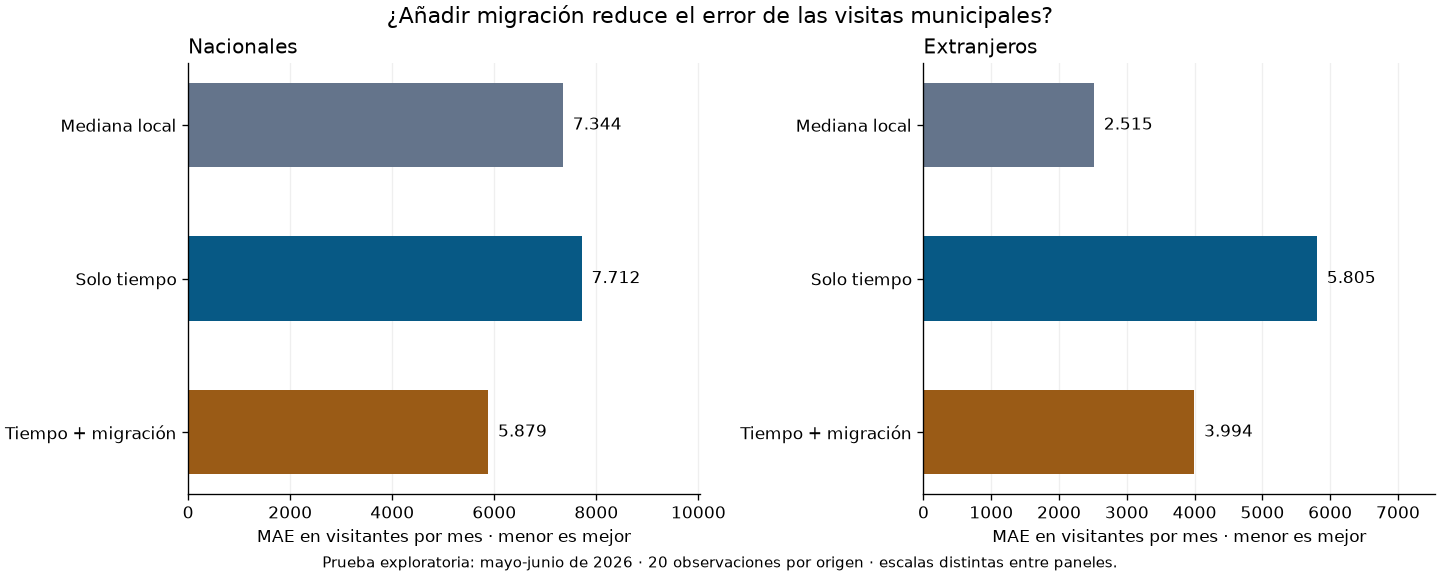

In [43]:
resumen_errores_locales = (
    predicciones_prueba_local.groupby(["origen", "modelo"], as_index=False)
    .agg(observaciones_evaluadas=("error", "size"), MAE=("error_absoluto", "mean"), MSE=("error_cuadrado", "mean"))
)
resumen_errores_locales["RMSE"] = np.sqrt(resumen_errores_locales.pop("MSE"))
conteo_mejoras_locales = (
    comparacion_MAE_local.reset_index().groupby("origen", as_index=False)
    .agg(series_revisadas=("municipio", "size"),
         mejora_al_agregar_migracion=("mejora_al_agregar_migracion", "sum"),
         mejora_frente_mediana=("mejora_frente_mediana", "sum"))
)
display(resumen_errores_locales.round(2))
display(conteo_mejoras_locales)

# Ejemplo de lectura: valores reales y predicciones para el mismo municipio.
ejemplo_predicciones_locales = predicciones_prueba_local.loc[
    predicciones_prueba_local["municipio"].eq("Panajachel")
].pivot(index=["fecha", "origen", "observado"], columns="modelo", values="estimado")
display(ejemplo_predicciones_locales.round(2))

figura_regresion_local, ejes_regresion_local = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
orden_modelos_local = ["Mediana local", "Regresión temporal", "Regresión temporal + migración"]
etiquetas_modelos_local = ["Mediana local", "Solo tiempo", "Tiempo + migración"]
colores_modelos_local = ["#64748B", "#075985", "#9A5B16"]
for eje, origen in zip(ejes_regresion_local, ["Nacionales", "Extranjeros"]):
    valores = resumen_errores_locales.loc[resumen_errores_locales["origen"].eq(origen)].set_index("modelo").reindex(orden_modelos_local)["MAE"]
    eje.barh(range(3), valores.to_numpy(), color=colores_modelos_local, height=0.55)
    eje.set_yticks(range(3), etiquetas_modelos_local)
    eje.invert_yaxis()
    eje.set_xlim(0, float(valores.max()) * 1.3)
    eje.set_xlabel("MAE en visitantes por mes · menor es mejor")
    eje.set_title(origen, loc="left")
    eje.grid(axis="x", alpha=0.2)
    eje.set_axisbelow(True)
    eje.spines[["top", "right"]].set_visible(False)
    for posicion, valor in enumerate(valores):
        eje.text(valor + float(valores.max()) * 0.025, posicion,
                 f"{valor:,.0f}".replace(",", "."), va="center", fontsize=10)
figura_regresion_local.suptitle("¿Añadir migración reduce el error de las visitas municipales?", fontsize=13)
figura_regresion_local.supxlabel("Prueba exploratoria: mayo-junio de 2026 · 20 observaciones por origen · escalas distintas entre paneles.", fontsize=9)
display(figura_regresion_local)
plt.close(figura_regresion_local)


### **5.15. Lectura de la prueba municipal**

Añadir migración redujo el MAE frente a la regresión temporal en 14 de las 20 series: los diez municipios en extranjeros y cuatro en nacionales. Frente a la mediana local, la regresión completa mejoró ocho series: tres de extranjeros y cinco de nacionales. Por tanto, incorporar migración aporta frente a la tendencia ensayada, pero no produce una mejora uniforme frente a una referencia sencilla.

| Origen | Mediana local: MAE | Solo tiempo: MAE | Tiempo y migración: MAE |
|---|---:|---:|---:|
| Nacionales | 7.344,37 | 7.711,55 | 5.878,83 |
| Extranjeros | 2.515,44 | 5.804,62 | 3.993,77 |

En nacionales, la regresión completa tiene el menor MAE agregado de estas tres alternativas, aunque mejora frente a la mediana solo en cinco municipios. Esto muestra por qué un promedio de errores absolutos puede favorecer una alternativa sin que mejore todas las series. En extranjeros, la mediana local mantiene el menor MAE agregado y supera a la regresión completa en siete municipios.

La correlación exploratoria no bastó para anticipar ese resultado: una asociación positiva no garantiza que una regresión extrapole bien la combinación de nivel y tendencia. Con seis meses de ajuste y solo dos de prueba, tampoco se puede afirmar que el comportamiento observado se mantendrá en enero-febrero o elegir automáticamente un método distinto para cada serie por estos dos errores.

La comparación temporal utilizada aquí es una tendencia lineal municipal, no el SARIMA nacional. Los errores nacionales y municipales no se comparan entre sí para declarar un ganador. El modelo completo estima tres coeficientes con seis datos y no se interpreta causalmente.

Se verificaron el corte temporal de seis meses de ajuste y dos de prueba por serie, el escalado con los datos de ajuste y que las variables de predicción no contengan los visitantes reservados. Los modelos tuvieron diseños de rango completo y predicciones finitas y no negativas, sin recortes.

No se han calculado las visitas faltantes de enero-febrero de 2026 ni se han reajustado estos modelos con las dos cantidades locales reservadas. Antes de elegir la reconstrucción, se discutirá el alcance de esta mejora y las limitaciones de la prueba; no se inicia otra búsqueda automáticamente.


### **5.16. Regresiones municipales seleccionadas**

Se adopta la regresión lineal con tiempo y migración para los dos orígenes. Cada municipio tendrá un ajuste para nacionales y otro para extranjeros: veinte ajustes independientes de una misma estructura, no dos regresiones globales que mezclen todos los municipios.

Cada ajuste estima un nivel de referencia, un coeficiente para el paso de los meses y otro para la migración observada. Se conserva el calendario real, con enero-febrero como meses sin visitas observadas. Nacionales y extranjeros siguen separados, y los registros sin país no se asignan a ninguno de los dos grupos.

La decisión prioriza una formulación ajustada de pocos coeficientes para una historia municipal corta, que permite incorporar migración. No significa que haya superado siempre a la referencia: en la prueba, la mediana local tuvo menor MAE agregado para extranjeros y la regresión completa no fue la mejor en todos los municipios. Esa evidencia se conserva.

Ahora se reajustan las regresiones con los ocho meses donde coinciden ambas fuentes: septiembre-diciembre de 2025 y marzo-junio de 2026. Se incorporan los dos meses de la prueba previa después de fijar la estructura; no se conservan como un test nuevo para estos mismos coeficientes. Julio-agosto siguen en la tabla local, pero no se usan en el ajuste condicionado porque no hay migración observada para esas fechas.

Los MAE y RMSE anteriores corresponden al ejercicio de seis meses de ajuste y dos de prueba. Se mantienen como evidencia exploratoria y no se sustituyen por el error dentro de los ocho meses reajustados. Con las visitas faltantes de enero-febrero no puede calcularse un error real, porque no se dispone de sus observaciones.


In [44]:
columnas_modelo_municipal = ["paso_temporal", "ingresos_migratorios_observados"]
modelos_municipales_finales = {}
filas_coeficientes_finales = []
filas_controles_finales = []
residuos_municipales_finales = []
metricas_previas_municipales = metricas_prueba_local.loc[
    metricas_prueba_local["modelo"].eq("Regresión temporal + migración")
].set_index(["municipio", "origen"])

for (municipio, origen), grupo in base_regresion_municipal.groupby(["municipio", "origen"]):
    grupo = grupo.sort_values("fecha").copy()
    assert len(grupo) == 8 and not grupo["fecha"].duplicated().any()
    assert not grupo["fecha"].isin(pd.DatetimeIndex(["2026-01-01", "2026-02-01"])).any()
    entradas = grupo[columnas_modelo_municipal].astype(float)
    objetivo = grupo["visitantes"].to_numpy(dtype=float)
    assert np.isfinite(entradas.to_numpy()).all() and np.isfinite(objetivo).all()

    modelo_final = make_pipeline(StandardScaler(), LinearRegression())
    modelo_final.fit(entradas, objetivo)
    modelos_municipales_finales[(municipio, origen)] = modelo_final
    escalador_final = modelo_final.named_steps["standardscaler"]
    regresion_final = modelo_final.named_steps["linearregression"]
    matriz_final = np.column_stack([np.ones(len(grupo)), escalador_final.transform(entradas)])
    rango_final = int(np.linalg.matrix_rank(matriz_final))
    assert rango_final == 3
    assert int(escalador_final.n_samples_seen_) == 8
    coeficientes_originales = regresion_final.coef_ / escalador_final.scale_
    intercepto_original = float(regresion_final.intercept_ - np.sum(
        regresion_final.coef_ * escalador_final.mean_ / escalador_final.scale_
    ))
    assert np.isfinite(coeficientes_originales).all() and np.isfinite(intercepto_original)
    filas_coeficientes_finales.append({
        "municipio": municipio, "origen": origen,
        "intercepto": intercepto_original,
        "coeficiente_tiempo": coeficientes_originales[0],
        "coeficiente_migracion": coeficientes_originales[1],
    })
    evidencia_previa = metricas_previas_municipales.loc[(municipio, origen)]
    filas_controles_finales.append({
        "municipio": municipio, "origen": origen,
        "meses_ajuste_final": len(grupo), "coeficientes_estimados": rango_final,
        "primer_mes_ajuste": grupo["fecha"].min(), "ultimo_mes_ajuste": grupo["fecha"].max(),
        "MAE_prueba_previa_6_2": evidencia_previa["MAE"],
        "RMSE_prueba_previa_6_2": evidencia_previa["RMSE"],
    })
    estimado_entrenamiento = modelo_final.predict(entradas)
    assert np.isfinite(estimado_entrenamiento).all()
    for fecha, real, estimado in zip(grupo["fecha"], objetivo, estimado_entrenamiento):
        residuos_municipales_finales.append({
            "municipio": municipio, "origen": origen, "fecha": fecha,
            "observado": real, "ajustado_en_entrenamiento": estimado,
            "residuo": real - estimado,
        })

coeficientes_municipales_finales = pd.DataFrame(filas_coeficientes_finales)
controles_municipales_finales = pd.DataFrame(filas_controles_finales)
residuos_municipales_finales = pd.DataFrame(residuos_municipales_finales)
assert len(modelos_municipales_finales) == 20
assert set(modelos_municipales_finales) == {(municipio, origen) for municipio in MUNICIPIOS for origen in ["Nacionales", "Extranjeros"]}
display(controles_municipales_finales.round(2))
display(coeficientes_municipales_finales.round(6))


,municipio,origen,meses_ajuste_final,coeficientes_estimados,primer_mes_ajuste,ultimo_mes_ajuste,MAE_prueba_previa_6_2,RMSE_prueba_previa_6_2
0,Panajachel,Extranjeros,8,3,2025-09-01,2026-06-01,9441.51,9830.55
1,Panajachel,Nacionales,8,3,2025-09-01,2026-06-01,2225.59,2661.48
2,San Antonio Palopo,Extranjeros,8,3,2025-09-01,2026-06-01,2192.13,2349.55
3,San Antonio Palopo,Nacionales,8,3,2025-09-01,2026-06-01,4740.02,4989.36
4,San Juan La Laguna,Extranjeros,8,3,2025-09-01,2026-06-01,4538.73,4776.31
5,San Juan La Laguna,Nacionales,8,3,2025-09-01,2026-06-01,12752.80,17502.20
6,San Lucas Toliman,Extranjeros,8,3,2025-09-01,2026-06-01,522.29,555.34
7,San Lucas Toliman,Nacionales,8,3,2025-09-01,2026-06-01,7884.37,8991.63
8,San Marcos La Laguna,Extranjeros,8,3,2025-09-01,2026-06-01,4617.56,4927.44
9,San Marcos La Laguna,Nacionales,8,3,2025-09-01,2026-06-01,1638.36,1660.18


,municipio,origen,intercepto,coeficiente_tiempo,coeficiente_migracion
0,Panajachel,Extranjeros,-8262.698410,807.636333,0.083113
1,Panajachel,Nacionales,116749.609037,1456.432838,0.313464
2,San Antonio Palopo,Extranjeros,-780.429671,405.902007,0.013268
3,San Antonio Palopo,Nacionales,47012.033059,3918.553754,-0.007436
4,San Juan La Laguna,Extranjeros,-6031.811021,268.704436,0.056417
5,San Juan La Laguna,Nacionales,43928.318405,1710.434395,0.134371
6,San Lucas Toliman,Extranjeros,-2676.915988,79.112259,0.023003
7,San Lucas Toliman,Nacionales,101673.681157,895.425194,0.094101
8,San Marcos La Laguna,Extranjeros,-2608.458864,465.389199,0.029018
9,San Marcos La Laguna,Nacionales,64243.427850,-831.030108,-0.059607


### **5.17. Estado de los ajustes municipales**

Quedan preparadas diez regresiones para nacionales y diez para extranjeros, todas con ocho observaciones y tres coeficientes. Las entradas se escalaron con los datos de ajuste y los diseños tienen rango completo. Los modelos están disponibles en `modelos_municipales_finales` al ejecutar el notebook; los coeficientes en unidades originales y los controles quedan visibles en las tablas.

Los coeficientes de migración no se interpretan como porcentajes de visitantes del país que llegan al municipio ni como efectos causales. La estructura puede producir cantidades diferentes por mes y municipio, pero todavía deben revisarse las salidas que genere para el hueco.

No se calcularon ni guardaron estimaciones de enero y febrero en este paso. La fuente procesada conserva sus datos originales y las métricas de la prueba municipal previa permanecen sin cambios.


## **6. Estimación de enero y febrero de 2026**

### **6.1. Cálculo de las visitas faltantes**

Se aplica cada una de las veinte regresiones ajustadas en la sección 5.16. Para cada mes, el modelo recibe su posición en el calendario y los ingresos migratorios observados. Enero ocupa la posición cuatro y febrero la cinco, contando desde septiembre de 2025 como posición cero.

Se obtienen dos estimaciones para cada municipio y origen. Los decimales se conservan en el cálculo y se muestran redondeados en las tablas para facilitar la lectura.


In [45]:
fechas_estimacion = pd.DatetimeIndex(["2026-01-01", "2026-02-01"], name="fecha")
entradas_estimacion = pd.DataFrame({
    "paso_temporal": (fechas_estimacion.year - 2025) * 12 + fechas_estimacion.month - 9,
    "ingresos_migratorios_observados": referencia_por_fecha.reindex(fechas_estimacion).to_numpy(dtype=float),
}, index=fechas_estimacion)
assert np.isfinite(entradas_estimacion.to_numpy()).all()
assert not tabla_municipal["fecha"].isin(fechas_estimacion).any()

filas_estimadas = []
for (municipio, origen), modelo in modelos_municipales_finales.items():
    predicciones = modelo.predict(entradas_estimacion[columnas_modelo_municipal])
    for fecha, visitantes in zip(fechas_estimacion, predicciones):
        filas_estimadas.append({
            "fecha": fecha, "municipio": municipio, "origen": origen,
            "visitantes": visitantes, "tipo_dato": "Estimado",
        })

estimaciones_municipales = pd.DataFrame(filas_estimadas)
assert len(estimaciones_municipales) == 40
assert not estimaciones_municipales.duplicated(["fecha", "municipio", "origen"]).any()
assert estimaciones_municipales.groupby(["municipio", "origen"])["fecha"].nunique().eq(2).all()
assert np.isfinite(estimaciones_municipales["visitantes"]).all()
assert estimaciones_municipales["visitantes"].ge(0).all()

tabla_estimaciones = estimaciones_municipales.pivot(
    index="municipio", columns=["origen", "fecha"], values="visitantes",
)
tabla_estimaciones.columns = [
    (origen, "Enero" if fecha.month == 1 else "Febrero")
    for origen, fecha in tabla_estimaciones.columns
]
display(entradas_estimacion.round(2))
display(tabla_estimaciones.round(2))


,paso_temporal,ingresos_migratorios_observados
fecha,,
2026-01-01,4,300664.08
2026-02-01,5,236844.11


,"(Extranjeros, Enero)","(Extranjeros, Febrero)","(Nacionales, Enero)","(Nacionales, Febrero)"
municipio,,,,
Panajachel,19956.92,15460.30,216822.75,198273.91
San Antonio Palopo,4832.31,4391.47,60450.46,64843.59
San Juan La Laguna,12005.49,8673.68,91170.73,84305.58
San Lucas Toliman,4555.61,3166.69,133548.24,128438.13
San Marcos La Laguna,7977.72,6591.19,42997.76,45970.82
San Pablo La Laguna,6296.61,4492.99,54386.37,50377.59
San Pedro La Laguna,19601.09,14765.61,149649.54,136667.75
Santa Catarina Palopo,5691.55,4333.98,67910.09,64372.50
Santa Cruz La Laguna,1912.66,1227.68,12448.78,11274.19


### **6.2. Serie mensual con las estimaciones identificadas**

Se incorporan las estimaciones a la tabla mensual con la columna `tipo_dato`. Cada serie queda con diez meses observados y dos estimados. En el ejemplo de Panajachel, los triángulos y el trazo punteado identifican enero y febrero. Cada origen se muestra con su propia escala.


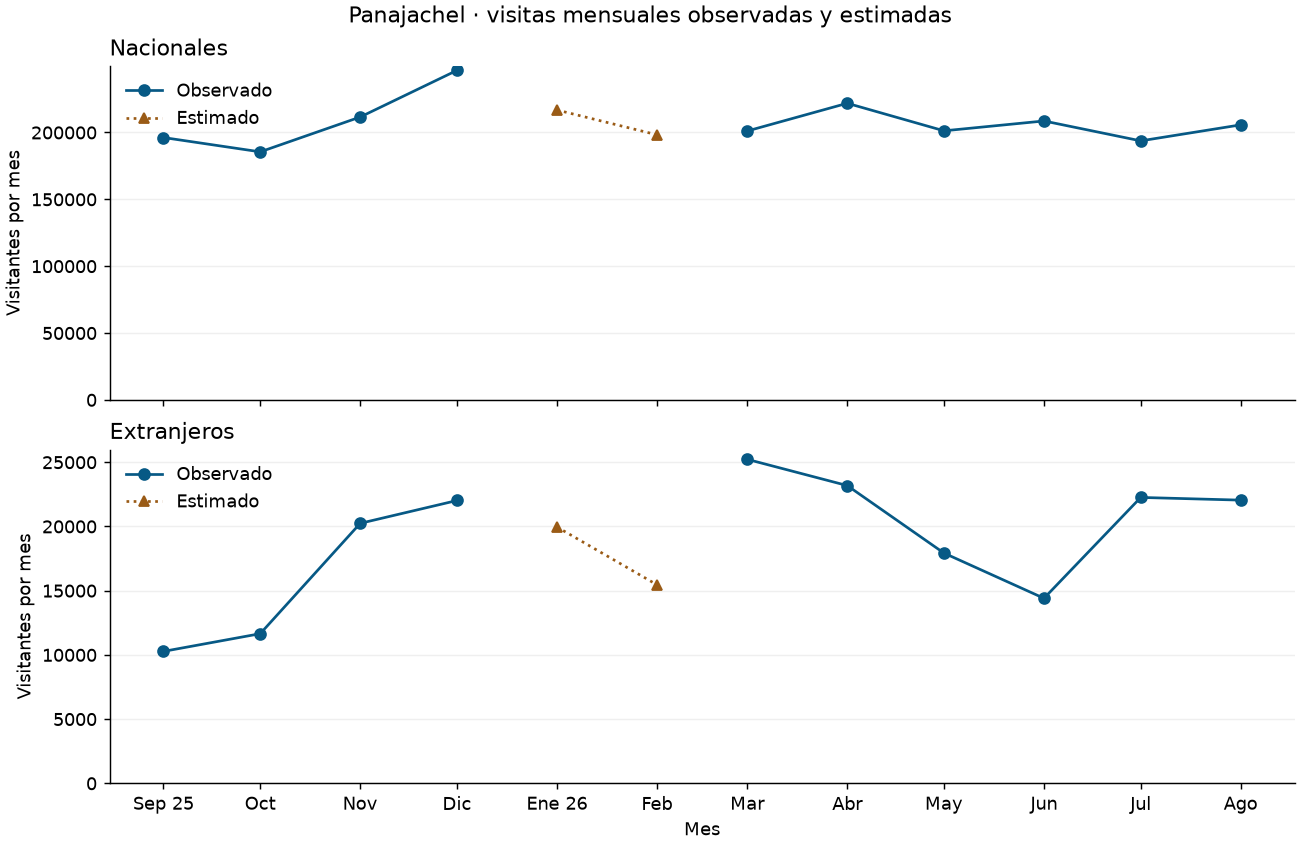

In [46]:
observaciones_municipales = tabla_municipal.assign(tipo_dato="Observado")
serie_municipal_completa = pd.concat(
    [observaciones_municipales, estimaciones_municipales], ignore_index=True,
).sort_values(["municipio", "origen", "fecha"]).reset_index(drop=True)
assert len(serie_municipal_completa) == 240
assert not serie_municipal_completa.duplicated(["fecha", "municipio", "origen"]).any()
assert serie_municipal_completa.groupby(["municipio", "origen"])["fecha"].nunique().eq(12).all()

figura_estimacion_municipal, ejes = plt.subplots(
    2, 1, figsize=(10, 6.5), sharex=True, layout="constrained",
)
for eje, origen in zip(ejes, ["Nacionales", "Extranjeros"]):
    serie = serie_municipal_completa.loc[
        serie_municipal_completa["municipio"].eq("Panajachel")
        & serie_municipal_completa["origen"].eq(origen)
    ].set_index("fecha")
    observados = serie["visitantes"].where(serie["tipo_dato"].eq("Observado"))
    estimados = serie["visitantes"].where(serie["tipo_dato"].eq("Estimado"))
    eje.plot(serie.index, observados.to_numpy(dtype=float, na_value=np.nan),
             color="#075985", marker="o", label="Observado")
    eje.plot(serie.index, estimados.to_numpy(dtype=float, na_value=np.nan),
             color="#9A5B16", linestyle=":", marker="^", label="Estimado")
    eje.set_title(origen, loc="left")
    eje.set_ylabel("Visitantes por mes")
    eje.set_ylim(bottom=0)
    eje.grid(axis="y", alpha=0.2)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(frameon=False, loc="upper left")
ejes[-1].set_xticks(calendario_municipal)
ejes[-1].set_xticklabels(
    ["Sep 25", "Oct", "Nov", "Dic", "Ene 26", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago"],
)
ejes[-1].set_xlabel("Mes")
figura_estimacion_municipal.suptitle("Panajachel · visitas mensuales observadas y estimadas")
display(figura_estimacion_municipal)
plt.close(figura_estimacion_municipal)


### **6.3. Alcance de las estimaciones**

Las cantidades de enero y febrero dependen de la relación aprendida en ocho meses coincidentes. La migración aporta una referencia de ingresos internacionales. Su uso para estimar visitas de nacionales supone que esa actividad aporta información sobre la movilidad interna.

Los errores de la sección 5.15 provienen de mayo y junio de 2026. Enero y febrero carecen de visitas observadas con las cuales medir el error directamente. En la prueba de extranjeros, la mediana local obtuvo menor MAE que la regresión. Las estimaciones se presentan por municipio y origen con esa limitación.
